# Figures for Paper

In [1]:

import os 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.io import loadmat


from pynav import QAgent, TwoQAgent

actions = {
    0 : np.asarray([ 1, 0], dtype=np.int32), 
    1 : np.asarray([-1, 0], dtype=np.int32), 
    2 : np.asarray([0,  1], dtype=np.int32), 
    3 : np.asarray([0, -1], dtype=np.int32) 
}

settings = ['dense', 'middle', 'sparse', 'sparser']

box_colors = [
    '#4D7F8D',
    '#D6833B',
    '#3E6F1D',
    '#515151'
]


median_colors = [
    '#00eff1',
    '#995555',
    'lightgreen',
    '#ffffff'
]



q_colors = [
    '#39aafa',
    '#fa3371'
]



mu_G_pomdp, std_G_pomdp = [0.770 , 0.766, 0.744, 0.733], [ 0.001,  0.001,  0.001,  0.001]
mu_speed_pomdp, std_speed_pomdp = [ 0.900, 0.885, 0.845, 0.837], [ 0.002,  0.002,  0.002,  0.002]
mu_conv_pomdp, std_conv_pomdp = [ 0.9996, 0.9996, 0.9996, 0.9996, 0.9996], [ 0.00,  0.00,  0.00,  0.00]



action_labels = ['up', 'down', 'right', 'left']
data_labels = ['Dense', 'Middle', 'Sparse', 'Sparser']

cmaps = ['Blues', 'Oranges', 'Greens', 'Greys']

main_dir = "./paper_plots"
DATA_DIRECTORY =  "/storage/rando/data" # "INSERT YOUR DATA DIRECTORY HERE"
results_dir = "/storage/rando/pynav_results_new/" # "INSERT YOUR RESULTS DIRECTORY HERE"

os.makedirs(f"{main_dir}/general", exist_ok=True)

for path_name in  ['single_Q', 'two_Q', 'two_single_Q']:
  for type_name in ['trajectories', 'characterization', 'performance']:
    os.makedirs(f"{main_dir}/{path_name}/{type_name}", exist_ok=True)
os.makedirs(f"{main_dir}/two_Q/single_vs_two", exist_ok=True)



## Data

In [2]:
data = np.load(f"{DATA_DIRECTORY}/nose_data_27_123.npy") # replace with your data path
noise_thresholds = [1e-6, 3e-6, 5e-6, 7e-6]
data_environments= {}
start_regions = {}


for (i, n_thr) in enumerate(noise_thresholds):
    new_data = data.copy()
    new_data[new_data < n_thr] = 0.0#1e-20
    data_environments[n_thr] = new_data
    start_region = np.any(data >= n_thr, axis=0) 
    start_regions[n_thr] = (start_region / np.sum(start_region))#.ravel()


/tmp/ipykernel_1213209/4007360371.py:10: RuntimeWarning: divide by zero encountered in log10
  log_data = np.log10(data[1250, :, :])
/tmp/ipykernel_1213209/4007360371.py:11: RuntimeWarning: divide by zero encountered in log10
  avg_sig = np.log10(np.mean(data, axis=0))


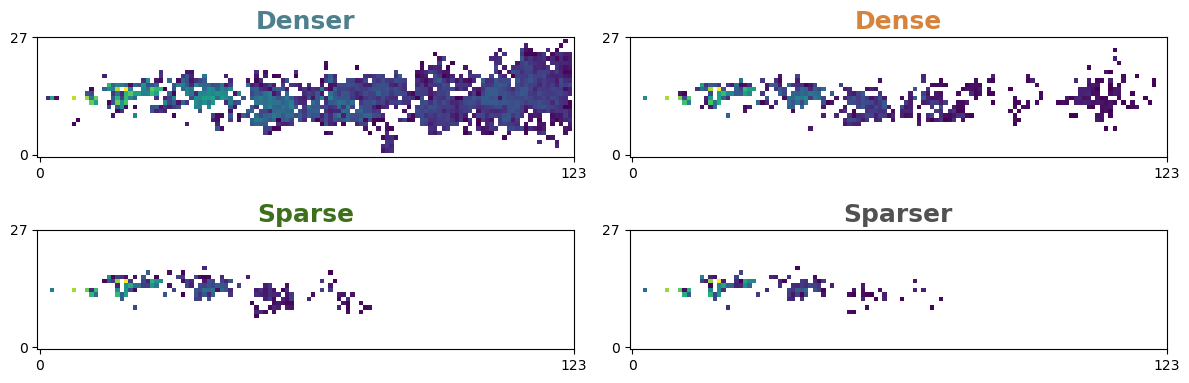

In [3]:
titles = ["Denser", "Dense", "Sparse", "Sparser"]

fig, axes = plt.subplots(2, 2, figsize=(12, 4))


axes = axes.flatten()
for (i, (n_thr, data)) in enumerate(data_environments.items()):
#    axes[i].set_title("{} Plume [$n_t$ = {}]".format(data_labels[i], n_thr), fontsize=16)
    axes[i].set_title(titles[i], fontsize=18, color=box_colors[i], fontweight='bold')
    log_data = np.log10(data[1250, :, :])
    avg_sig = np.log10(np.mean(data, axis=0))
    im = axes[i].imshow(log_data, cmap='viridis', origin='lower', vmax=log_data.max(), rasterized=True)
#    im = axes[i].imshow(avg_sig, cmap='viridis', origin='lower', vmax=log_data.max(), rasterized=True)
#    axes[i].set_xlabel("$X$", fontsize=12)

#    if i == 0:
#      axes[i].set_ylabel("$Y$", fontsize=12)
    axes[i].set_xticks([0, data.shape[2]])
    axes[i].set_yticks([0, data.shape[1]])
#fig.supxlabel("X", fontsize=12)
fig.tight_layout()
#fig.colorbar(im, ax=axes.ravel().tolist(), location='bottom')
fig.savefig(f"{main_dir}/general/signals_2.pdf", bbox_inches='tight')


In [63]:
titles = ["Denser", "Dense", "Sparse", "Sparser"]

for (i, (n_thr, data)) in enumerate(data_environments.items()):
  fig, ax = plt.subplots(1, 1, figsize=(12, 4))

  ax.set_title(titles[i], fontsize=18, color=box_colors[i], fontweight='bold')
  log_data = np.log10(data[1250, :, :])
  avg_sig = np.log10(np.mean(data, axis=0))
  im = ax.imshow(log_data, cmap='viridis', origin='lower', vmax=log_data.max(), rasterized=True)
  ax.set_xticks([0, data.shape[2]])
  ax.set_yticks([0, data.shape[1]])
  #fig.supxlabel("X", fontsize=12)
  fig.tight_layout()
  #fig.colorbar(im, ax=axes.ravel().tolist(), location='bottom')
  fig.savefig(f"{main_dir}/general/signal_{titles[i]}_2.pdf", bbox_inches='tight')
  plt.close(fig)

/tmp/ipykernel_3656404/3382641920.py:7: RuntimeWarning: divide by zero encountered in log10
  log_data = np.log10(data[1250, :, :])
/tmp/ipykernel_3656404/3382641920.py:8: RuntimeWarning: divide by zero encountered in log10
  avg_sig = np.log10(np.mean(data, axis=0))
/tmp/ipykernel_3656404/3382641920.py:7: RuntimeWarning: divide by zero encountered in log10
  log_data = np.log10(data[1250, :, :])
/tmp/ipykernel_3656404/3382641920.py:8: RuntimeWarning: divide by zero encountered in log10
  avg_sig = np.log10(np.mean(data, axis=0))
/tmp/ipykernel_3656404/3382641920.py:7: RuntimeWarning: divide by zero encountered in log10
  log_data = np.log10(data[1250, :, :])
/tmp/ipykernel_3656404/3382641920.py:8: RuntimeWarning: divide by zero encountered in log10
  avg_sig = np.log10(np.mean(data, axis=0))
/tmp/ipykernel_3656404/3382641920.py:7: RuntimeWarning: divide by zero encountered in log10
  log_data = np.log10(data[1250, :, :])
/tmp/ipykernel_3656404/3382641920.py:8: RuntimeWarning: divide b

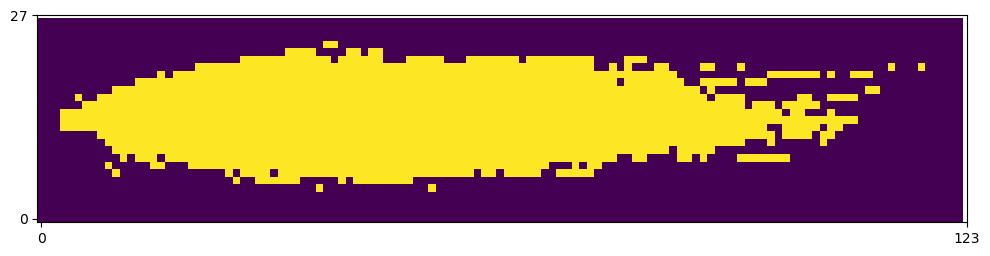

In [64]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
start_region = start_regions[7e-6].copy()
start_region[:, :3] = 0.0
ax.imshow(start_region, cmap='viridis', origin='lower',rasterized=True)    
ax.set_xticks([0, start_region.shape[1]])
ax.set_yticks([0, start_region.shape[0]])
fig.tight_layout()
fig.savefig(f"{main_dir}/general/start_region.pdf", bbox_inches='tight')

## Figure 2

In [3]:
out_path = f"{main_dir}/single_Q"
agent = QAgent(500)

### Figure 2 (a): Structure of a trajectory and examples of dense, middle and sparse trajectories


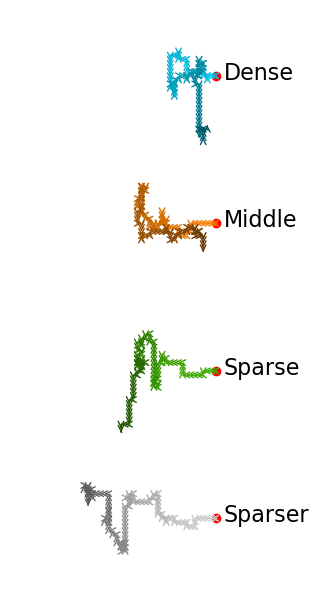

In [4]:


Qs = [
    ('Dense',   f"{results_dir}/single_Q/dense/agent_6299/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"{results_dir}/single_Q/middle/agent_1574/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"{results_dir}/single_Q/sparse/agent_944/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"{results_dir}/single_Q/sparser/agent_944/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(1, 500):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())




    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
#    colormap = cm.get_cmap(box_colors[i])
    plot_steps = 100
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str, rasterized=True )
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ), rasterized=True)

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()
fig.savefig(f"{out_path}/trajectories/sample_trajectories.pdf", bbox_inches='tight')

### Figure 2 (supplemental): All policies

In [67]:
Qs = [
    ('Dense',  f"{results_dir}/single_Q/dense", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', f"{results_dir}/single_Q/middle", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', f"{results_dir}/single_Q/sparse", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser',f"{results_dir}/single_Q/sparser", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]


for (label, main_path, color_rgb) in Qs:
    dirs= os.listdir(main_path)
    n_plots = len(dirs) // 5 # + 1
    fig, ax = plt.subplots(n_plots, 5, figsize=(14, 3*n_plots))


    axes = ax.flatten()
    for i in range(len(dirs)):
        agent.load_q(f"{main_path}/{dirs[i]}/Q_stored/Qfun.npy")
        
        pos = np.array([0, 0])
        ax = axes[i]
        path = [pos.copy()]
        plot_steps = 100
        for j in range(1, plot_steps + 1):
            pos += actions[np.argmax(agent.Q[j])]
            path.append(pos.copy())

        for j in range(plot_steps): 
            ax.plot(path[j][1], path[j][0], '.', ms=0.5, color=((170 - (j+1))/170) * color_rgb, rasterized=True )
            ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='-', color=((170 - (j+1))/170) * color_rgb), rasterized=True)
        ax.plot(path[0][1], path[0][0], 'o', ms=1.0, c='red', label='starting point')
        ax.set_xlim([-50, 5.0])
#        ax.set_ylim([-40, 40.0])
        ax.set_axis_off()
        ax.set_aspect('equal')
    
    # if len(dirs) < len(axes):
    #     for i in range(len(axes) - len(dirs)):
    #         axes[-i-1].set_axis_off()
    fig.subplots_adjust(hspace=0)
    fig.savefig(f"{out_path}/trajectories/single_q_policies_trained_on_{label}.pdf", bbox_inches='tight')
    plt.close(fig)
    print(f"[--] Completed {label}")


[--] Completed Dense
[--] Completed Middle
[--] Completed Sparse
[--] Completed Sparser


### Training Curves

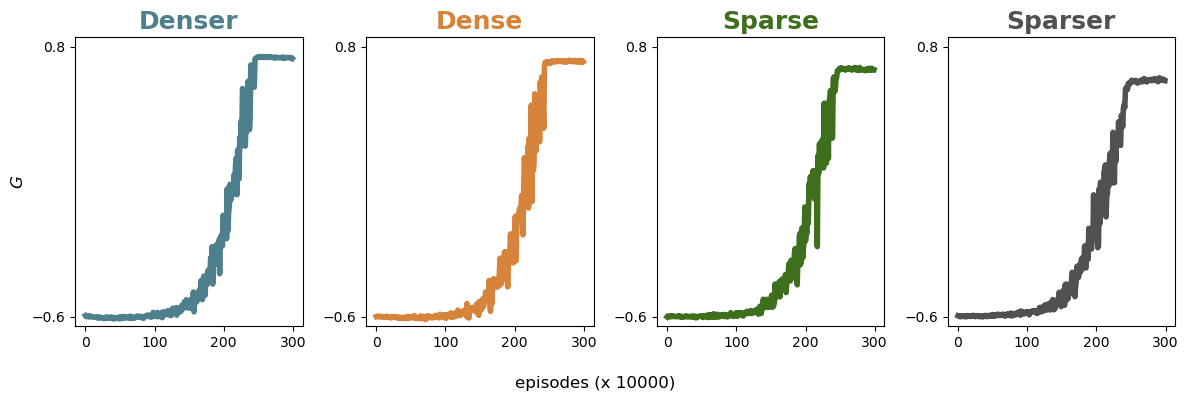

In [85]:
Qs = [
    ('Dense',   f"{results_dir}/single_Q/dense/agent_944", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"{results_dir}/single_Q/middle/agent_1574", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"{results_dir}/single_Q/sparse/agent_1574", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"{results_dir}/single_Q/sparser/agent_944", np.array([0xd2, 0xd2, 0xd2]) / 0xff),

]

delta = 10000
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

axes = axes.flatten()
for (i, (label, main_path, _)) in enumerate(Qs):
  ax = axes[i]
  c_rew = []
  with open(f"{main_path}/training.log", 'r') as f:
    for line in f.readlines():
      c_rew.append(float(line.split(',')[2]))
    avg_crew = []
    for j in range(len(c_rew) // delta):
        avg_crew.append(np.mean(c_rew[j*delta:(j+1)*delta]))
  ax.plot(range(len(avg_crew)), avg_crew, '-', ms=1.0, lw=4, c=box_colors[i], label='cumulative reward')
#  ax.set_xlabel(f"episodes (x {delta})", fontsize=12)
  ax.set_title(titles[i], fontsize=18, color=box_colors[i], fontweight='bold')
  if i == 0:# or i == 2:
      ax.set_ylabel("$G$", fontsize=12)
  ax.set_ylim([-0.65, 0.85])
  ax.set_yticks([-0.6, 0.8])
fig.supxlabel(f"episodes (x {delta})", fontsize=12)
fig.tight_layout()
fig.savefig(f"{out_path}/performance/sample_training_all_signals_1.pdf", bbox_inches='tight')
#plt.close(fig)

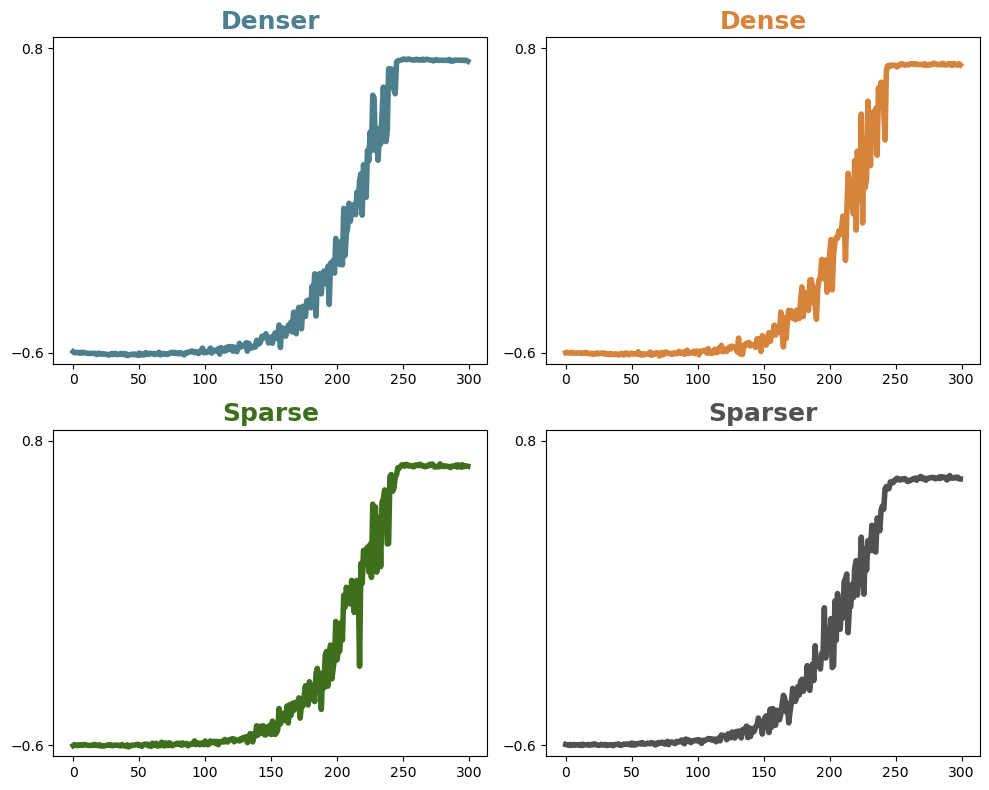

In [111]:
Qs = [
    ('Dense',   f"{results_dir}/single_Q/dense/agent_944", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"{results_dir}/single_Q/middle/agent_1574", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"{results_dir}/single_Q/sparse/agent_1574", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"{results_dir}/single_Q/sparser/agent_944", np.array([0xd2, 0xd2, 0xd2]) / 0xff),

]

delta = 10000
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes = axes.flatten()
for (i, (label, main_path, _)) in enumerate(Qs):
  ax = axes[i]
  c_rew = []
  with open(f"{main_path}/training.log", 'r') as f:
    for line in f.readlines():
      c_rew.append(float(line.split(',')[2]))
    avg_crew = []
    for j in range(len(c_rew) // delta):
        avg_crew.append(np.mean(c_rew[j*delta:(j+1)*delta]))
  ax.plot(range(len(avg_crew)), avg_crew, '-', ms=1.0, lw=4, c=box_colors[i], label='cumulative reward')
#  ax.set_xlabel(f"episodes (x {delta})", fontsize=12)
  ax.set_title(titles[i], fontsize=18, color=box_colors[i], fontweight='bold')
#  if i == 0 or i == 2:
#      ax.set_ylabel("$G$", fontsize=12)
  ax.set_ylim([-0.65, 0.85])
  ax.set_yticks([-0.6, 0.8])
#fig.supxlabel(f"episodes (x {delta})", fontsize=12)
fig.tight_layout()
fig.savefig(f"{out_path}/performance/sample_training_all_signals_2.pdf", bbox_inches='tight')
#plt.close(fig)

In [40]:
Qs = [
    ('Dense',  f"{results_dir}/single_Q/dense", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', f"{results_dir}/single_Q/middle", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', f"{results_dir}/single_Q/sparse", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser',f"{results_dir}/single_Q/sparser", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

delta = 5000

for (idx, (label, main_path, color_rgb)) in enumerate(Qs):
    dirs= os.listdir(main_path)
    n_plots = len(dirs) // 5 # + 1
    fig, ax = plt.subplots(n_plots, 5, figsize=(12,6))


    axes = ax.flatten()
    for i in range(len(dirs)):
      c_rew = []
      with open(f"{main_path}/{dirs[i]}/training.log", 'r') as f:
        for line in f.readlines():
          c_rew.append(float(line.split(',')[2]))
        avg_crew = []
        for j in range(len(c_rew) // delta):
            avg_crew.append(np.mean(c_rew[j*delta:(j+1)*delta]))
        ax = axes[i]
        ax.plot(range(len(avg_crew)), avg_crew, '-', ms=1.0, c=box_colors[idx], label='cumulative reward')

#        ax.set_xlim([-50, 5.0])
#        ax.set_ylim([-40, 40.0])
#        ax.set_axis_off()
#        ax.set_aspect('equal')
    
    # if len(dirs) < len(axes):
    #     for i in range(len(axes) - len(dirs)):
    #         axes[-i-1].set_axis_off()
#    fig.subplots_adjust(hspace=0)
    fig.savefig(f"{out_path}/performance/all_training_{label}.pdf", bbox_inches='tight')
    plt.close(fig)
    print(f"[--] Completed {label}")


[--] Completed Dense
[--] Completed Middle
[--] Completed Sparse
[--] Completed Sparser


# Geometry of Single-Q Policies (Figure 2 panel b)

In [6]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
base_dir = "/storage/rando/pynav_results_new/single_Q"

tr_max_void = [[], [], [], []]
tr_mean_void = [[], [], [], []]

tr_max_steps = [[], [], [], []]
tr_mean_steps = [[], [], [], []]


tr_max_state =  [[], [], [], []]
tr_mean_state =  [[], [], [], []]

delta = 500

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        with open(f"{base_dir}/{setting}/agent_{seed}/training.log", 'r') as f:
            num_void_steps, num_steps = [], []
            for line in f.readlines()[-delta:]:
                num_void_steps.append(int(line.split(',')[-1]))
                num_steps.append(int(line.split(',')[-2]))
            
            tr_max_void[i].append(np.max(num_void_steps))
            tr_mean_void[i].append(np.mean(num_void_steps))
            tr_max_steps[i].append(np.max(num_steps))
            tr_mean_steps[i].append(np.mean(num_steps))


        tr_states = np.load(f"{base_dir}/{setting}/agent_{seed}/training_max_void_lengths.npy")
        tr_max_state[i].append(np.max(tr_states[-delta:]))
        tr_mean_state[i].append(np.mean(tr_states[-delta:]))

    print(f"[--] Completed setting {setting}")



[--] Completed setting dense
[--] Completed setting middle
[--] Completed setting sparse
[--] Completed setting sparser


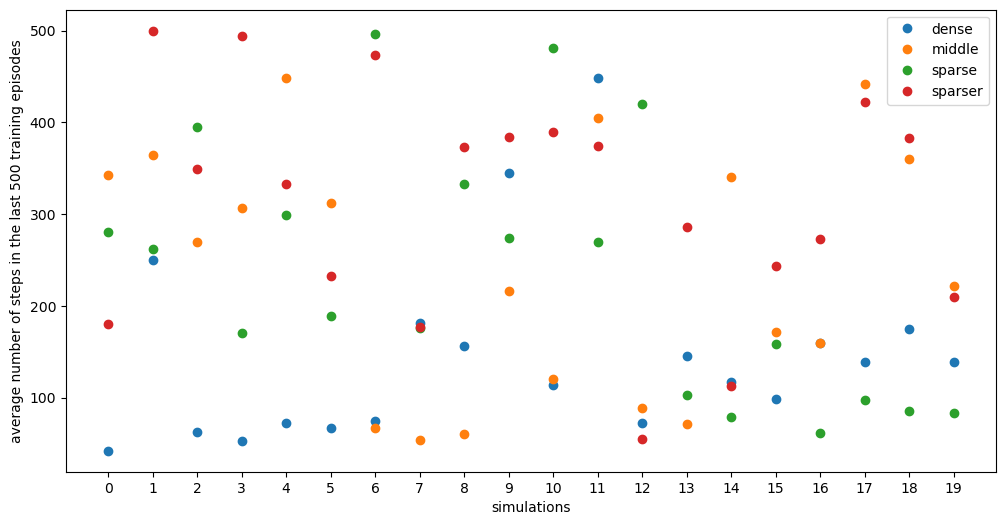

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
for i in range(len(settings)):
    mu = np.array(tr_max_state[i])
    ax.plot(range(mu.shape[0]), mu, 'o', lw=3, label=settings[i], rasterized=True)
    
ax.set_xticks(range(0, 20))
    
ax.set_xlabel("simulations")
ax.set_ylabel(f"average number of steps in the last {delta} training episodes")
    
ax.legend()

In [8]:
def compute_surge_length(Q_file, num_accepted_steps = 2, count_from = 1, count_to = None):
    agent.load_q(Q_file)
#    print(agent.Q.shape)
    num_left = 0
    num_updown = 0
    count_to = agent.Q.shape[0] if count_to is None else count_to
    for i in range(count_from, count_to):
        if np.argmax(agent.Q[i]) == 3:
            num_left += 1
        if np.argmax(agent.Q[i]) == 0 or np.argmax(agent.Q[i]) ==1:
            num_updown += 1
        else:
            num_updown = 0
        if num_updown >= num_accepted_steps:
            break 
    return max(num_left  - num_accepted_steps, 0)

def compute_backtracking_length(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    max_pos = (0, 0, pos)
    for i in range(count_from, avg_void+1):
        pos += actions[np.argmax(agent.Q[i])]
        if max_pos[1] > pos[1]:
            max_pos = (i, pos[1], pos)
            
    back_pos = max_pos[2]
    pos = max_pos[2]
    for i in range(max_pos[0], avg_void + 1):
        pos += actions[np.argmax(agent.Q[i])]
        if back_pos[1] < pos[1]:
            back_pos = (i, pos[1], pos)
        
    return abs(back_pos[1] - max_pos[1])


def compute_backtracking_init_time(Q_file, avg_void, acceptance_steps = 2, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    num_right = 0
    for i in range(count_from, avg_void+1):
        if np.argmax(agent.Q[i]) == 2:
            num_right += 1
        elif np.argmax(agent.Q[i]) == 3:
            num_right = 0 
        if num_right > acceptance_steps:
            break
    return max(i - acceptance_steps - count_from, 0)


def compute_search_length(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    max_pos = 0
    for i in range(count_from, avg_void+1):
        pos += actions[np.argmax(agent.Q[i])]
        max_pos = min(pos[1], max_pos)
    return abs(max_pos)

def compute_cast_width(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    max_pos = 0.0
    min_pos = 0.0
    pos = np.zeros(2)
    for i in range(count_from, avg_void +1):
        pos += actions[np.argmax(agent.Q[i])]
        max_pos = max(pos[0], max_pos, 0)
        min_pos = min(pos[0], min_pos, 0)
    return max_pos + abs(min_pos)




In [9]:

metric_names = ["mean_state", "max_state", "mean_void", "max_void", "entire_traj"]
metrics = [tr_mean_state, tr_max_state, tr_mean_void, tr_max_void, 500]


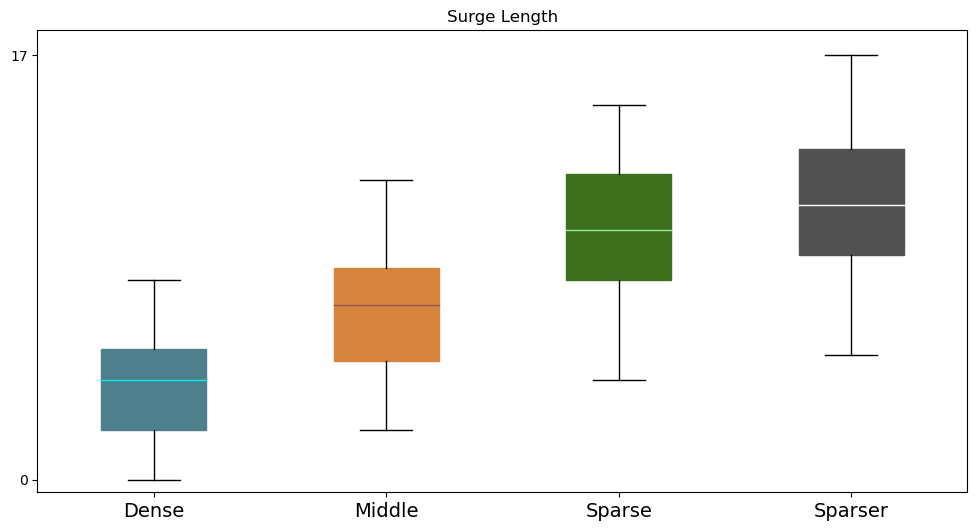

In [10]:


surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", num_accepted_steps=3))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_ylim([-0.5, 18])
ax.set_yticks([0.0, 17.0])

ax.set_title("Surge Length")
ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/surge_length.pdf", bbox_inches='tight')



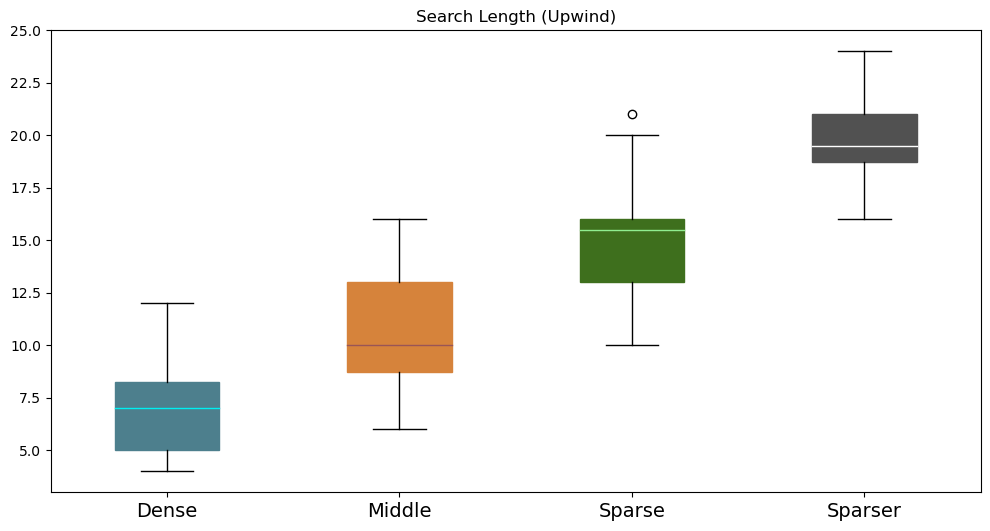

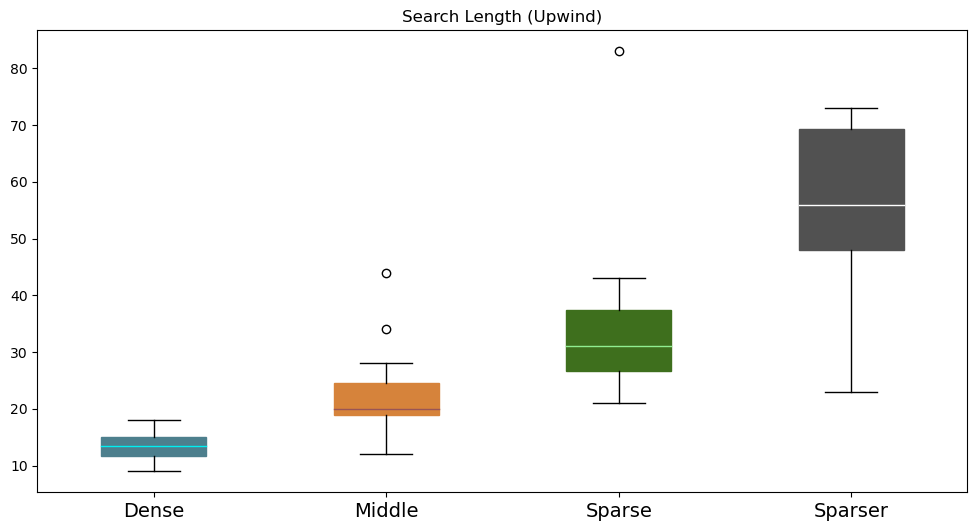

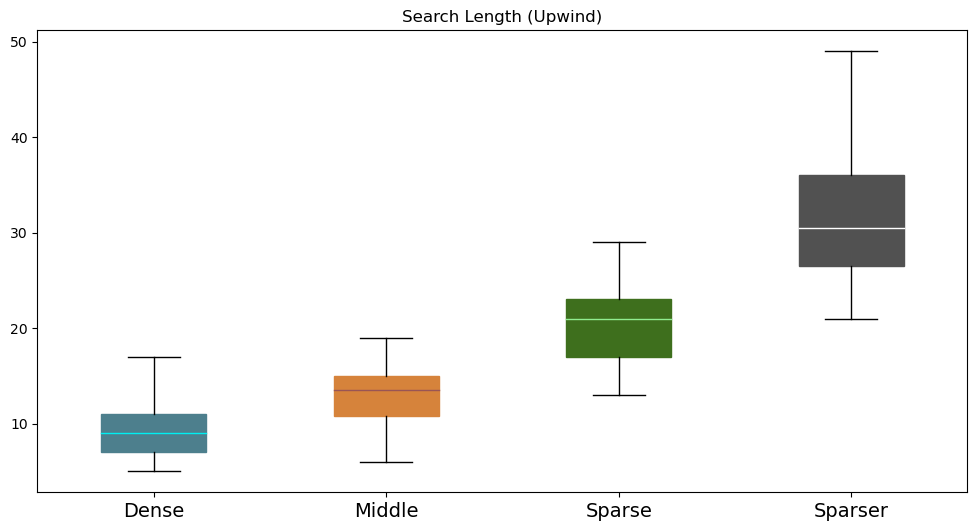

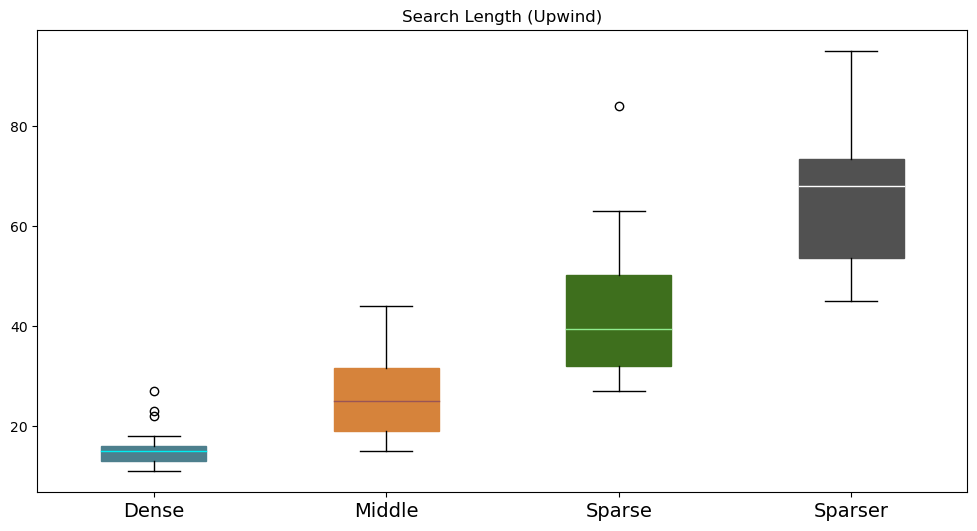

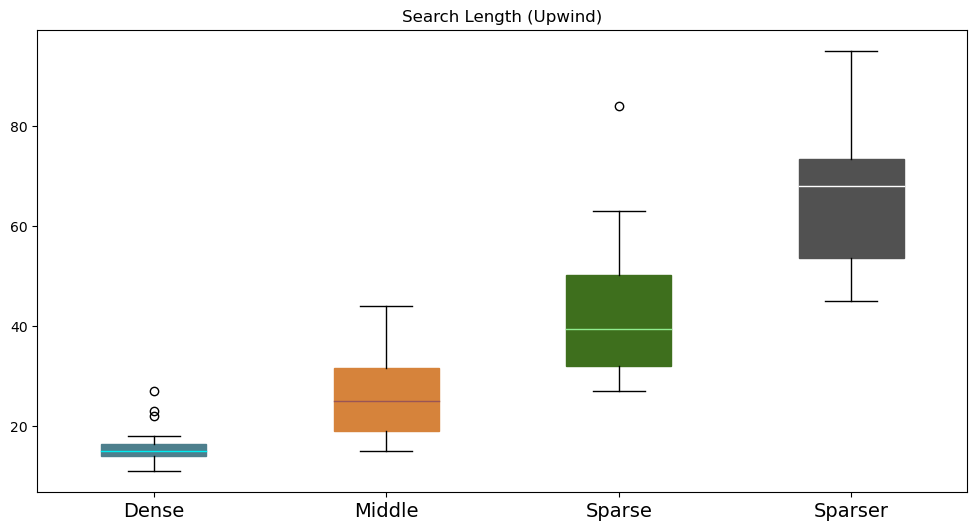

In [11]:

for met,met_name in zip(metrics, metric_names):

	search_len = [[], [], [], []]
	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
					else:
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(search_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title("Search Length (Upwind)")
	ax.set_xticklabels(data_labels, fontsize=14)

	fig.savefig(f"{out_path}/characterization/search_length_{met_name}.pdf", bbox_inches='tight')




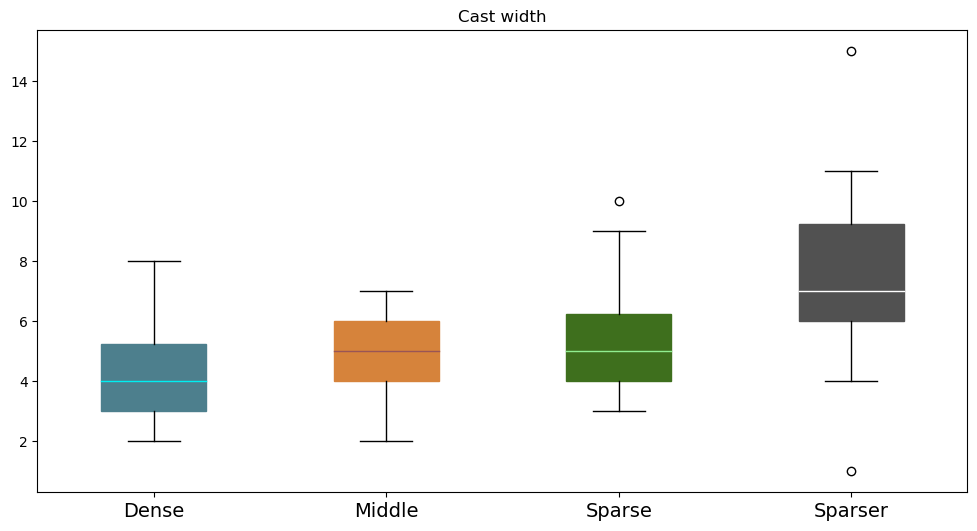

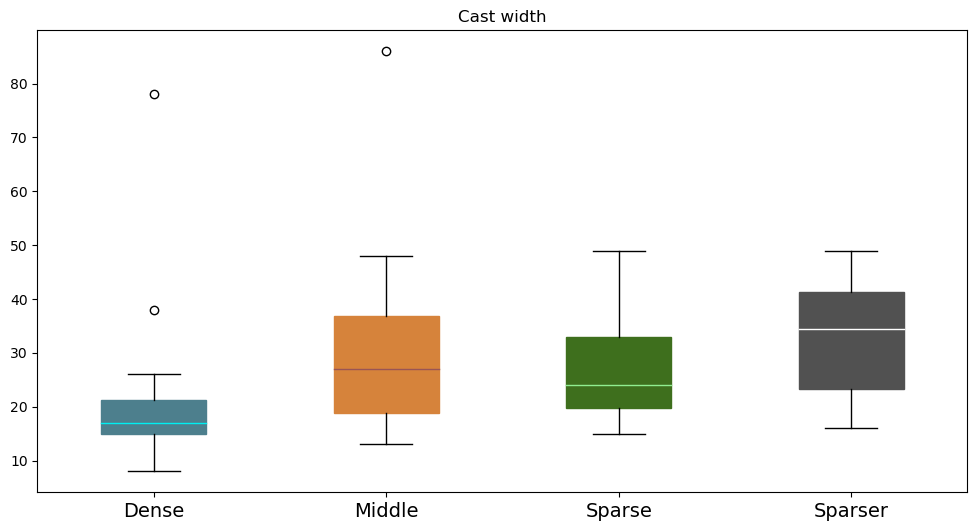

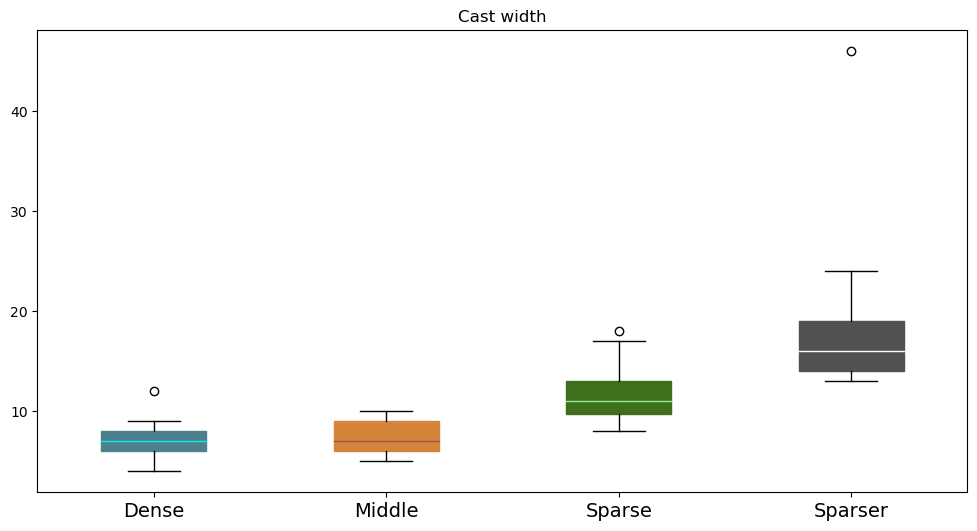

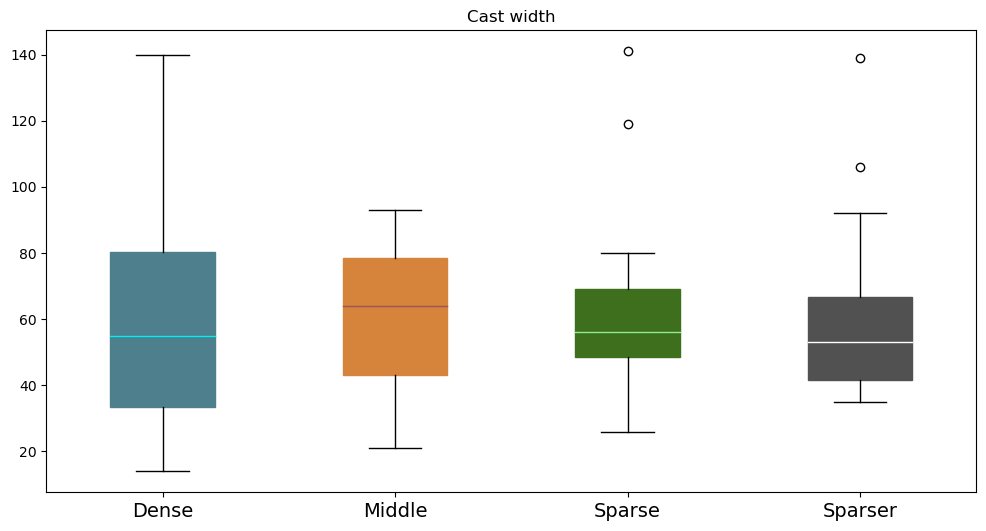

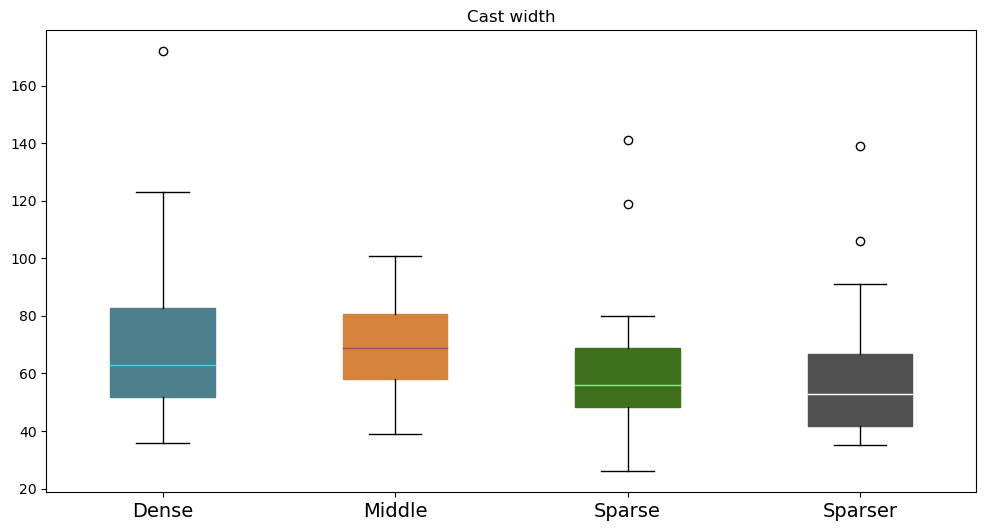

In [12]:



for met,met_name in zip(metrics, metric_names):
	cast_width = [[], [], [], []]

	for (i, setting) in enumerate(settings):
		for (j, seed) in enumerate(agent_seeds):
						if met_name == 'entire_traj':
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
						else:
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 



	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(cast_width, patch_artist=True)

	for i in range(len(b['boxes'])):
		b['boxes'][i].set_color(box_colors[i])
		b['medians'][i].set_color(median_colors[i])


	ax.set_title("Cast width")
	ax.set_xticklabels(data_labels, fontsize=14)
	fig.savefig(f"{out_path}/characterization/cast_width_{met_name}.pdf", bbox_inches='tight')
			




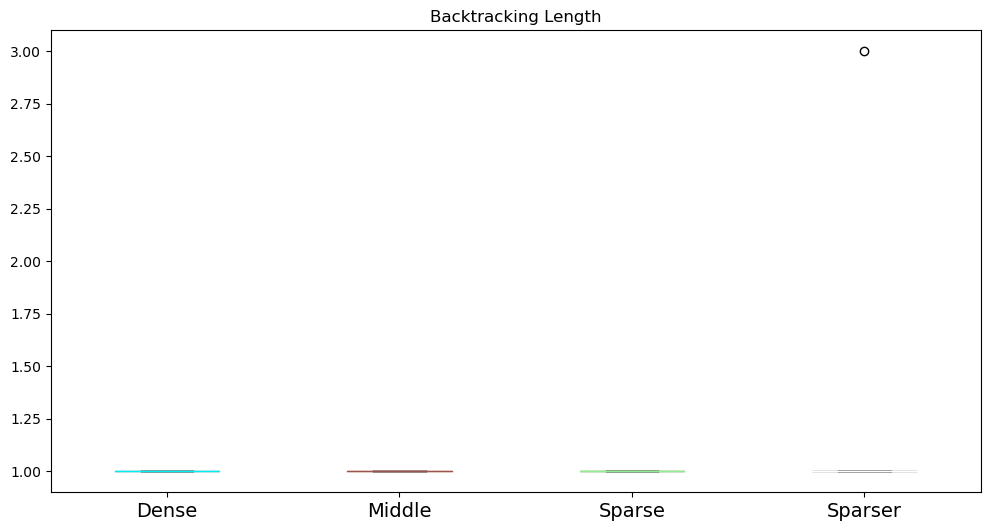

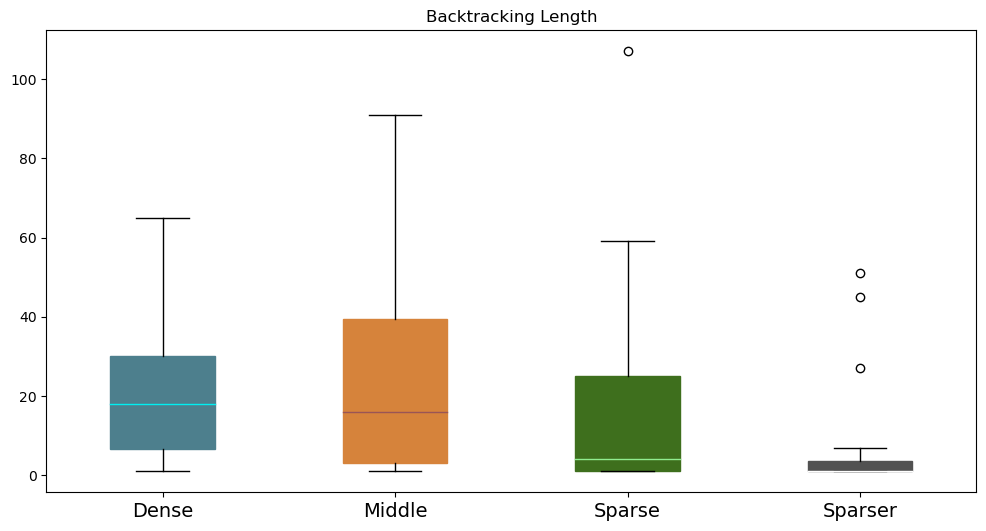

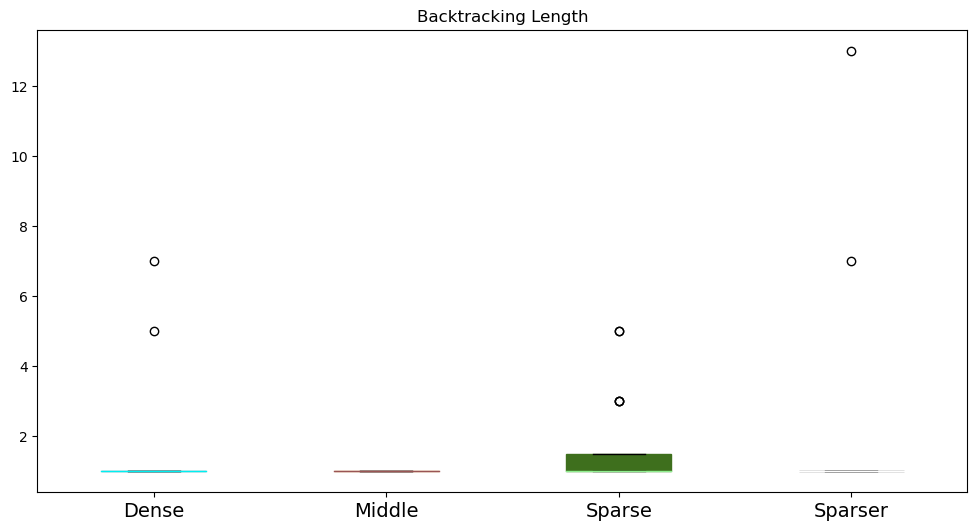

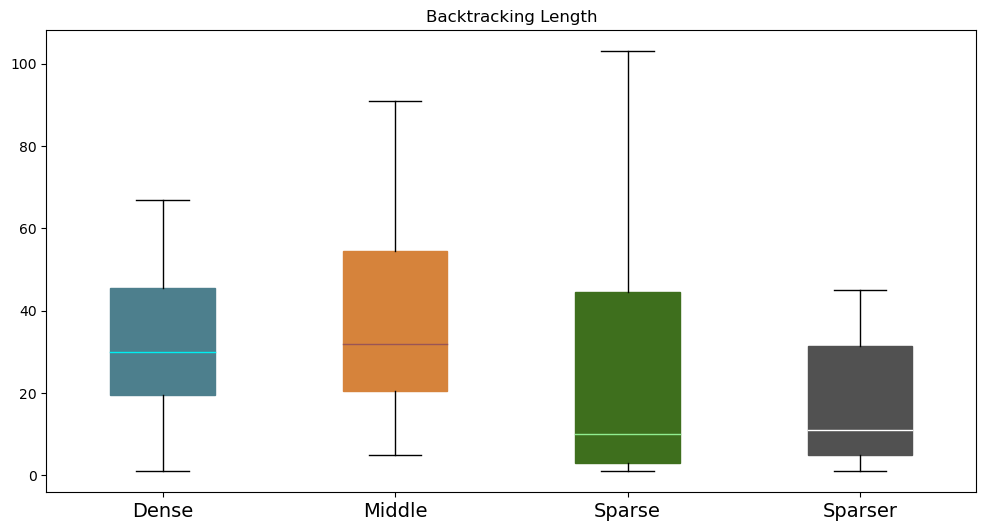

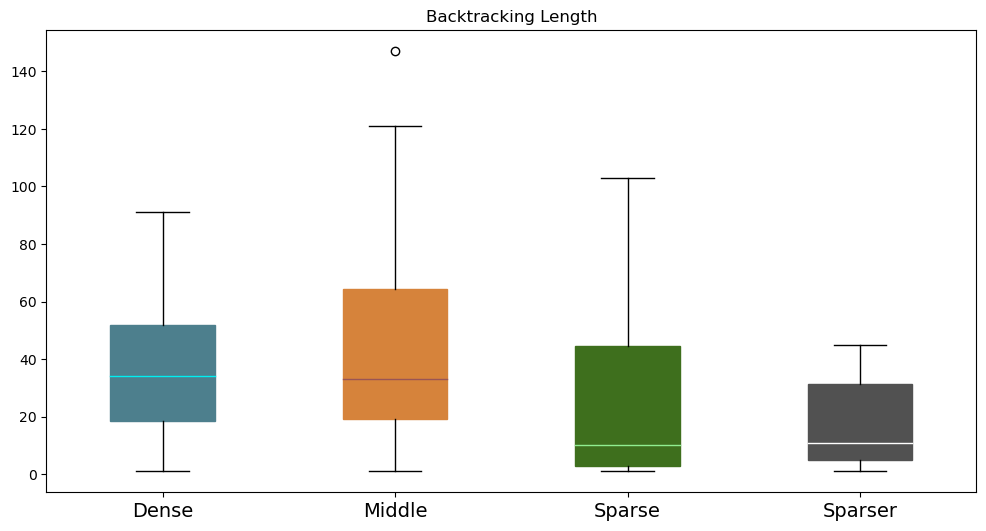

In [13]:

for met,met_name in zip(metrics, metric_names):

	bck_len = [[], [], [], []]

	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
					else:
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(bck_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title("Backtracking Length")
	ax.set_xticklabels(data_labels, fontsize=14)
	fig.savefig(f"{out_path}/characterization/backtracking_length_{met_name}.pdf", bbox_inches='tight')
#	plt.close(fig)



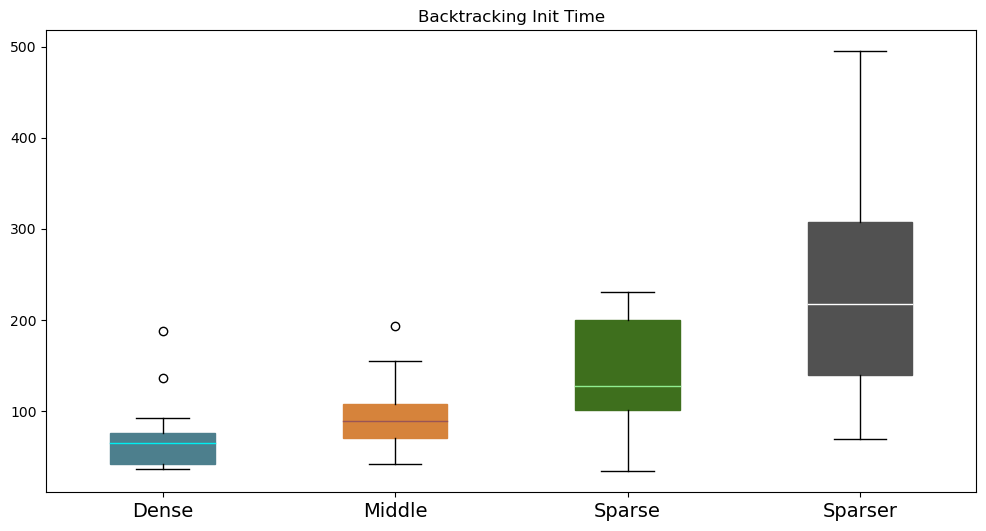

In [14]:



backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500, acc_steps ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time")

ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/backtracking_init_time.pdf", bbox_inches='tight')
#plt.close(fig)


# x-position of last detection before failure (Fig 2 panel c)

In [15]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"

Q_nums = [0, 50000, 100000, 500000, 1000000, 1500000, 2000000, 2500000, 3000000]

last_detections = {setting : [[] for _ in range(len(Q_nums))] for setting in settings}


for setting in settings:
    for seed in agent_seeds:
        for i in range(len(Q_nums)):       
            with open(f"{base_dir}/{setting}/agent_{seed}/test/{setting}/Q_{Q_nums[i]}/failed_last_detections.log", 'r') as f:
                last_detections[setting][i] += [float(x.split(',')[1]) for x in f.readlines()]


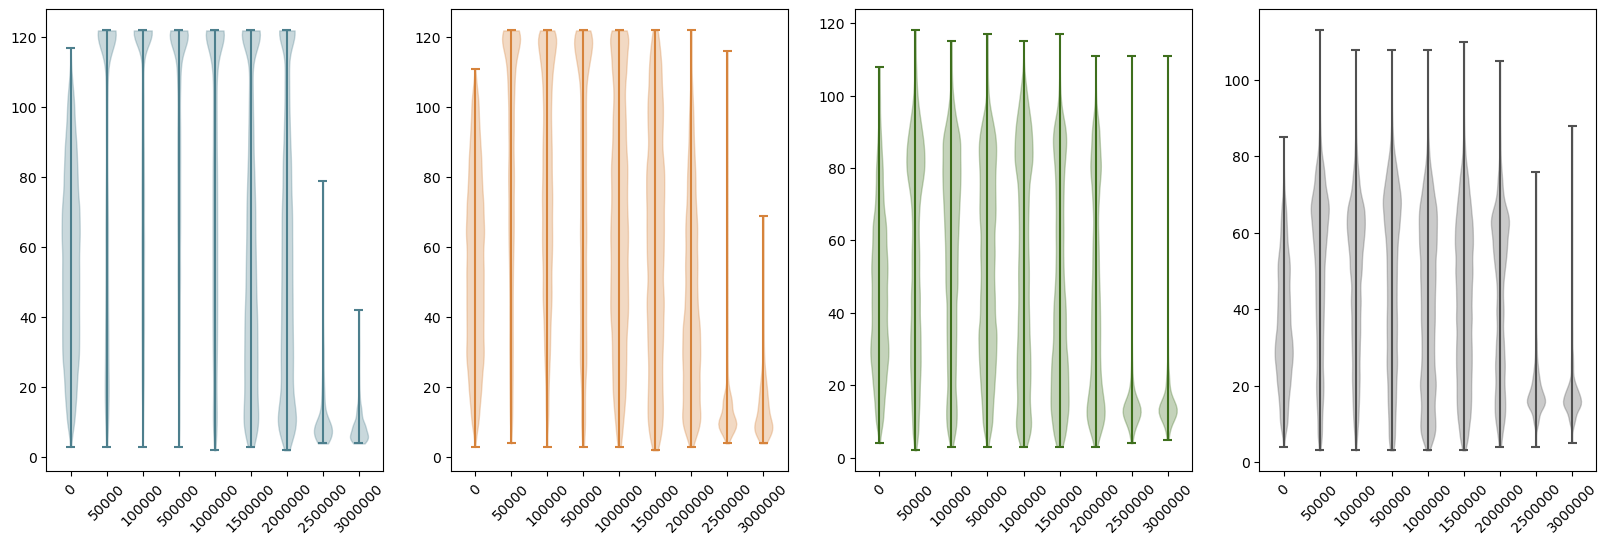

In [16]:



fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for (idx, label) in zip(range(4), data_labels):

    violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=range(len(Q_nums)))


    for e in violin['bodies']:
        e.set_facecolor(box_colors[idx])
        e.set_edgecolor(box_colors[idx])

    for lab in ['cbars', 'cmins', 'cmaxes']:
        violin[lab].set_edgecolor(box_colors[idx])
        violin[lab].set_facecolor(box_colors[idx])
        
#    axes[idx].set_ylim([0, 30])
    axes[idx].set_xticks(range(len(Q_nums)), Q_nums, rotation=45)
fig.savefig(f"{out_path}/performance/failed_positions_during_training.pdf", bbox_inches='tight')



In [17]:
print(out_path)

./paper_plots/single_Q


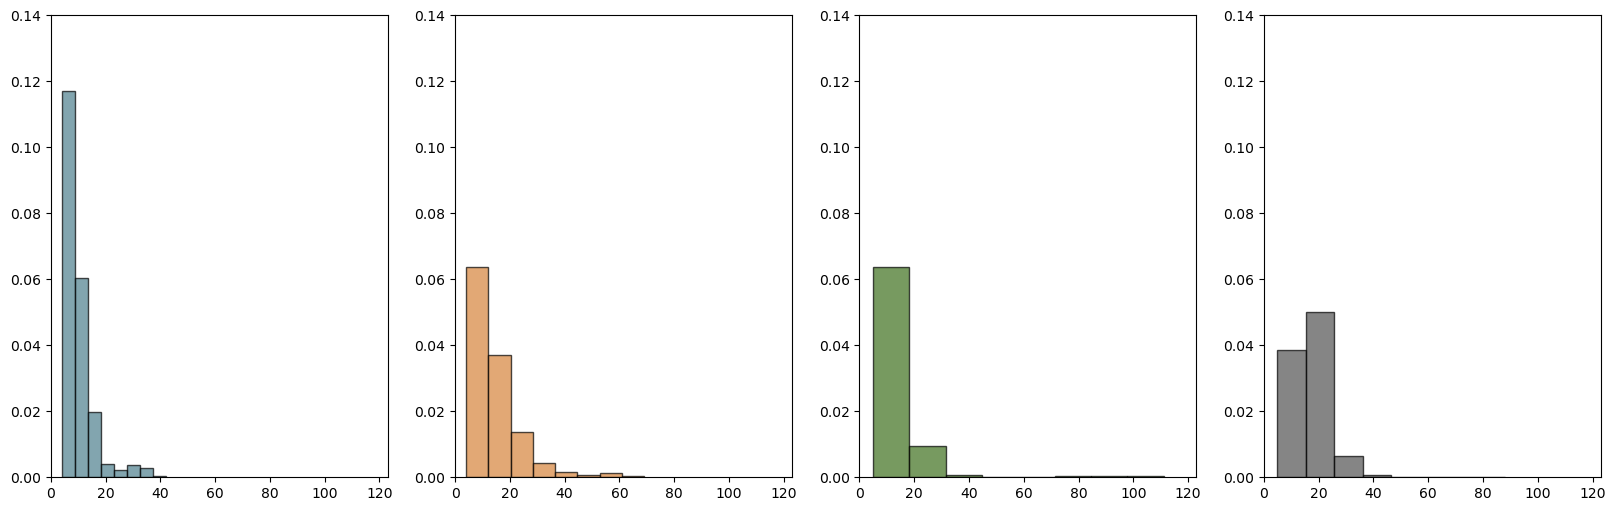

In [21]:



fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for (idx, label) in zip(range(4), data_labels):
  axes[idx].hist(last_detections[data_labels[idx].lower()][-1], bins=8, color=box_colors[idx], edgecolor='black', alpha=0.7, density=True)
  axes[idx].set_xlim([0.0, data.shape[2]])
  axes[idx].set_ylim([0.0, 0.14])
    # violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=range(len(Q_nums)))


    # for e in violin['bodies']:
    #     e.set_facecolor(box_colors[idx])
    #     e.set_edgecolor(box_colors[idx])

    # for lab in ['cbars', 'cmins', 'cmaxes']:
    #     violin[lab].set_edgecolor(box_colors[idx])
    #     violin[lab].set_facecolor(box_colors[idx])
        
#    axes[idx].set_ylim([0, 30])
#  axes[idx].set_xticks(range(len(Q_nums)), Q_nums, rotation=45)
#fig.savefig(f"{out_path}/performance/failed_positions_during_training.pdf", bbox_inches='tight')



In [19]:
data = np.load("/storage/rando/data/nose_data_27_123.npy") # instert your data path

blanks = {}
num_blanks = {}
mean_blank_map = {}

for n_thr in noise_thresholds:
    new_data = data.copy()
    new_data[new_data < n_thr] = 0.0
    blanks[n_thr] = []
    mean_blank_map[n_thr] = np.zeros((data.shape[1], data.shape[2]))
    num_blanks[n_thr] = 0
    for i in range(new_data.shape[1]):
        for j in range(new_data.shape[2]):
            obs = new_data[:, i, j] > n_thr
            count_zero = 0 
            avg_blank = []
            init_idx = np.argmax(obs)
            for k in range(init_idx + 1, len(obs)):
                if not obs[k]:
                    count_zero +=1
                else:
                    if count_zero > 0:
                        avg_blank.append(count_zero)
                    count_zero = 0
            if len(avg_blank) >0:
              blanks[n_thr] += avg_blank
              num_blanks[n_thr] += len(avg_blank)
              mean_blank_map[n_thr][i, j] = np.mean(avg_blank)


In [20]:
for n_thr in noise_thresholds:
  print("[++] n_thr = {}\n\t[--] Avg blank: {} +/- {}\n\t[--] 10-th Percentile: {}\t95-th Percentile: {}\n\t[--] min: {}\tmax: {}".format(n_thr, np.mean(blanks[n_thr]), np.std(blanks[n_thr]), np.percentile(blanks[n_thr], q=10), np.percentile(blanks[n_thr], q=85), np.min(blanks[n_thr]), np.max(blanks[n_thr]) ))
#  print("[--] Num blank: {}".format(num_blanks[n_thr]))

mean_blanks = np.array([np.mean(blanks[n_thr]) for n_thr in noise_thresholds])
std_blanks  = np.array([np.std(blanks[n_thr]) for n_thr in noise_thresholds])
p10_blanks = np.array([np.percentile(blanks[n_thr], q=10) for n_thr in noise_thresholds])
p95_blanks  = np.array([np.percentile(blanks[n_thr], q=85) for n_thr in noise_thresholds])


[++] n_thr = 1e-06
	[--] Avg blank: 7.76735137000871 +/- 35.81702944664332
	[--] 10-th Percentile: 1.0	95-th Percentile: 9.0
	[--] min: 1	max: 2391
[++] n_thr = 3e-06
	[--] Avg blank: 10.130460379733345 +/- 40.77479696107458
	[--] 10-th Percentile: 1.0	95-th Percentile: 12.0
	[--] min: 1	max: 2294
[++] n_thr = 5e-06
	[--] Avg blank: 14.036780889541744 +/- 57.4398311063933
	[--] 10-th Percentile: 1.0	95-th Percentile: 15.0
	[--] min: 1	max: 2241
[++] n_thr = 7e-06
	[--] Avg blank: 15.618002129542148 +/- 63.44280576620886
	[--] 10-th Percentile: 1.0	95-th Percentile: 17.0
	[--] min: 1	max: 2272


/tmp/ipykernel_3656404/1134998091.py:10: RuntimeWarning: divide by zero encountered in log10
  ax.imshow(np.log10(mean_blank_map[noise_thresholds[i]]), origin='lower', cmap='viridis', rasterized=True)


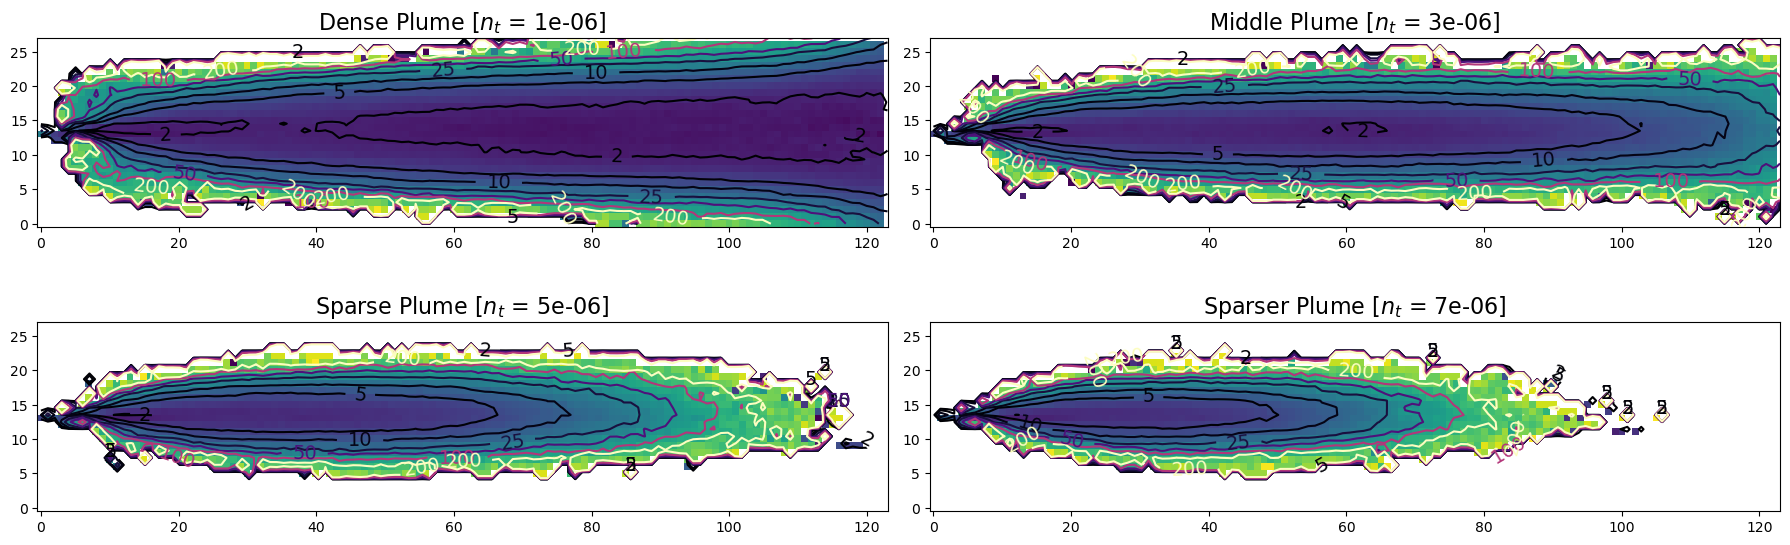

In [75]:
y = np.linspace(0, data.shape[1], data.shape[1])
x = np.linspace(0, data.shape[2], data.shape[2])
X, Y = np.meshgrid(x, y)

fig, axes = plt.subplots(2, 2, figsize=(18, 6))
axes = axes.flatten()
for i in range(len(noise_thresholds)):
  ax = axes[i]
  ax.set_title("{} Plume [$n_t$ = {}]".format(data_labels[i], noise_thresholds[i]), fontsize=16)
  ax.imshow(np.log10(mean_blank_map[noise_thresholds[i]]), origin='lower', cmap='viridis', rasterized=True)
#  ax.imshow(np.log10(np.mean(data_environments[noise_thresholds[i]], 0)), origin='lower', cmap='viridis', rasterized=True)
  contour = ax.contour(X, Y, mean_blank_map[noise_thresholds[i]], levels=[2, 5, 10, 25, 50, 100, 200], cmap='magma')
  ax.clabel(contour, inline=True, fontsize=14)

fig.tight_layout()

fig.savefig("./paper_plots/general/avg_blanks_contour.pdf", bbox_inches='tight')

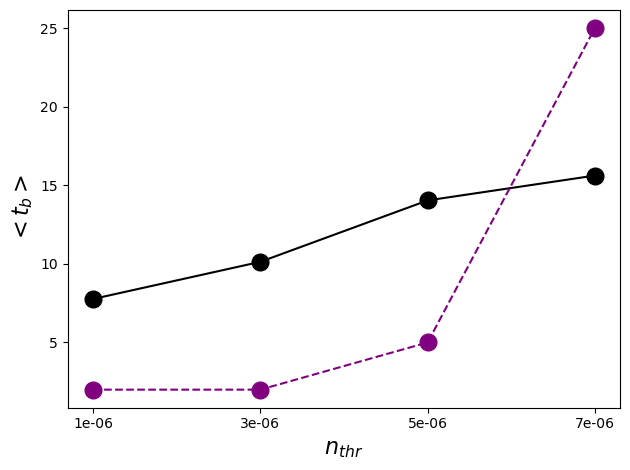

In [76]:
opt_taus = [2, 2, 5, 25]
fig, ax = plt.subplots()

bins = np.linspace(0, 100, 15)


ax.plot(range(len(mean_blanks)), mean_blanks,'o-', ms=12, c='black',rasterized=True)

ax.plot(range(len(mean_blanks)), opt_taus, 'o--', ms=12, c='purple')

ax.set_xticks(range(len(mean_blanks)), noise_thresholds)
ax.set_xlabel("$n_{thr}$", fontsize=16)
ax.set_ylabel("$<t_b>$", fontsize=16)

fig.tight_layout()

fig.savefig("./paper_plots/general/avg_blanks.pdf", bbox_inches='tight')


## Figure 3 -> performance of agents

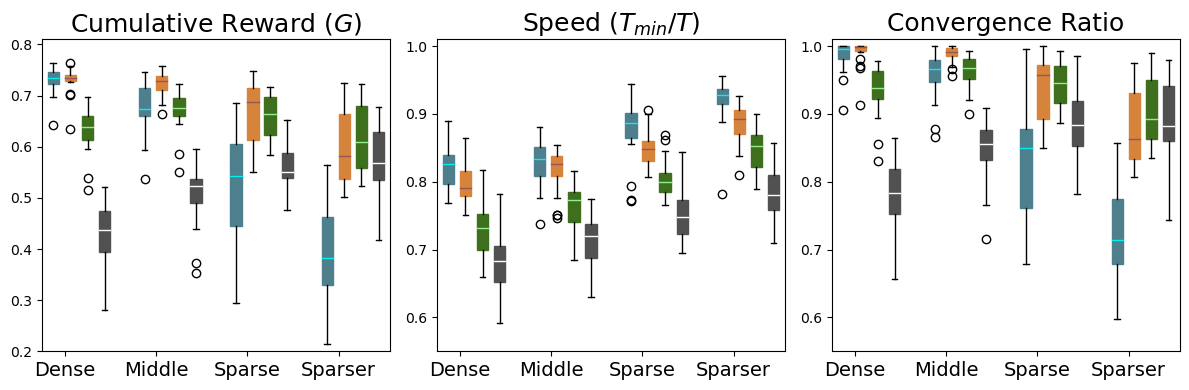

In [22]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"


creward_data, speed_data, conv_data = [],[],[]
for i in range(len(settings)):
    setting = settings[i] 
    for j in range(len(settings)):
        test_setting = settings[j]
        c_rewards = []
        speeds = []
        convergence = []

        for seed in agent_seeds:
            with open(f"{base_dir}/{setting}/agent_{seed}/test/{test_setting}/test_summary.log", 'r') as f:
                line = f.readline().split(',')
                c_rewards.append(float(line[0]))
                speeds.append(float(line[2]))
                convergence.append(float(line[4]))
        creward_data.append(c_rewards)
        speed_data.append(speeds)
        conv_data.append(convergence)
    

num_settings = 4
num_subgroups = 4
positions = []
group_width = 1.0
subgroup_spacing = 0.75 

for i in range(num_settings):
    base = i * group_width * num_subgroups  
    positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


fig, ax = plt.subplots(1, 3, figsize=(12, 4))
b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


#print(len(b1), b1)

for i in range(len(b1['boxes'])):
    b1['boxes'][i].set_color(box_colors[i % 4])
    b1['medians'][i].set_color(median_colors[i % 4])
    b2['boxes'][i].set_color(box_colors[i % 4])
    b2['medians'][i].set_color(median_colors[i % 4])
    b3['boxes'][i].set_color(box_colors[i % 4])
    b3['medians'][i].set_color(median_colors[i % 4])

xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
for i in range(len(ax)):
    ax[i].set_xticks(ticks=xticks, labels=data_labels, fontsize=14)

ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
ax[2].set_title("Convergence Ratio", fontsize=18)


ax[0].set_ylim([0.2, 0.81])
ax[1].set_ylim([0.55, 1.01])
ax[2].set_ylim([0.55, 1.01])
fig.tight_layout()
fig.savefig(f"{out_path}/performance/performance.pdf", bbox_inches='tight')


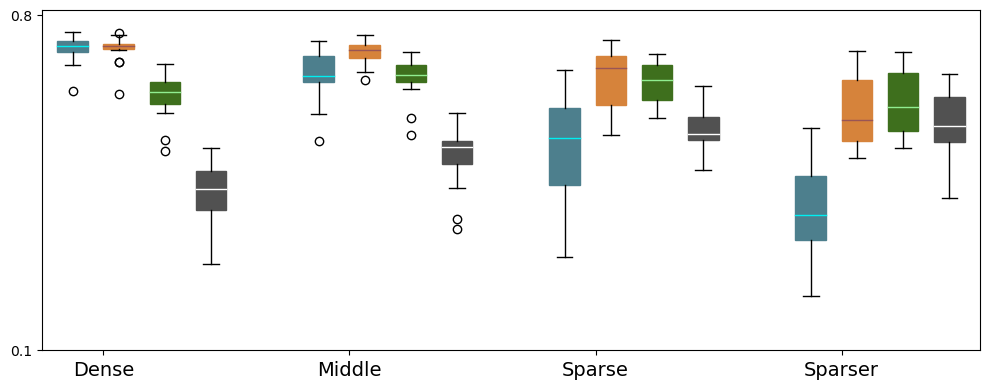

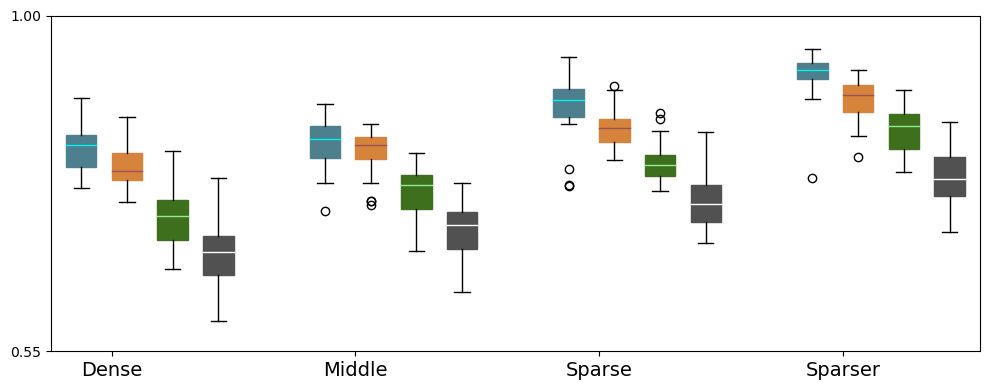

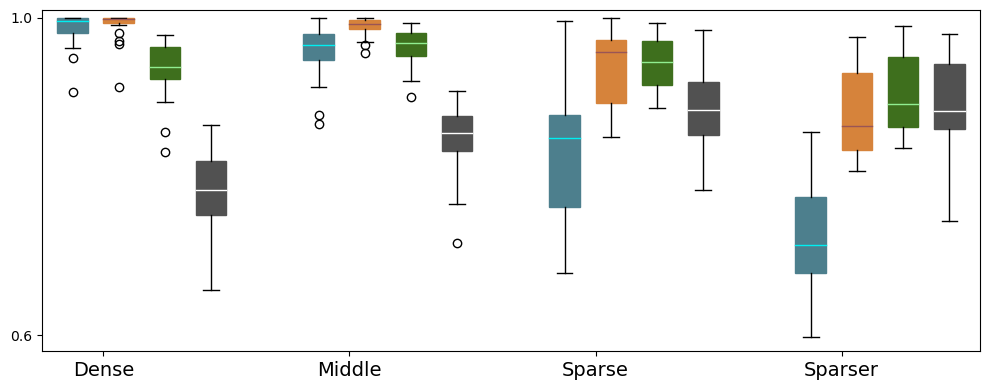

In [23]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"



num_settings = 4
num_subgroups = 4
positions = []
group_width = 1.0
subgroup_spacing = 0.75 

for i in range(num_settings):
    base = i * group_width * num_subgroups  
    positions += [base + j * subgroup_spacing for j in range(num_subgroups)]

for (i, (result_name, result_data)) in enumerate([('G', creward_data), ('speed', speed_data), ('convergence', conv_data)]):
  fig, ax = plt.subplots(1, 1, figsize=(10, 4))
  b = ax.boxplot(result_data, positions=positions, patch_artist=True)

  for j in range(len(b['boxes'])):
      b['boxes'][j].set_color(box_colors[j % 4])
      b['medians'][j].set_color(median_colors[j % 4])
    
  xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
  ax.set_xticks(ticks=xticks, labels=data_labels, fontsize=14)


  if i == 0:
    ax.set_ylim([0.1, 0.81])
    ax.set_yticks([0.1, 0.8])
  elif i == 1:
    ax.set_ylim([0.55, 1.])
    ax.set_yticks([0.55,1.0])
  else:
    ax.set_ylim([0.58, 1.01])
    ax.set_yticks([0.6,1.0])
  fig.tight_layout()
  fig.savefig(f"{out_path}/performance/performance_{result_name}.pdf", bbox_inches='tight')


# x-position of last detection before failure in different environments (Fig 3)

In [26]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
test_settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"


last_detections = { setting : [[] for _ in range(len(settings))] for setting in settings}


for setting in settings:
  for (i, test_setting) in enumerate(test_settings):
    for seed in agent_seeds:
      with open(f"{base_dir}/{setting}/agent_{seed}/test/{test_setting}/failed_last_detections.log", 'r') as f:
        last_detections[setting][i] += [float(x.split(',')[1]) for x in f.readlines()]


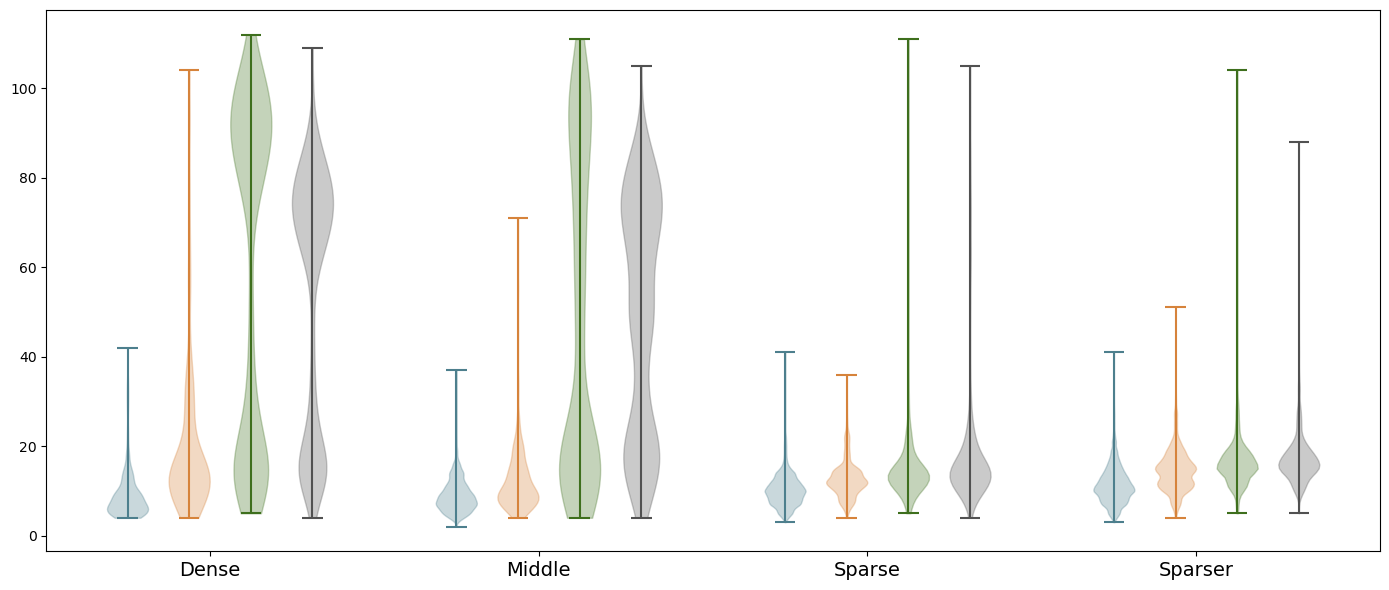

In [27]:
num_settings = 4
num_subgroups = 4
positions = []
group_width = 1.0
subgroup_spacing = 0.75 

for i in range(num_settings):
    base = i * group_width * num_subgroups  
    positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


fig, ax = plt.subplots(1, 1, figsize=(14, 6))


for setting_idx in range(len(test_settings)):

  violin = ax.violinplot(last_detections[data_labels[setting_idx].lower()], positions=positions[4*setting_idx:4*(setting_idx + 1)])#, positions=positions[idx])
  for (k, e) in enumerate(violin['bodies']):
    e.set_facecolor(box_colors[k])
    e.set_edgecolor(box_colors[k])
  for lab in ['cbars', 'cmins', 'cmaxes']:
    
    violin[lab].set_edgecolors(box_colors)
    violin[lab].set_facecolors(box_colors)


# b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
# b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
# b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


# #print(len(b1), b1)

# for i in range(len(b1['boxes'])):
#     b1['boxes'][i].set_color(box_colors[i % 4])
#     b1['medians'][i].set_color(median_colors[i % 4])
#     b2['boxes'][i].set_color(box_colors[i % 4])
#     b2['medians'][i].set_color(median_colors[i % 4])
#     b3['boxes'][i].set_color(box_colors[i % 4])
#     b3['medians'][i].set_color(median_colors[i % 4])

#xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
xticks = [(i * group_width * num_subgroups) + (group_width / 2) + 0.5 for i in range(num_settings)]
ax.set_xticks(ticks=xticks, labels=data_labels, fontsize=14)
fig.tight_layout()
fig.savefig(f"./paper_plots/single_Q/performance/failed_position_singleQ_generalization.pdf", bbox_inches='tight')
# for i in range(len(ax)):
#     ax[i].set_xticks(ticks=xticks, labels=data_labels, fontsize=14)

# ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
# ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
# ax[2].set_title("Convergence Ratio", fontsize=18)


# ax[0].set_ylim([0.0, 1.01])
# ax[1].set_ylim([0.0, 1.01])
# ax[2].set_ylim([0.0, 1.01])


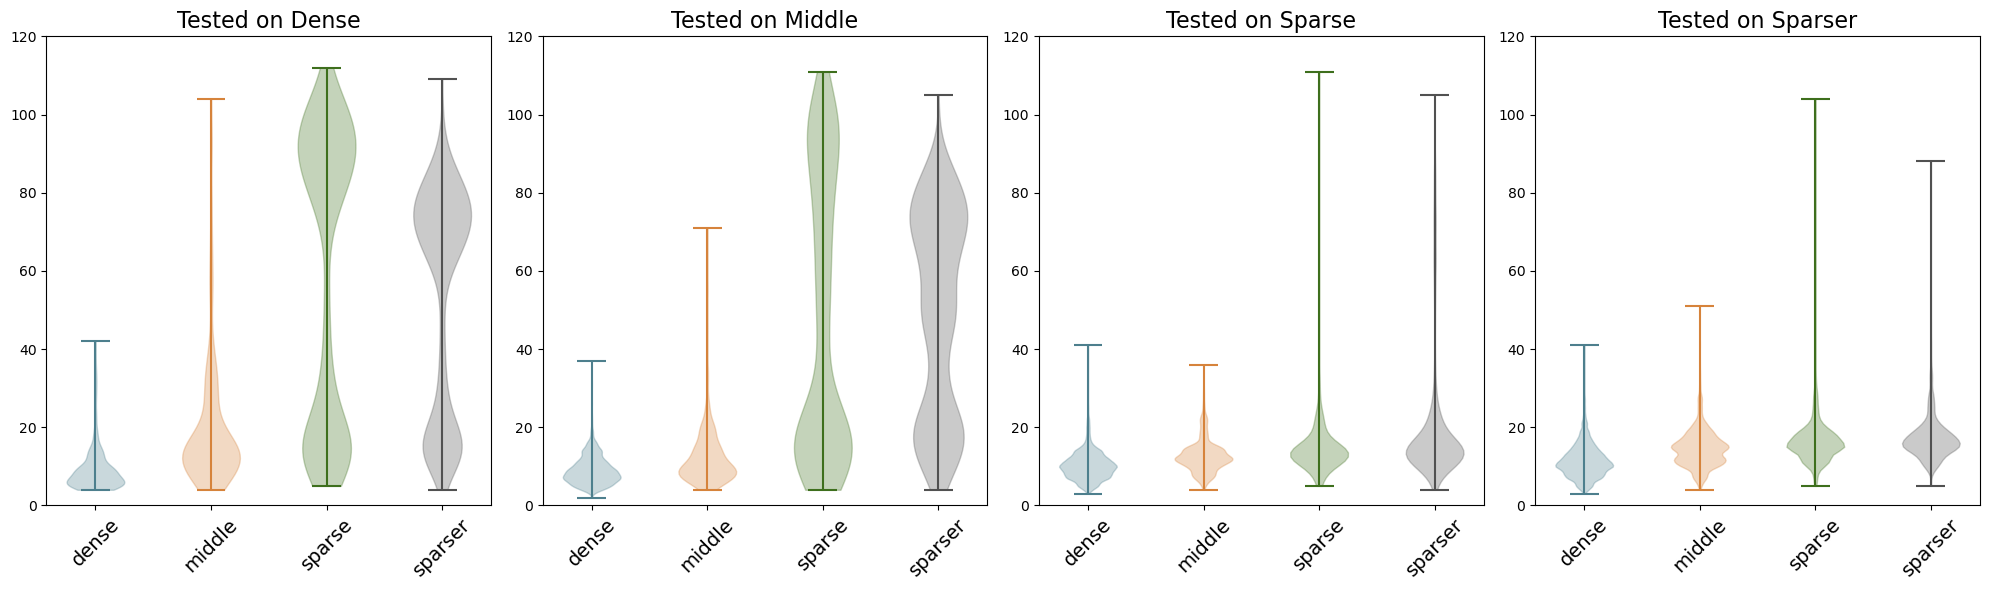

In [28]:

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for (idx, label) in zip(range(4), data_labels):
  axes[idx].set_title(f"Tested on {label}", fontsize=16)
  test_setting = label.lower()

  violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=range(len(settings)))


  for (k, e) in enumerate(violin['bodies']):
    e.set_facecolor(box_colors[k])
    e.set_edgecolor(box_colors[k])
#    e.set_medianprops({'color': box_colors[k]})

#  violin['cmedians'].set_colors(box_colors)

  # print(violin['cbars'].set_edgecolor(box_colors[idx], ))
  
  for lab in ['cbars', 'cmins', 'cmaxes']:
    
    violin[lab].set_edgecolors(box_colors)
    violin[lab].set_facecolors(box_colors)

  axes[idx].set_xticks(range(len(settings)), settings, rotation=45, fontsize=14)
  axes[idx].set_ylim([0, 120])
fig.tight_layout()
fig.savefig(f"{out_path}/performance/last_detection_generalization.pdf", bbox_inches='tight')



## Two-Q

In [29]:
agent = TwoQAgent(horizon=500)
out_path = './paper_plots/two_Q'
tau = 2
taus = [2, 5, 10, 25, 50, 100, 200]

# 2Q Agent: Training curves

In [32]:
Qs = [
    ('Dense',  "/storage/rando/pynav_results_new/two_Q/dense", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', "/storage/rando/pynav_results_new/two_Q/middle", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', "/storage/rando/pynav_results_new/two_Q/sparse", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser',"/storage/rando/pynav_results_new/two_Q/sparser", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

delta = 5000

for tau in taus:
  for (idx, (label, main_path, color_rgb)) in enumerate(Qs):
      dirs= os.listdir(main_path)
      n_plots = len(dirs) // 5 # + 1
      fig, ax = plt.subplots(n_plots, 5, figsize=(12, 6))


      axes = ax.flatten()
      for i in range(len(dirs)):

        c_rew = []
        with open(f"{main_path}/{dirs[i]}/tau_{tau}/training.log", 'r') as f:
          for line in f.readlines():
            c_rew.append(float(line.split(',')[2]))
          avg_crew = []
          for j in range(len(c_rew) // delta):
              avg_crew.append(np.mean(c_rew[j*delta:(j+1)*delta]))
          ax = axes[i]
          ax.plot(range(len(avg_crew)), avg_crew, '-', ms=1.0, c=box_colors[idx], label='cumulative reward')


          # agent.load_q(f"{main_path}/{dirs[i]}/tau_{tau}/Q_stored/Qfun.npy")
          
          # pos = np.array([0, 0])
          # ax = axes[i]
          # path = [pos.copy()]
          # plot_steps = 100
          # for j in range(1, plot_steps + 1):
          #     pos += actions[np.argmax(agent.Q[j])]
          #     path.append(pos.copy())

          # ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
          # for j in range(plot_steps): 
          #     ax.plot(path[j][1], path[j][0], '.', ms=1, color=((170 - (j+1))/170) * color_rgb, rasterized=True )
          #     ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color=((170 - (j+1))/170) * color_rgb), rasterized=True)

          # ax.set_xlim([-51, 1.0])
          # ax.set_axis_off()
          # ax.set_aspect('equal')
      
      if len(dirs) < len(axes):
          for i in range(len(axes) - len(dirs)):
              axes[-i-1].set_axis_off()
      fig.tight_layout()
      fig.savefig(f"{out_path}/2Q_training_{label}_tau_{tau}.pdf", bbox_inches='tight')
      plt.close(fig)
      print(f"[--] Plotted {label} [tau = {tau}]")



[--] Plotted Dense [tau = 2]
[--] Plotted Middle [tau = 2]
[--] Plotted Sparse [tau = 2]
[--] Plotted Sparser [tau = 2]
[--] Plotted Dense [tau = 5]
[--] Plotted Middle [tau = 5]
[--] Plotted Sparse [tau = 5]
[--] Plotted Sparser [tau = 5]
[--] Plotted Dense [tau = 10]
[--] Plotted Middle [tau = 10]
[--] Plotted Sparse [tau = 10]
[--] Plotted Sparser [tau = 10]
[--] Plotted Dense [tau = 25]
[--] Plotted Middle [tau = 25]
[--] Plotted Sparse [tau = 25]
[--] Plotted Sparser [tau = 25]
[--] Plotted Dense [tau = 50]
[--] Plotted Middle [tau = 50]
[--] Plotted Sparse [tau = 50]
[--] Plotted Sparser [tau = 50]
[--] Plotted Dense [tau = 100]
[--] Plotted Middle [tau = 100]
[--] Plotted Sparse [tau = 100]
[--] Plotted Sparser [tau = 100]
[--] Plotted Dense [tau = 200]
[--] Plotted Middle [tau = 200]
[--] Plotted Sparse [tau = 200]
[--] Plotted Sparser [tau = 200]


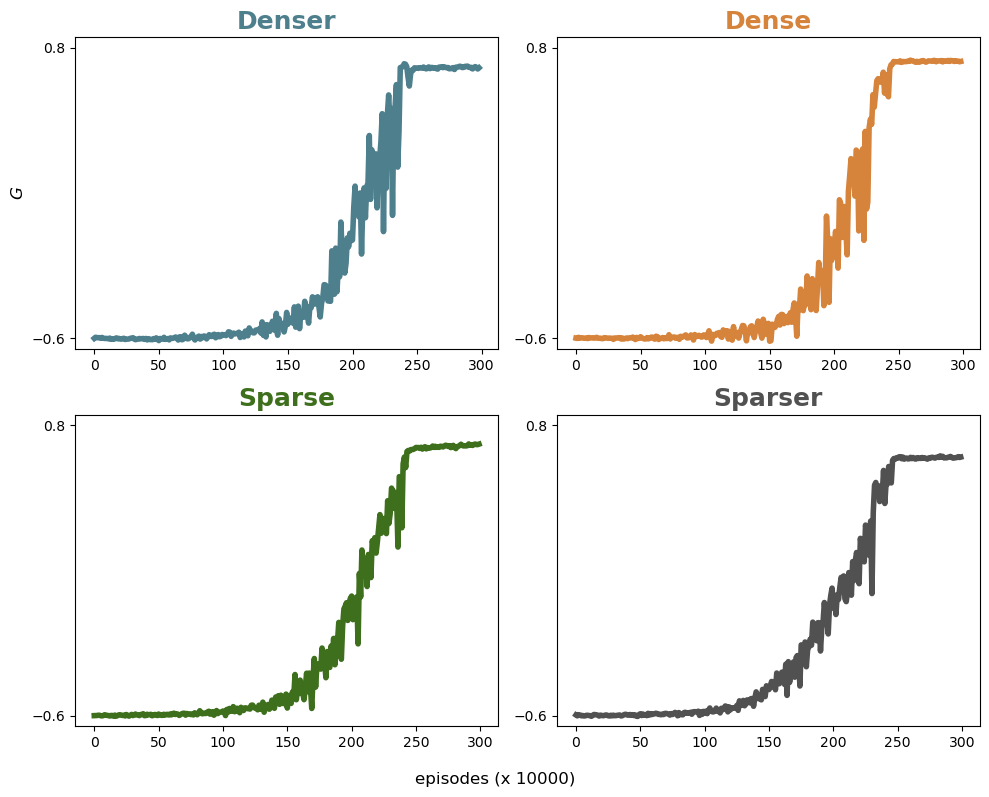

In [86]:
Qs = [
    ('Dense',   f"{results_dir}/two_Q/dense/agent_1259", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"{results_dir}/two_Q/middle/agent_6299", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"{results_dir}/two_Q/sparse/agent_5039", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"{results_dir}/two_Q/sparser/agent_944", np.array([0xd2, 0xd2, 0xd2]) / 0xff),

]

opt_taus = [2, 2, 5, 25]

delta = 10000
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes = axes.flatten()
for (i, (label, main_path, _)) in enumerate(Qs):
  ax = axes[i]
  c_rew = []
  with open(f"{main_path}/tau_{opt_taus[i]}/training.log", 'r') as f:
    for line in f.readlines():
      c_rew.append(float(line.split(',')[2]))
    avg_crew = []
    for j in range(len(c_rew) // delta):
        avg_crew.append(np.mean(c_rew[j*delta:(j+1)*delta]))
  ax.plot(range(len(avg_crew)), avg_crew, '-', ms=1.0, lw=4, c=box_colors[i], label='cumulative reward')
#  ax.set_xlabel(f"episodes (x {delta})", fontsize=12)
  ax.set_title(titles[i], fontsize=18, color=box_colors[i], fontweight='bold')
  if i == 0:# or i == 2:
      ax.set_ylabel("$G$", fontsize=12)
  ax.set_ylim([-0.65, 0.85])
  ax.set_yticks([-0.6, 0.8])
fig.supxlabel(f"episodes (x {delta})", fontsize=12)
fig.tight_layout()
fig.savefig(f"{out_path}/performance/sample_training_all_signals_2.pdf", bbox_inches='tight')
#plt.close(fig)

# 2Q Agents: trajectories in void (for Q0)

plots for $Q_0$

In [33]:
Qs = [
    ('Dense',  "/storage/rando/pynav_results_new/two_Q/dense", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', "/storage/rando/pynav_results_new/two_Q/middle", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', "/storage/rando/pynav_results_new/two_Q/sparse", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser',"/storage/rando/pynav_results_new/two_Q/sparser", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]


In [34]:

for tau in taus:
  for (label, main_path, color_rgb) in Qs:
      dirs= os.listdir(main_path)
      n_plots = len(dirs) // 5 # + 1
      fig, ax = plt.subplots(n_plots, 5, figsize=(10, 14))


      axes = ax.flatten()
      for i in range(len(dirs)):
          agent.load_q(f"{main_path}/{dirs[i]}/tau_{tau}/Q_stored/Qfun.npy")
          
          pos = np.array([0, 0])
          ax = axes[i]
          path = [pos.copy()]
          plot_steps = 100
          for j in range(1, plot_steps + 1):
              pos += actions[np.argmax(agent.Q[j])]
              path.append(pos.copy())

          ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
          for j in range(plot_steps): 
              ax.plot(path[j][1], path[j][0], '.', ms=1, color=((170 - (j+1))/170) * color_rgb, rasterized=True )
              ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color=((170 - (j+1))/170) * color_rgb), rasterized=True)

          ax.set_xlim([-51, 1.0])
          ax.set_axis_off()
          ax.set_aspect('equal')
      
      if len(dirs) < len(axes):
          for i in range(len(axes) - len(dirs)):
              axes[-i-1].set_axis_off()
      fig.tight_layout()
      fig.savefig(f"{out_path}//trajectories/two_q0_policies_trained_on_{label}_tau_{tau}.pdf", bbox_inches='tight')
      plt.close(fig)
      print(f"[--] Plotted {label} [tau = {tau}]")


[--] Plotted Dense [tau = 2]
[--] Plotted Middle [tau = 2]
[--] Plotted Sparse [tau = 2]
[--] Plotted Sparser [tau = 2]
[--] Plotted Dense [tau = 5]
[--] Plotted Middle [tau = 5]
[--] Plotted Sparse [tau = 5]
[--] Plotted Sparser [tau = 5]
[--] Plotted Dense [tau = 10]
[--] Plotted Middle [tau = 10]
[--] Plotted Sparse [tau = 10]
[--] Plotted Sparser [tau = 10]
[--] Plotted Dense [tau = 25]
[--] Plotted Middle [tau = 25]
[--] Plotted Sparse [tau = 25]
[--] Plotted Sparser [tau = 25]
[--] Plotted Dense [tau = 50]
[--] Plotted Middle [tau = 50]
[--] Plotted Sparse [tau = 50]
[--] Plotted Sparser [tau = 50]
[--] Plotted Dense [tau = 100]
[--] Plotted Middle [tau = 100]
[--] Plotted Sparse [tau = 100]
[--] Plotted Sparser [tau = 100]
[--] Plotted Dense [tau = 200]
[--] Plotted Middle [tau = 200]
[--] Plotted Sparse [tau = 200]
[--] Plotted Sparser [tau = 200]


# 2Q Agents: trajectories in void (for Q1)


In [ ]:
for tau in [2, 5, 10, 25, 50, 100, 200]:
  for (label, main_path, color_rgb) in Qs:
      dirs= os.listdir(main_path)
      n_plots = len(dirs) // 5 # + 1
      fig, ax = plt.subplots(n_plots, 5, figsize=(10, 14))


      axes = ax.flatten()
      for i in range(len(dirs)):
          agent.load_q(f"{main_path}/{dirs[i]}/tau_{tau}/Q_stored/Qfun.npy")
          
          pos = np.array([0, 0])
          ax = axes[i]
          path = [pos.copy()]
          plot_steps = 100
          for j in range(502, 502 + plot_steps + 1):
              pos += actions[np.argmax(agent.Q[j])]
              path.append(pos.copy())

          ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
          for j in range(plot_steps): 
              ax.plot(path[j][1], path[j][0], '.', ms=1, color=((170 - (j+1))/170) * color_rgb, rasterized=True )
              ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color=((170 - (j+1))/170) * color_rgb), rasterized=True)

          ax.set_xlim([-51, 1.0])
          ax.set_axis_off()
          ax.set_aspect('equal')
      
      if len(dirs) < len(axes):
          for i in range(len(axes) - len(dirs)):
              axes[-i-1].set_axis_off()
      fig.tight_layout()
      fig.savefig(f"{out_path}//trajectories/two_q1_policies_trained_on_{label}_tau_{tau}.pdf", bbox_inches='tight')
      plt.close(fig)
      print(f"[--] Plotted {label} [tau = {tau}]")


[--] Plotted Dense [tau = 2]
[--] Plotted Middle [tau = 2]
[--] Plotted Sparse [tau = 2]
[--] Plotted Sparser [tau = 2]
[--] Plotted Dense [tau = 5]
[--] Plotted Middle [tau = 5]
[--] Plotted Sparse [tau = 5]


KeyboardInterrupt: 

# 2Q Agent: sample trajectories in void (using Q0)

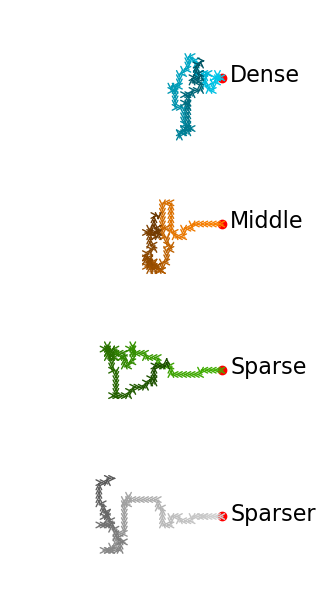

In [87]:

Qs = [
    ('Dense',   f"/storage/rando/pynav_results_new/two_Q/dense/agent_3464/tau_{tau}/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"/storage/rando/pynav_results_new/two_Q/middle/agent_1889/tau_{tau}/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"/storage/rando/pynav_results_new/two_Q/sparse/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"/storage/rando/pynav_results_new/two_Q/sparser/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(1, 500):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())

    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
    plot_steps = 100
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str, rasterized=True)
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ), rasterized=True)

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()
fig.savefig(f"{out_path}/trajectories/sample_trajectories_q0_tau_{tau}.pdf", bbox_inches='tight')

# 2Q Agent: sample trajectories in void (using Q1)

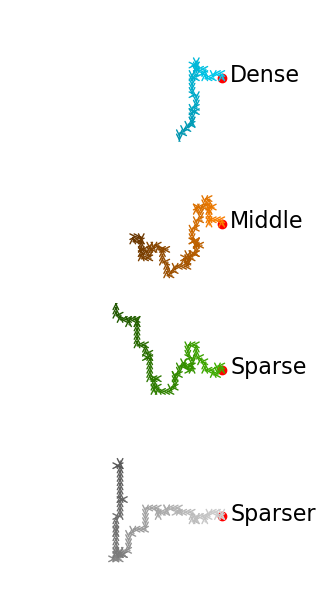

In [35]:


Qs = [
    ('Dense',   f"/storage/rando/pynav_results_new/two_Q/dense/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"/storage/rando/pynav_results_new/two_Q/middle/agent_1889/tau_{tau}/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"/storage/rando/pynav_results_new/two_Q/sparse/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"/storage/rando/pynav_results_new/two_Q/sparser/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(502, 1004):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())




    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
#    colormap = cm.get_cmap(box_colors[i])
    plot_steps = 100
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str, rasterized=True)
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ), rasterized=True)

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()

fig.savefig(f"{out_path}/trajectories/sample_trajectories_q1_tau_{tau}.pdf", bbox_inches='tight')

# Performance of 2Q agents in different environments with different thresholds ($\tau$)

[--] Plotted for tau = 2


[--] Plotted for tau = 5
[--] Plotted for tau = 10
[--] Plotted for tau = 25
[--] Plotted for tau = 50
[--] Plotted for tau = 100
[--] Plotted for tau = 200


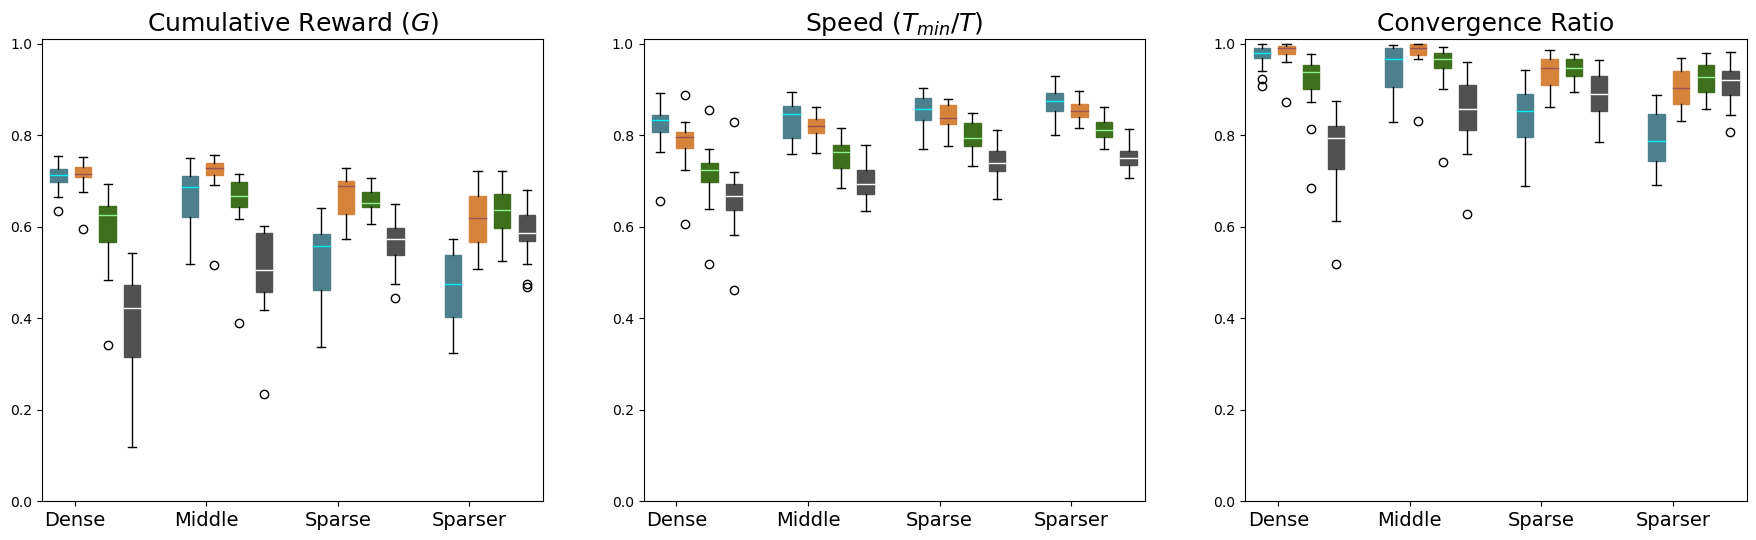

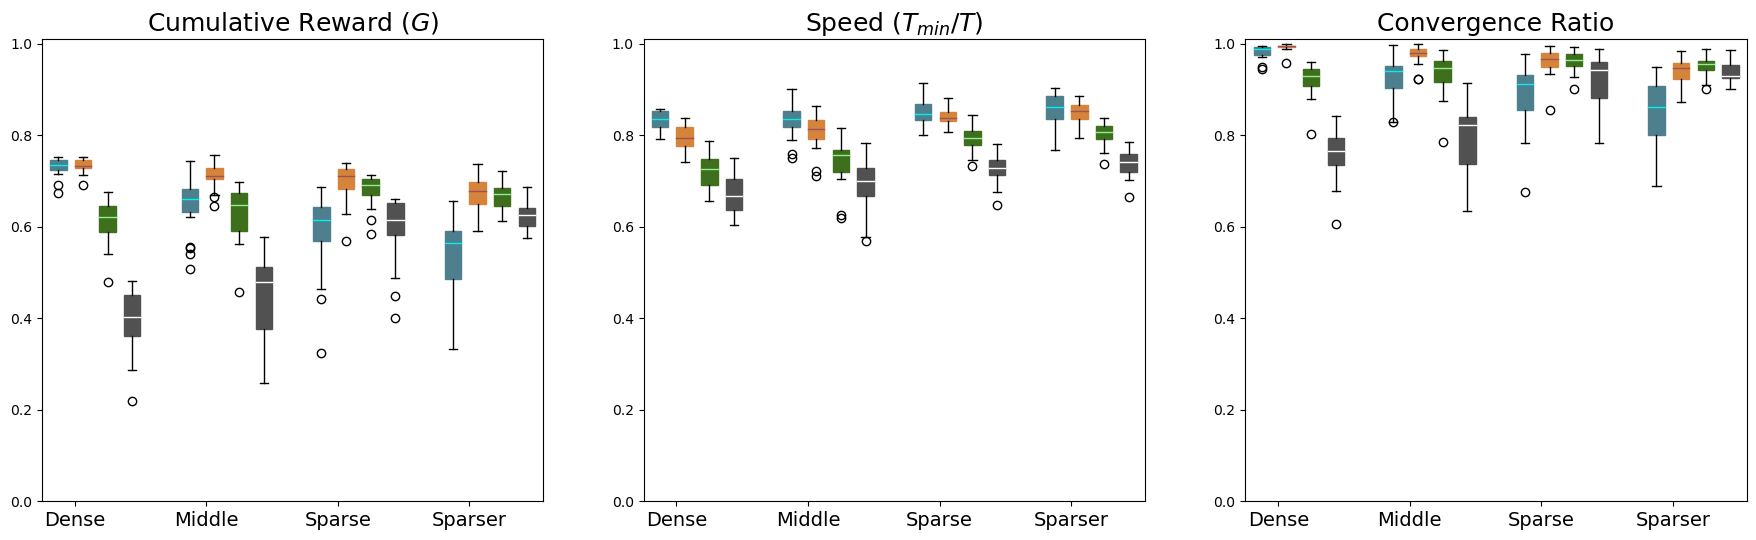

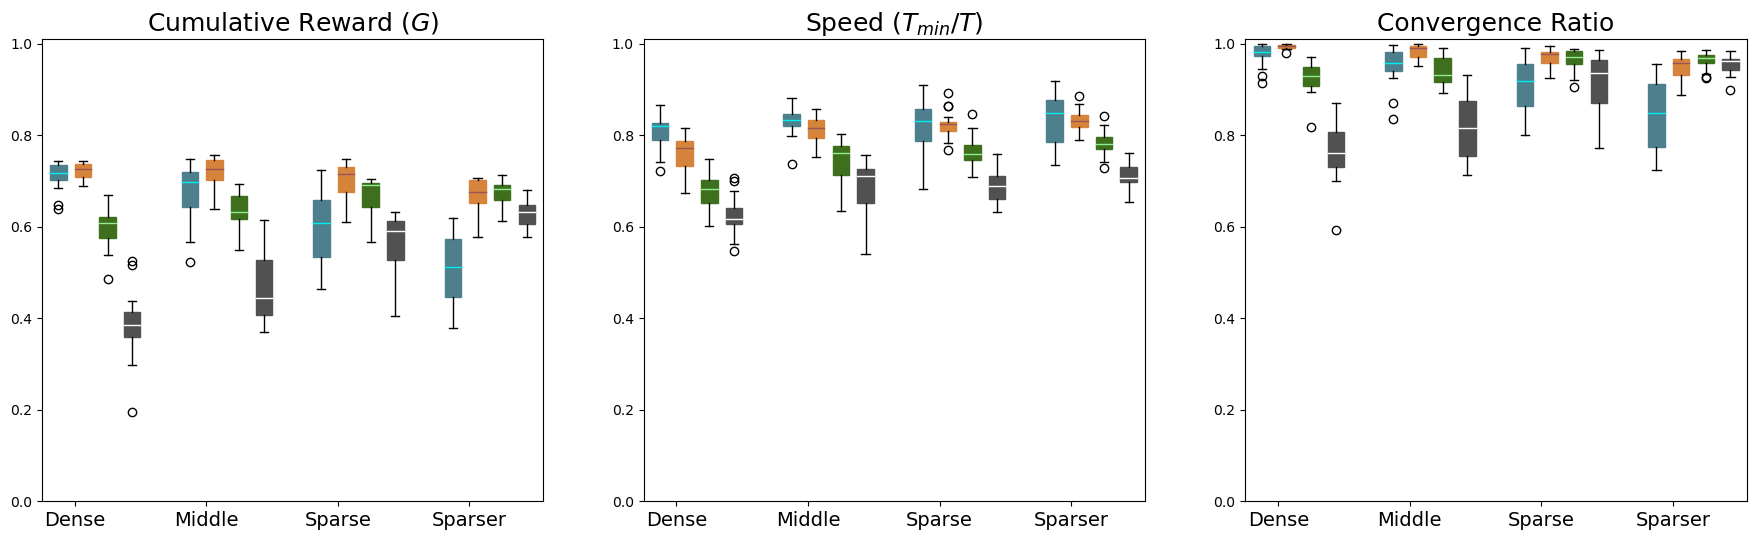

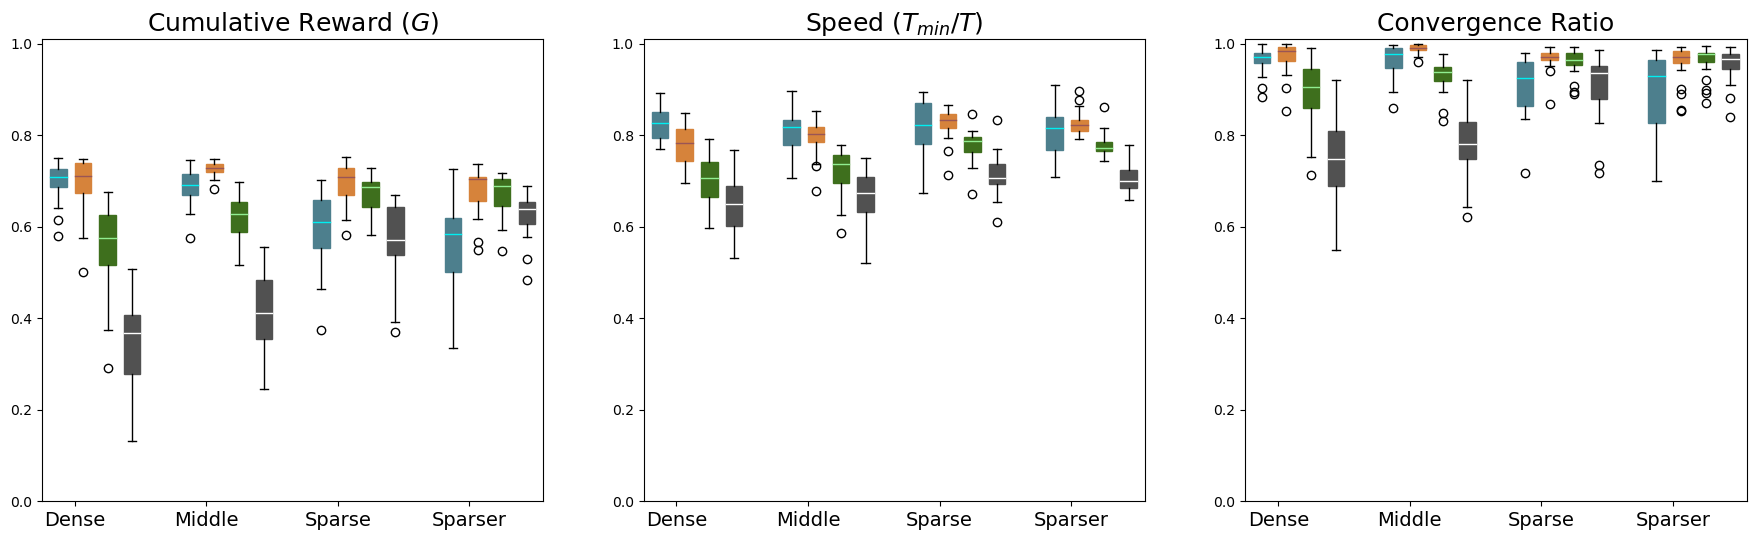

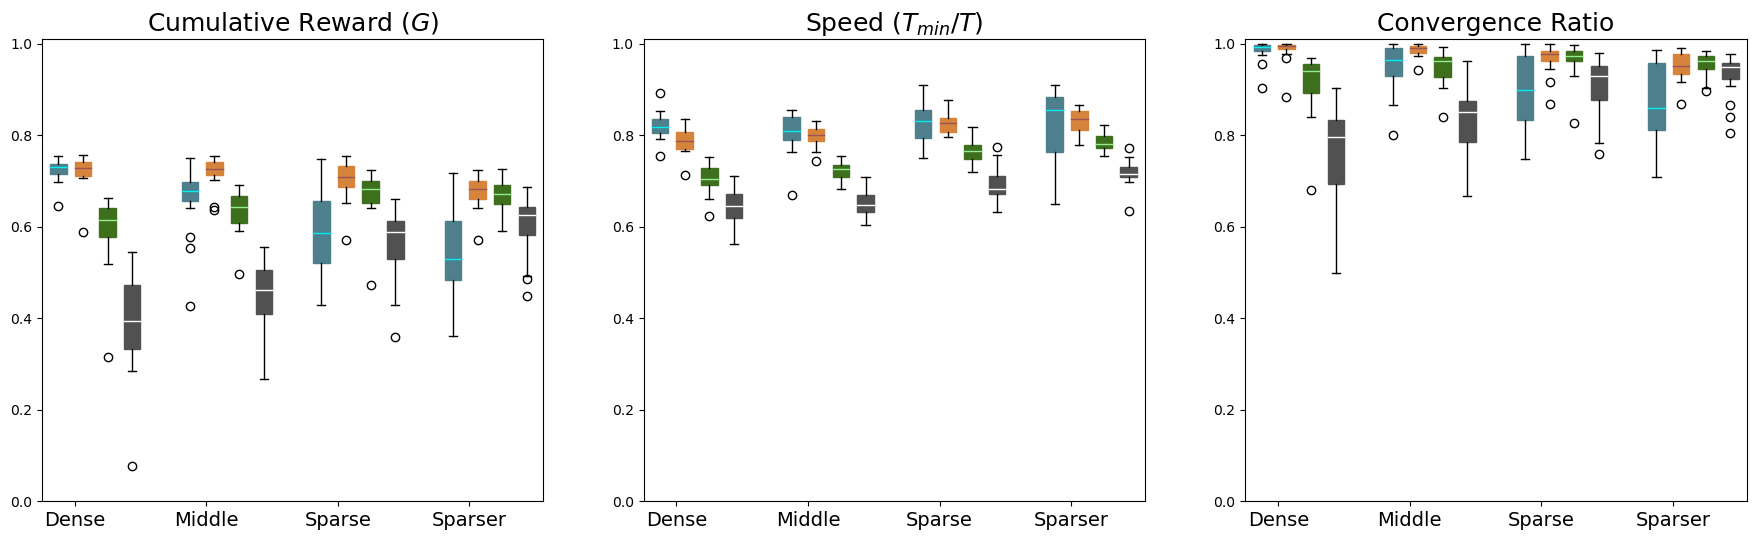

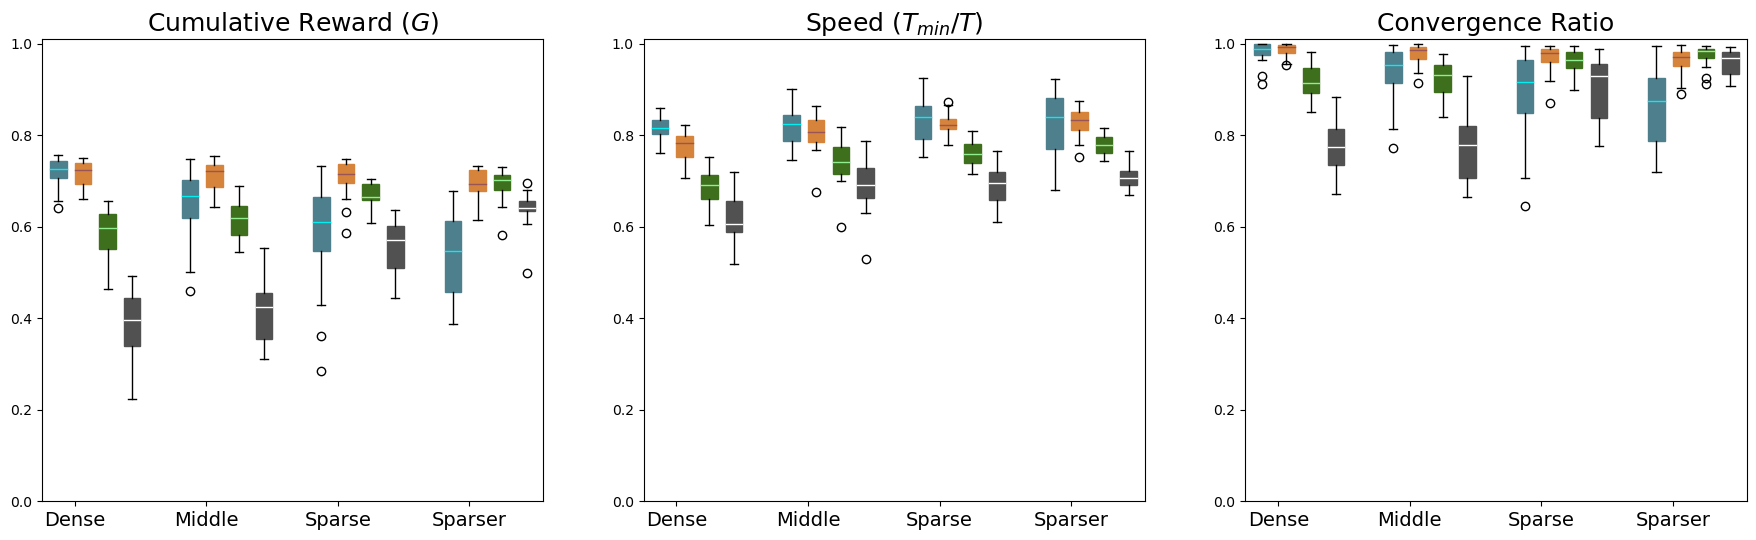

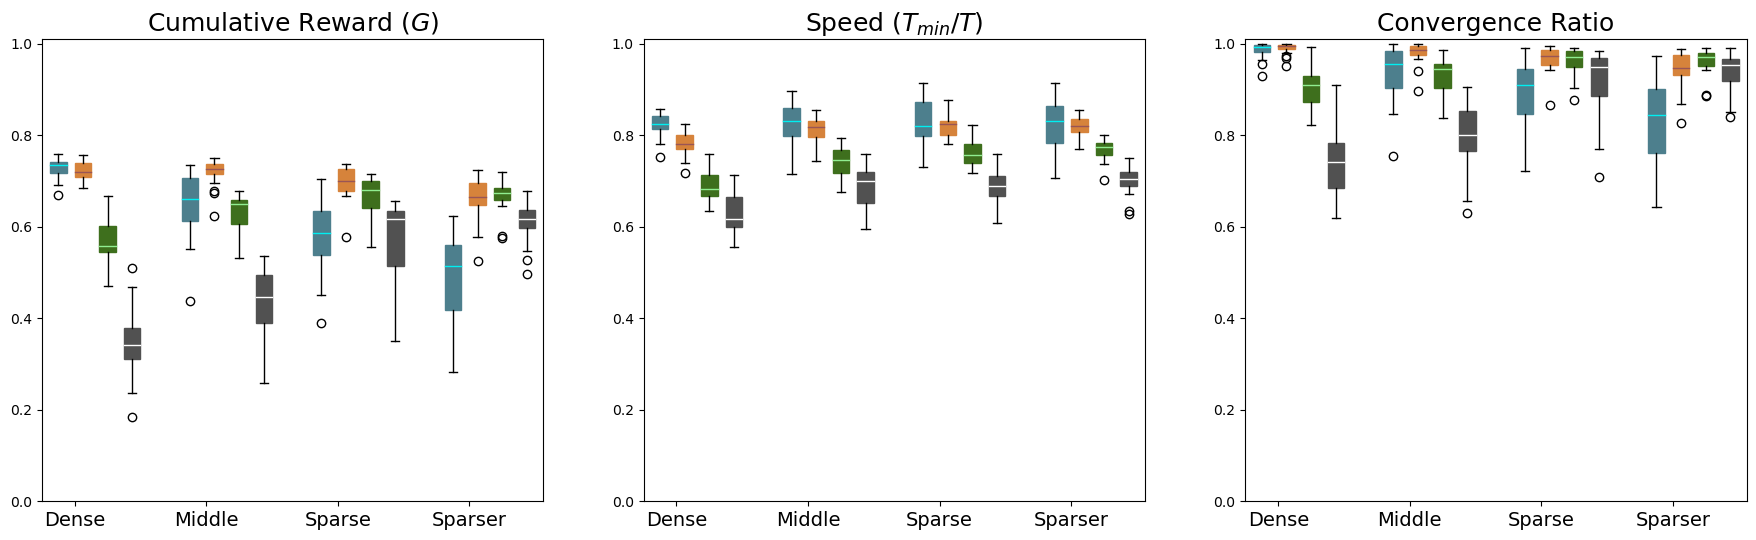

In [36]:

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"


for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  for i in range(len(settings)):
      setting = settings[i] 
      for j in range(len(settings)):
          test_setting = settings[j]
          c_rewards = []
          speeds = []
          convergence = []

          for seed in agent_seeds:

              with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log", 'r') as f:
                  line = f.readline().split(',')
                  c_rewards.append(float(line[0]))
                  speeds.append(float(line[2]))
                  convergence.append(float(line[4]))
          creward_data.append(c_rewards)
          speed_data.append(speeds)
          conv_data.append(convergence)
      

  num_settings = 4
  num_subgroups = 4
  positions = []
  group_width = 1.0
  subgroup_spacing = 0.75 

  for i in range(num_settings):
      base = i * group_width * num_subgroups  
      positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


  fig, ax = plt.subplots(1, 3, figsize=(22, 6))
  b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
  b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
  b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


  #print(len(b1), b1)

  for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[i % 4])
      b1['medians'][i].set_color(median_colors[i % 4])
      b2['boxes'][i].set_color(box_colors[i % 4])
      b2['medians'][i].set_color(median_colors[i % 4])
      b3['boxes'][i].set_color(box_colors[i % 4])
      b3['medians'][i].set_color(median_colors[i % 4])

  xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
  for i in range(len(ax)):
      ax[i].set_xticks(ticks=xticks, labels=data_labels, fontsize=14)

  ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
  ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
  ax[2].set_title("Convergence Ratio", fontsize=18)

  ax[0].set_ylim([0.0, 1.01])
  ax[1].set_ylim([0.0, 1.01])
  ax[2].set_ylim([0.0, 1.01])
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"{out_path}/performance/performance_tau_{tau}.pdf", bbox_inches='tight')
#  plt.close(fig)


# Figure 6: -> 2Q Agent: Performance in different environments with "optimal" $\tau$ 

For every agent, we select the threshold parameter $\tau$ as the one that better balance the usage of both Q (in native environment)

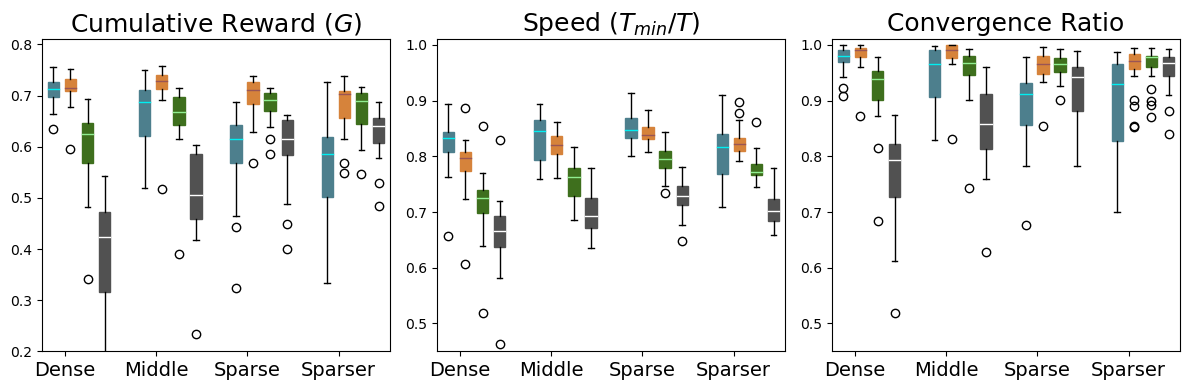

In [37]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"

opt_taus = [2, 2, 5, 25]

creward_data, speed_data, conv_data = [],[],[]
for i in range(len(settings)):
    setting = settings[i] 
    for j in range(len(settings)):
        test_setting = settings[j]
        c_rewards = []
        speeds = []
        convergence = []

        for seed in agent_seeds:
            with open(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/test/{test_setting}/test_summary.log", 'r') as f:
                line = f.readline().split(',')
                c_rewards.append(float(line[0]))
                speeds.append(float(line[2]))
                convergence.append(float(line[4]))
        creward_data.append(c_rewards)
        speed_data.append(speeds)
        conv_data.append(convergence)
    

num_settings = 4
num_subgroups = 4
positions = []
group_width = 1.0
subgroup_spacing = 0.75 

for i in range(num_settings):
    base = i * group_width * num_subgroups  
    positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


fig, ax = plt.subplots(1, 3, figsize=(12, 4))
b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


#print(len(b1), b1)

for i in range(len(b1['boxes'])):
    b1['boxes'][i].set_color(box_colors[i % 4])
    b1['medians'][i].set_color(median_colors[i % 4])
    b2['boxes'][i].set_color(box_colors[i % 4])
    b2['medians'][i].set_color(median_colors[i % 4])
    b3['boxes'][i].set_color(box_colors[i % 4])
    b3['medians'][i].set_color(median_colors[i % 4])

xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
for i in range(len(ax)):
    ax[i].set_xticks(ticks=xticks, labels=data_labels, fontsize=14)

ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
ax[2].set_title("Convergence Ratio", fontsize=18)


ax[0].set_ylim([0.2, 0.81])
ax[1].set_ylim([0.45, 1.01])
ax[2].set_ylim([0.45, 1.01])
fig.tight_layout()
fig.savefig(f"{out_path}/performance/performance.pdf", bbox_inches='tight')


Here the version used in Figure 6

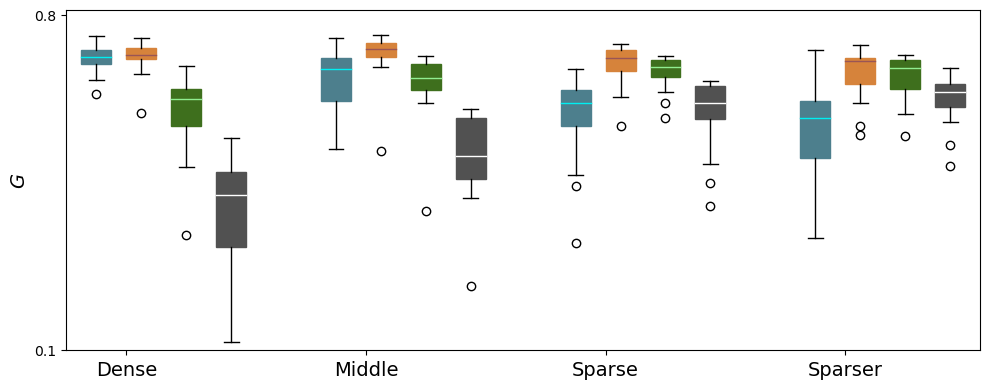

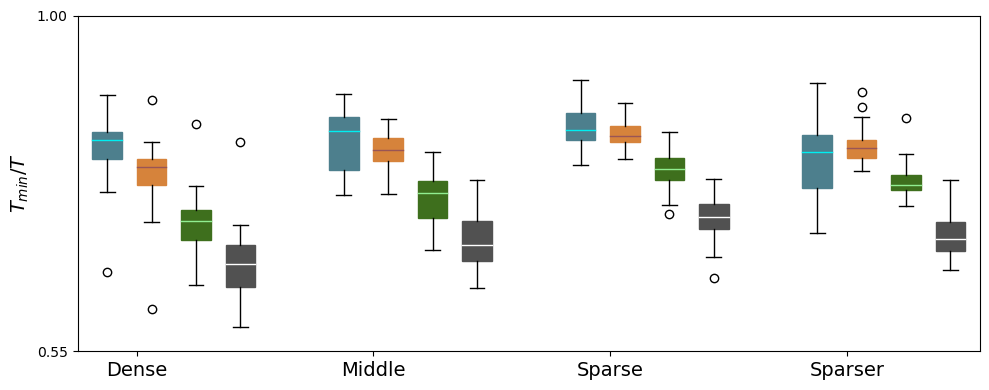

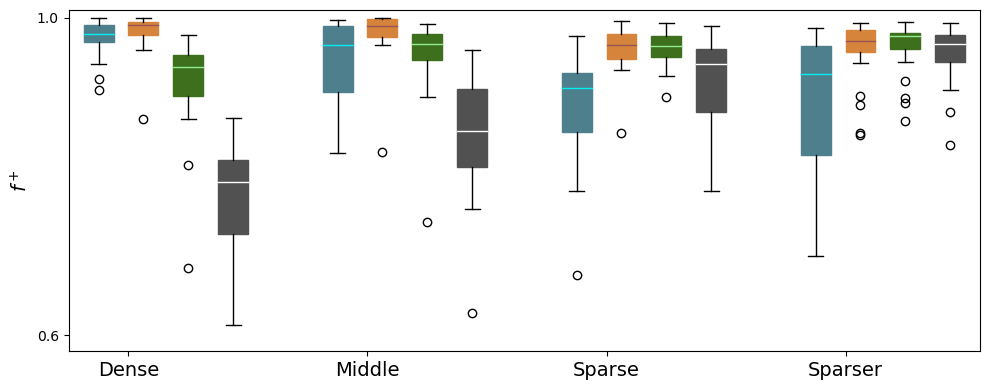

In [38]:
num_settings = 4
num_subgroups = 4
positions = []
group_width = 1.0
subgroup_spacing = 0.75 

for i in range(num_settings):
    base = i * group_width * num_subgroups  
    positions += [base + j * subgroup_spacing for j in range(num_subgroups)]



for (j, (result_name, ylabel, result_data)) in enumerate([('G', '$G$', creward_data), ('speed', '$T_{min}/T$', speed_data), ('convergence','$f^+$', conv_data)]):
  fig, ax = plt.subplots(1, 1, figsize=(10, 4))
  b = ax.boxplot(result_data, positions=positions, patch_artist=True)

  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i % 4])
      b['medians'][i].set_color(median_colors[i % 4])

     
  xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
  ax.set_xticks(ticks=xticks, labels=data_labels, fontsize=14)
  ax.set_ylabel(f"{ylabel}", fontsize=14)

  if j == 0:
    ax.set_ylim([0.1, 0.81])
    ax.set_yticks([0.1, 0.8])
  elif j == 1:
    ax.set_ylim([0.55, 1.])
    ax.set_yticks([0.55,1.0])
  else:
    ax.set_ylim([0.58, 1.01])
    ax.set_yticks([0.6,1.0])

  fig.tight_layout()
  fig.savefig(f"{out_path}/performance/performance_{result_name}.pdf", bbox_inches='tight')


# Relative Q-/Q+ Usage (Figure 4 panel b)

In [39]:
taus = [2, 5, 10, 25, 50, 100]

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"



Q_settings = []
for setting in settings:
  Qmin_usage, Qplus_usage = [], []
  Q = []
  Q_taus = []
  for tau in taus:
    minus_usage, plus_usage = [], []
    Q_agents = []
    for seed in agent_seeds:
      with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_list.log", 'r') as f:
        lines = f.readlines()
        for line in lines:
          splitted = line.split(',')
          # if int(splitted[0]) == 0:
          #   continue
          minus_usage.append(float(splitted[1]))
          plus_usage.append(float(splitted[2]))
      Q_m, Q_p = np.sum(minus_usage), np.sum(plus_usage)
      Q_agents.append(Q_m / Q_p)
    # Q_agents contains Q_m / Q_p for each agent at given tau for the given setting
    Q_taus.append(Q_agents)
  Q_settings.append(Q_taus)

6 6
6 6
6 6
6 6


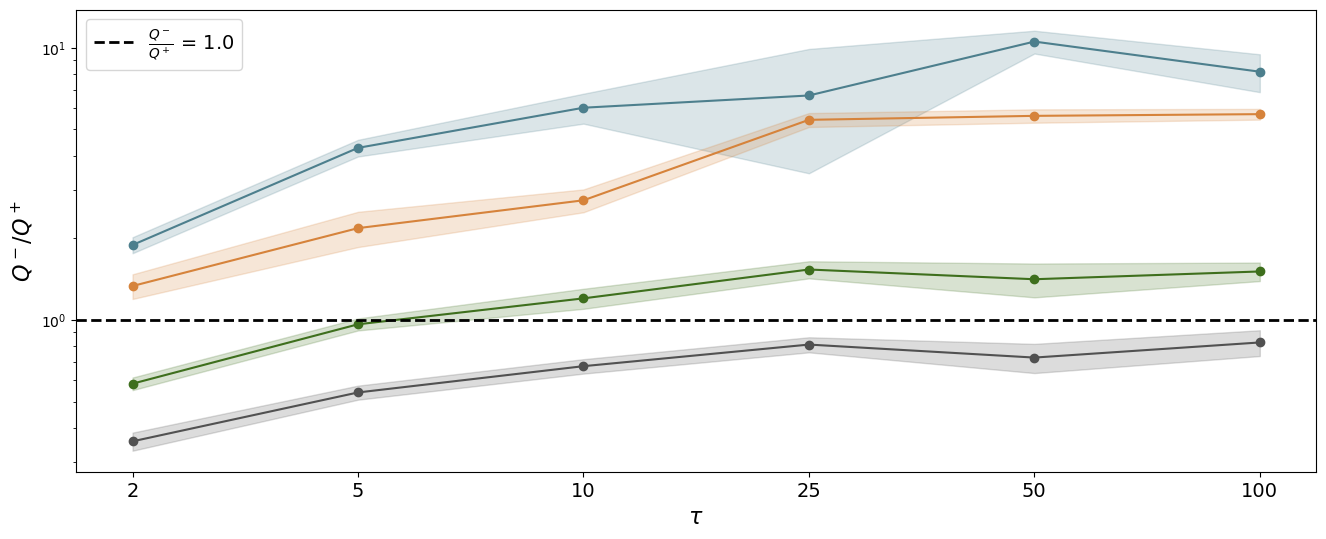

In [40]:


fig, ax = plt.subplots(1, 1, figsize=(16, 6))

for i in range(len(settings)):
  print(len(Q_settings[i]), len(taus))
#  ax.boxplot(Q_settings[i], positions=range(len(taus)), patch_artist=True, showfliers=False, medianprops={'color': median_colors[i]})
  mu, std = np.array([np.mean(Q_settings[i][j]) for j in range(len(taus)) ]), np.array([np.std(Q_settings[i][j]) for j in range(len(taus)) ])
  ax.plot(mu, 'o-', color=box_colors[i], rasterized=True)
  ax.fill_between(range(len(taus)), mu - std, mu + std, color=box_colors[i], alpha=0.2, rasterized=True)
#  ax.plot([np.std(Q_settings[i][j]) for j in range(len(taus)) ], 'o-', color=box_colors[i], rasterized=True)

ax.set_yscale('log')
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='$\\frac{Q^-}{Q^+}$ = 1.0', lw=2, rasterized=True)
ax.set_xticks(range(len(taus)), taus, fontsize=14)
ax.set_xlabel("$\\tau$", fontsize=16)
ax.set_ylabel("$Q^-$/$Q^+$", fontsize=16)

ax.legend(fontsize=14)
fig.savefig("./Qfraction_of_usage.pdf", bbox_inches='tight')

# 2Q Agent: heat-map of Q-used (Figure 4 panel d)

In [43]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"


for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  fig, axes = plt.subplots(2,2, figsize=(12, 6))
  axes = axes.flatten()
  for i in range(len(settings)):
      ax = axes[i]
      setting = settings[i] 
      Q_v = {}
      Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
      for seed in agent_seeds:
          with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_map.log", 'r') as f:
              for line in f.readlines():
                  splitted = line.split(',')
                  
                  y_pos = int(splitted[0])
                  x_pos = int(splitted[1])
                  if y_pos not in Q_v:
                      Q_v[y_pos] = {}
                  if x_pos not in Q_v[y_pos]:
                      Q_v[y_pos][x_pos] = []
                  Q_v[y_pos][x_pos].append(float(splitted[2]))
      for y_pos, xmap in Q_v.items():
          for x_pos, vals in xmap.items():
              Q_map[y_pos, x_pos] = np.mean(vals)

      new_data = data_environments[noise_thresholds[i]]
      ax.set_title(f"Trained and Test on {setting}")
      im =ax.imshow(Q_map, origin='lower', vmin=0.0, vmax=1.0)
  fig.tight_layout()
  fig.colorbar(im, ax=axes.ravel().tolist(), location='bottom')    
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"./paper_plots/two_Q/performance/two_q_usage_{tau}.pdf", bbox_inches='tight')
  plt.close(fig)

/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 2


/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 5


/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 10


... (2 outputs left out)

/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 50


/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/4017340545.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 100


# 2Q Agent: performances changing $\tau$ (supplementary)

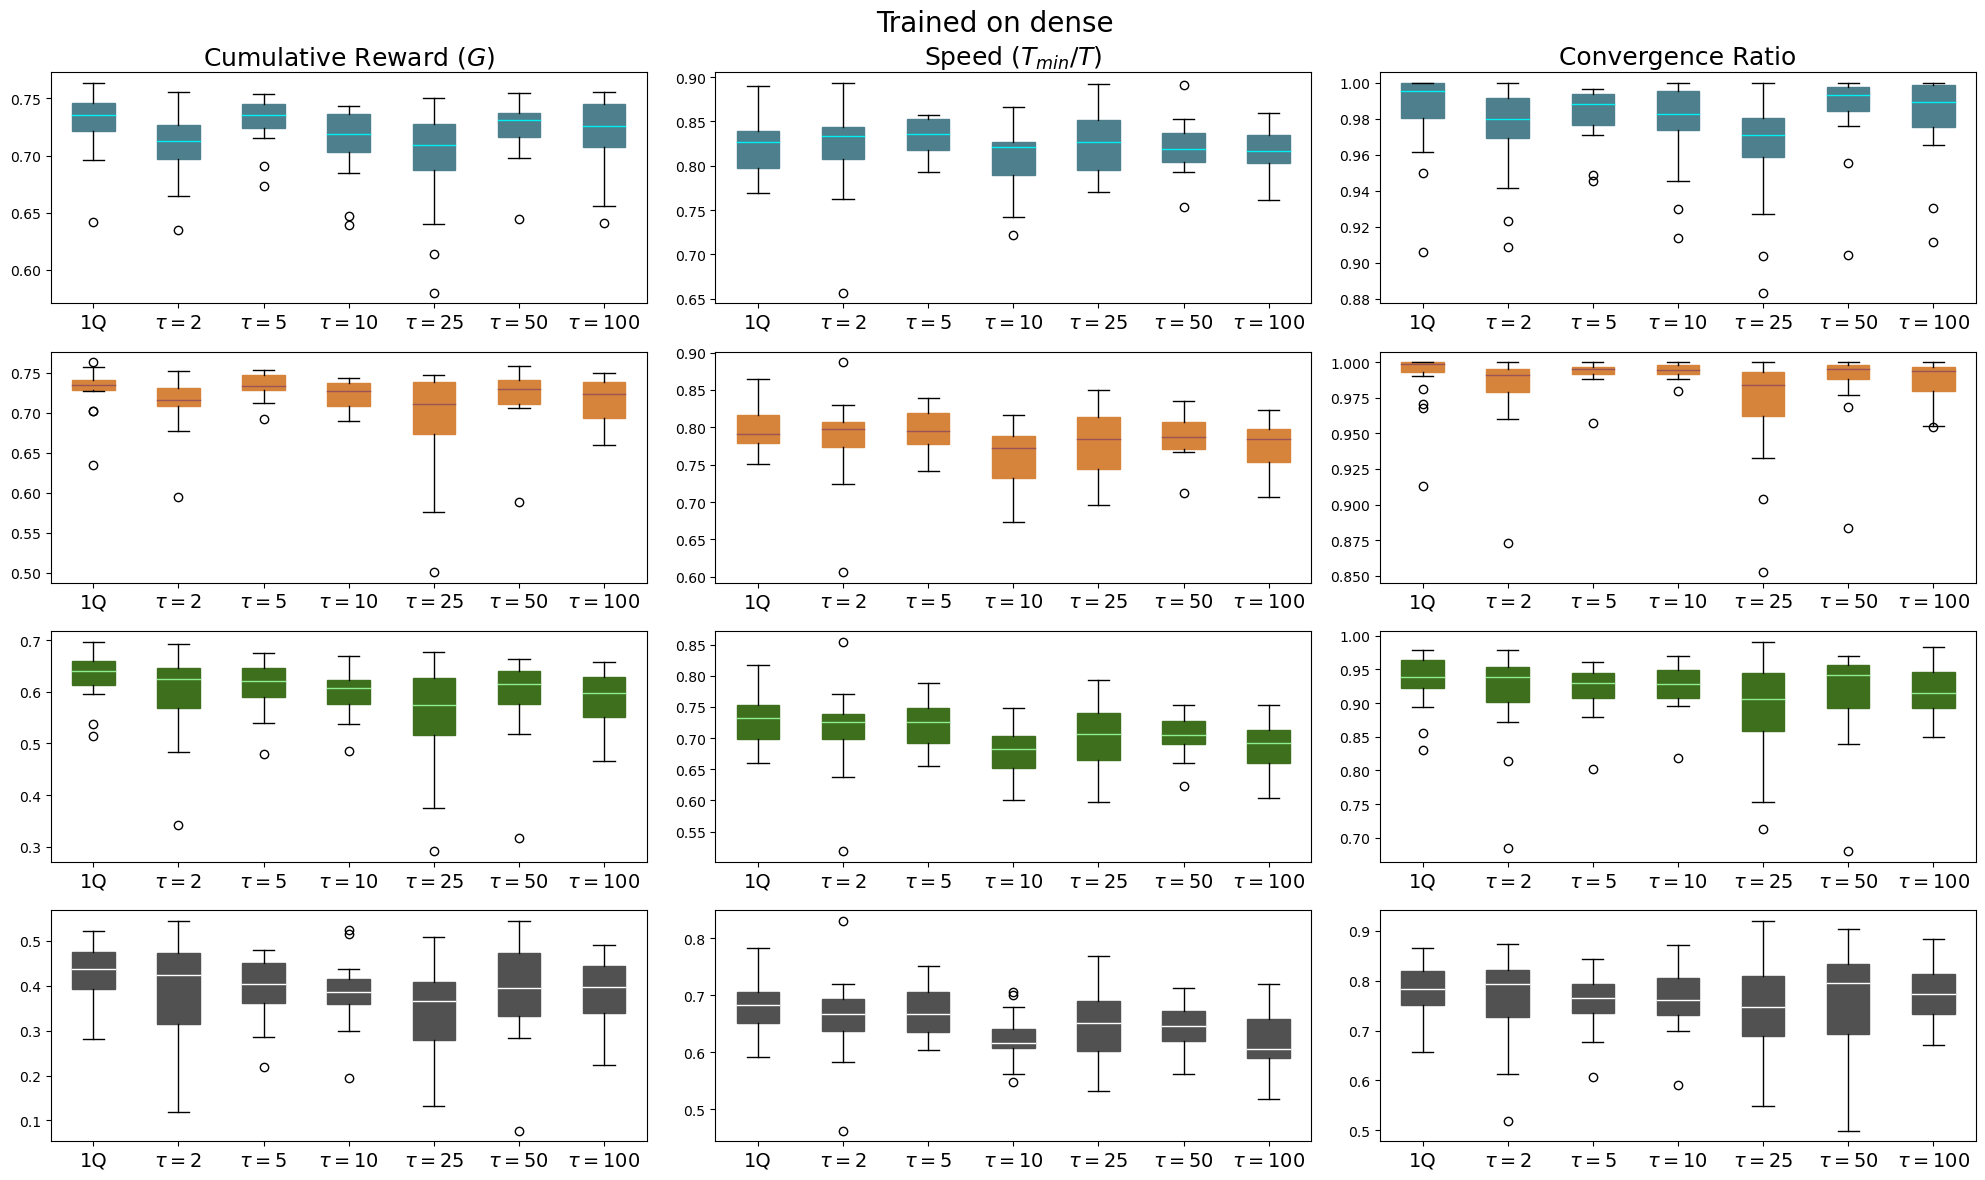

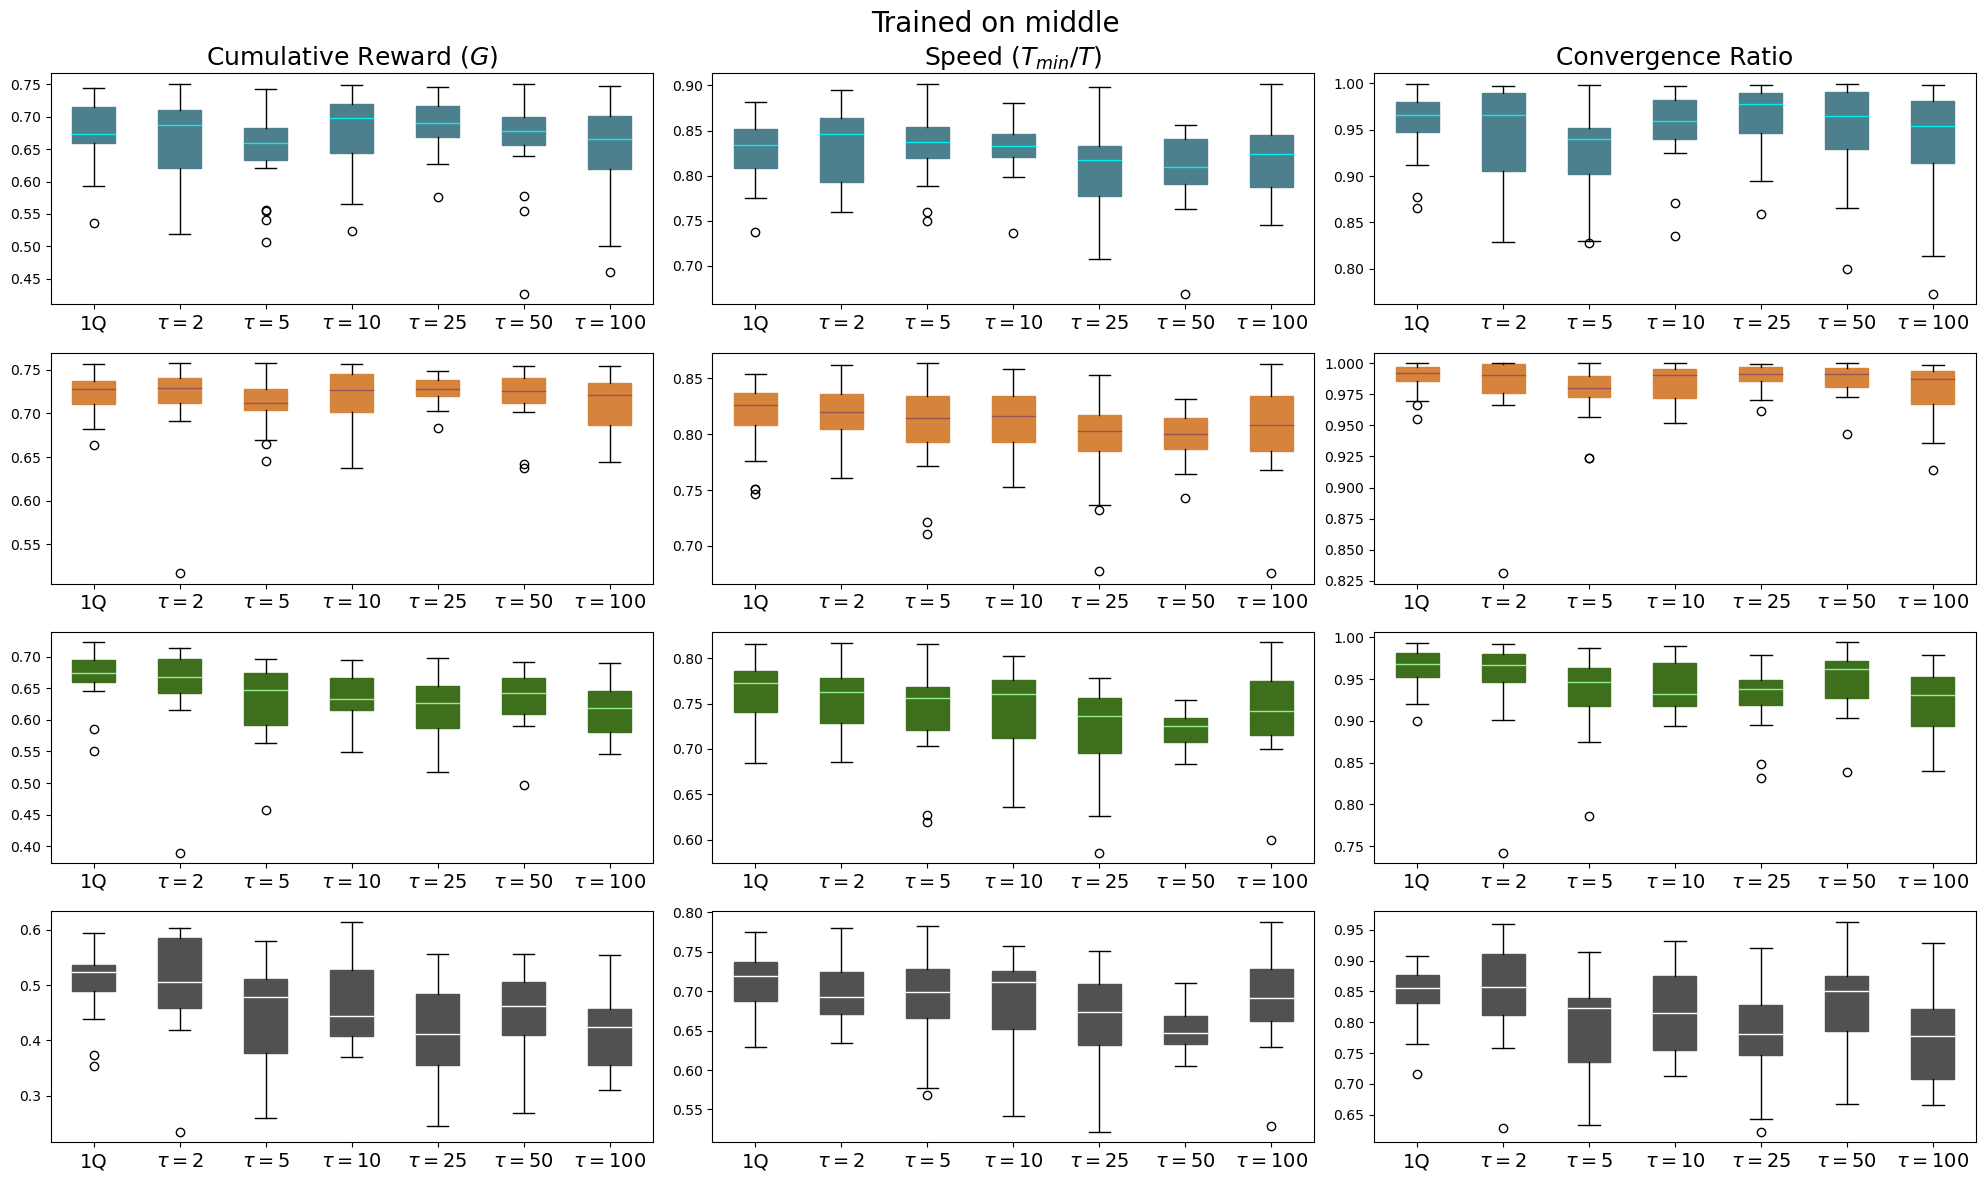

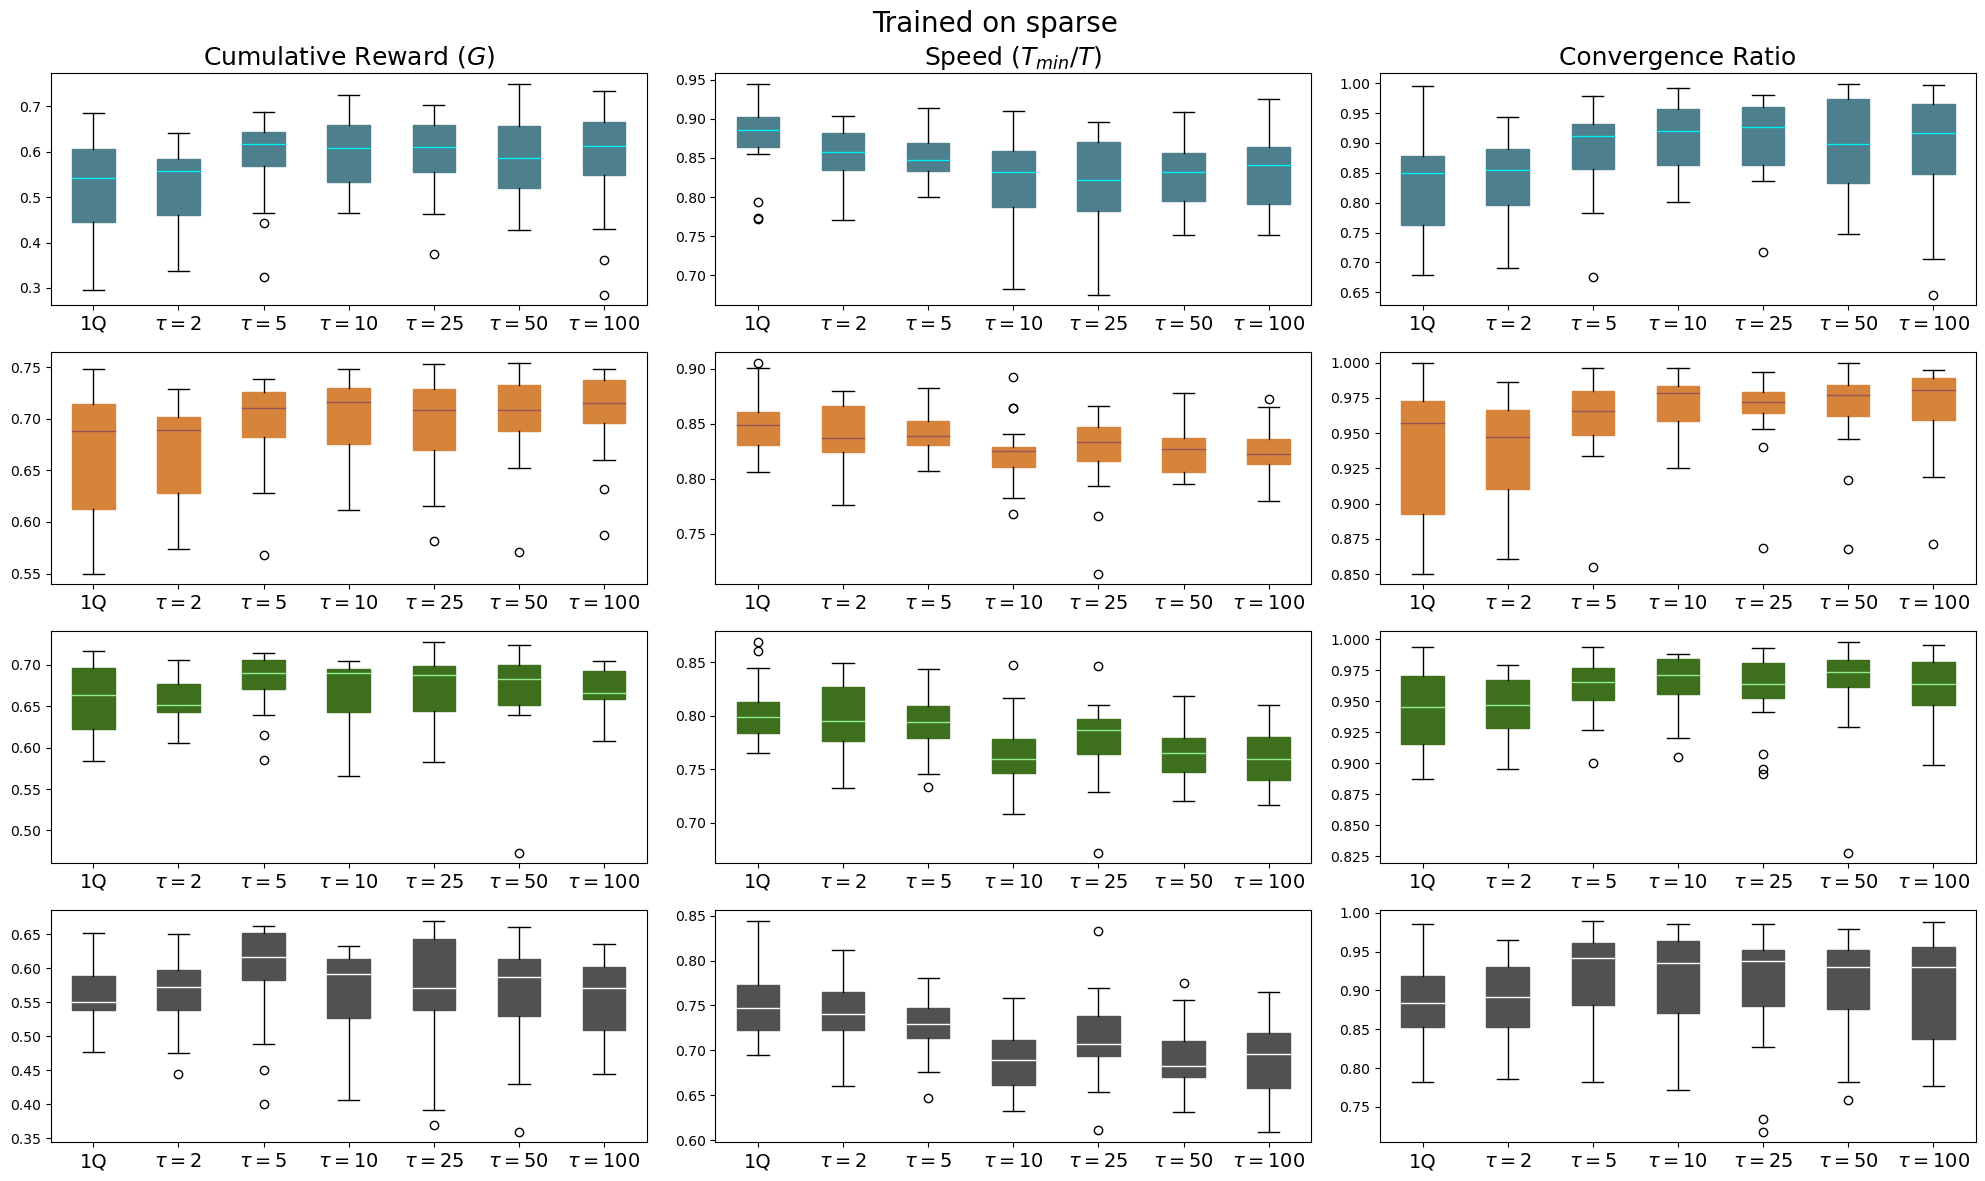

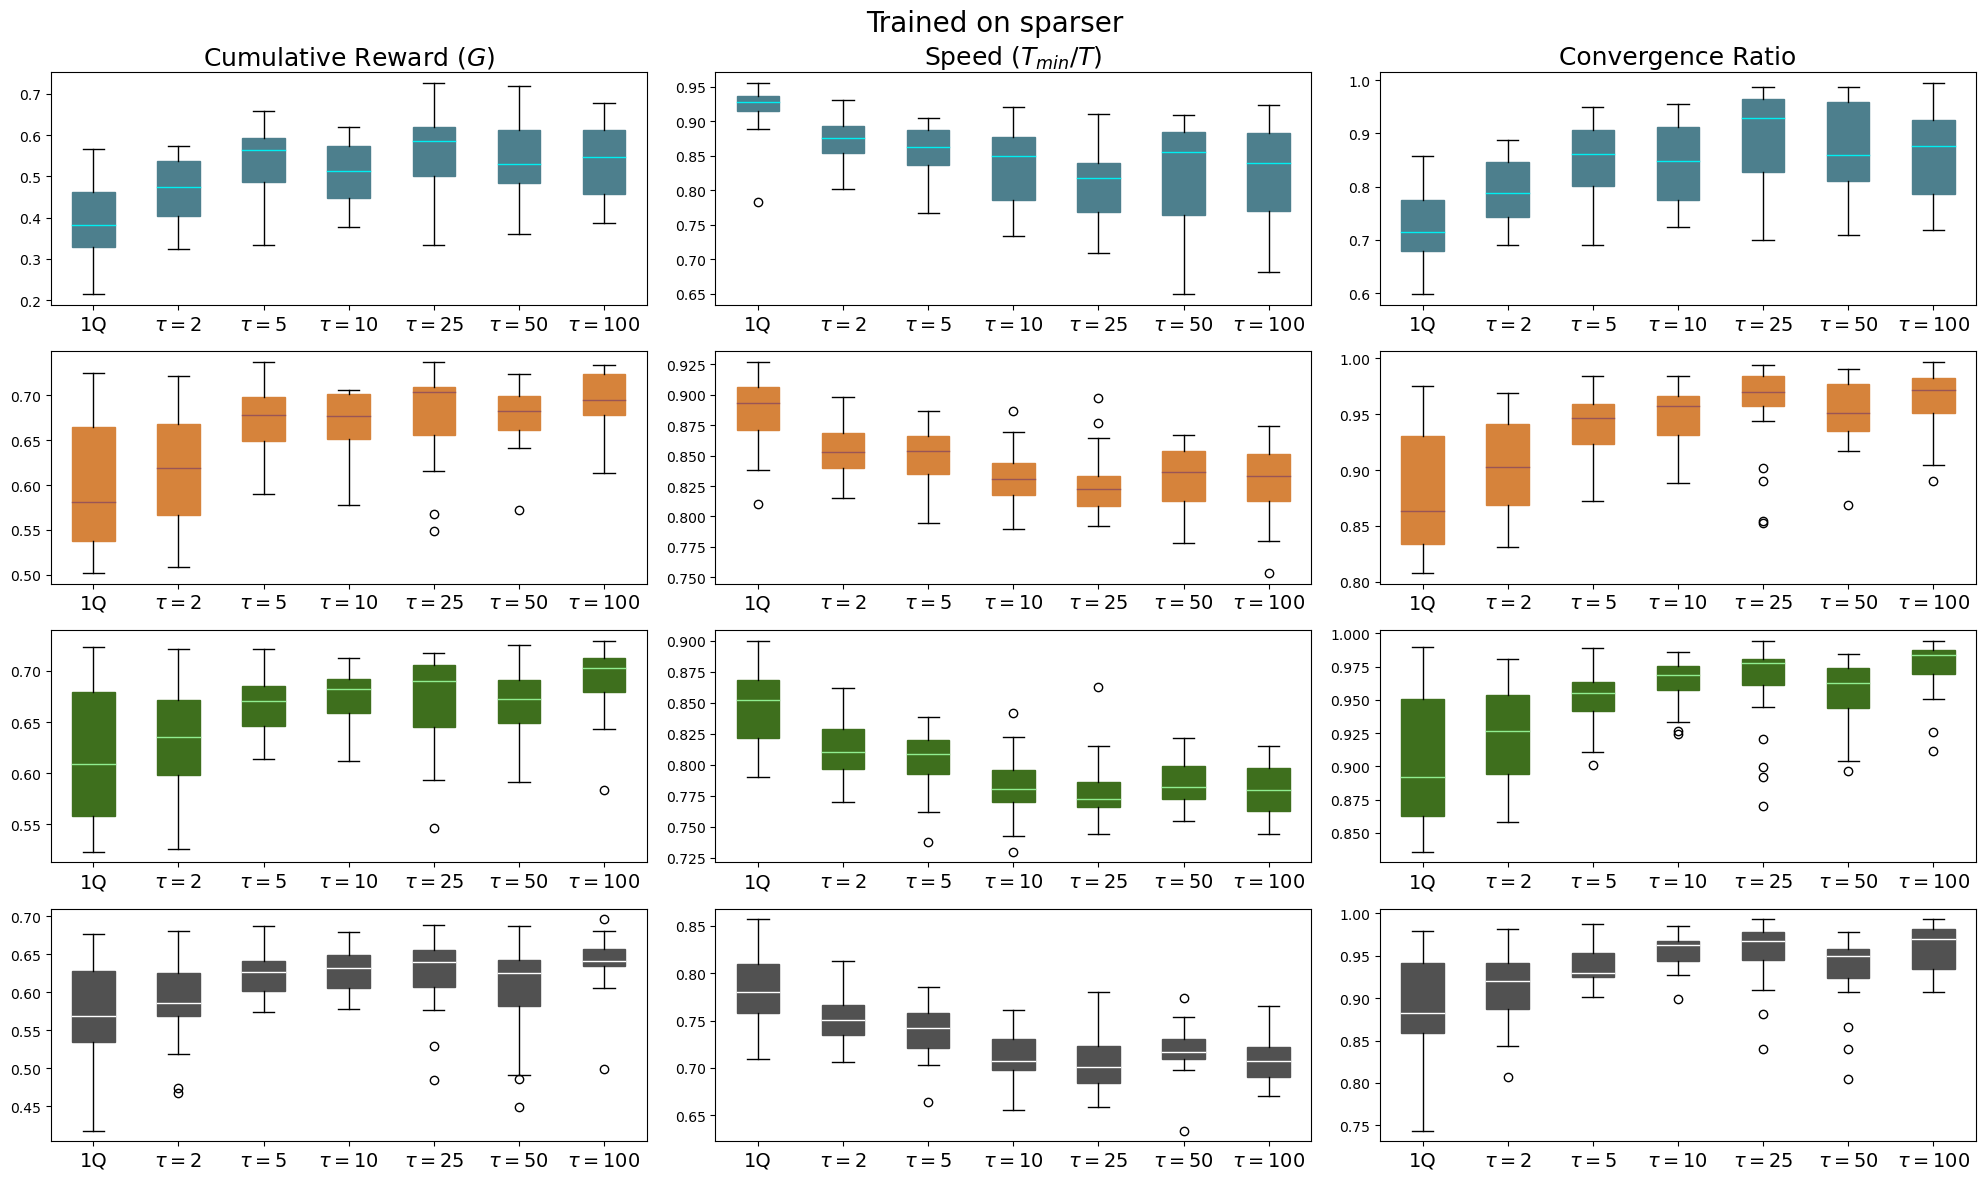

In [101]:
base_dir = "/storage/rando/pynav_results_new"

for setting in ['dense', 'middle', 'sparse', 'sparser']:
  fig, axes = plt.subplots(4, 3, figsize=(20, 12))
  for setting_idx, test_setting in enumerate(['dense', 'middle', 'sparse', 'sparser']):
    ax = axes[setting_idx]
    creward_data, speed_data, conv_data = [],[],[]
    c_rewards = []
    speeds = []
    convergence = []

    tick_labels = ['1Q'] + [f'$\\tau = {tau}$' for tau in taus]

    for seed in agent_seeds:
      with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{test_setting}/test_summary.log", 'r') as f:
        splitted = f.readline().split(',')
        c_rewards.append(float(splitted[0]))
        speeds.append(float(splitted[2]))
        convergence.append(float(splitted[4]))

    creward_data.append(c_rewards)
    speed_data.append(speeds)
    conv_data.append(convergence)

    for tau in taus:
      c_rewards = []
      speeds = []
      convergence = []
      for seed in agent_seeds:
        with open(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log", 'r') as f:
          splitted = f.readline().split(',')
          c_rewards.append(float(splitted[0]))
          speeds.append(float(splitted[2]))
          convergence.append(float(splitted[4]))

      creward_data.append(c_rewards)
      speed_data.append(speeds)
      conv_data.append(convergence)


    fig.suptitle(f"Trained on {setting}", fontsize=20)
    b1 = ax[0].boxplot(creward_data,  patch_artist=True)
    b2 = ax[1].boxplot(speed_data,  patch_artist=True)
    b3 = ax[2].boxplot(conv_data,  patch_artist=True)

    for i in range(len(b1['boxes'])):
        b1['boxes'][i].set_color(box_colors[setting_idx])
        b1['medians'][i].set_color(median_colors[setting_idx])
        b2['boxes'][i].set_color(box_colors[setting_idx])
        b2['medians'][i].set_color(median_colors[setting_idx])
        b3['boxes'][i].set_color(box_colors[setting_idx])
        b3['medians'][i].set_color(median_colors[setting_idx])

    for i in range(len(ax)):
        ax[i].set_xticks(ticks=range(1, len(taus) + 2), labels=tick_labels, fontsize=14)
#    ax[0].set_ylim([0.3, 0.8])
    if setting_idx == 0:
      ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
      ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
      ax[2].set_title("Convergence Ratio", fontsize=18)

  fig.tight_layout()
  fig.savefig(f"{out_path}/performance/tau_comparison_{setting}.pdf", bbox_inches='tight')
#  plt.close(fig)


# 2Q: Geometry of policies

In [75]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"
tau = 2
tr_max_void = [[], [], [], []]
tr_mean_void = [[], [], [], []]

tr_max_steps = [[], [], [], []]
tr_mean_steps = [[], [], [], []]


tr_max_state =  [[], [], [], []]
tr_mean_state =  [[], [], [], []]

delta = 500

opt_taus = [2, 2, 5, 25]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        with open(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/training.log", 'r') as f:
            num_void_steps, num_steps = [], []
            for line in f.readlines()[-delta:]:
                num_void_steps.append(int(line.split(',')[-1]))
                num_steps.append(int(line.split(',')[-2]))
            
            tr_max_void[i].append(np.max(num_void_steps))
            tr_mean_void[i].append(np.mean(num_void_steps))
            tr_max_steps[i].append(np.max(num_steps))
            tr_mean_steps[i].append(np.mean(num_steps))


        tr_states = np.load(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/training_max_void_lengths.npy")
        tr_max_state[i].append(np.max(tr_states[-delta:]))
        tr_mean_state[i].append(np.mean(tr_states[-delta:]))
    print(f"[--] Completed setting {setting}")



[--] Completed setting dense
[--] Completed setting middle
[--] Completed setting sparse
[--] Completed setting sparser


In [76]:

metric_names = ["mean_state", "max_state", "mean_void", "max_void", "entire_traj"]
metrics = [tr_mean_state, tr_max_state, tr_mean_void, tr_max_void, 500]

## Surge Length

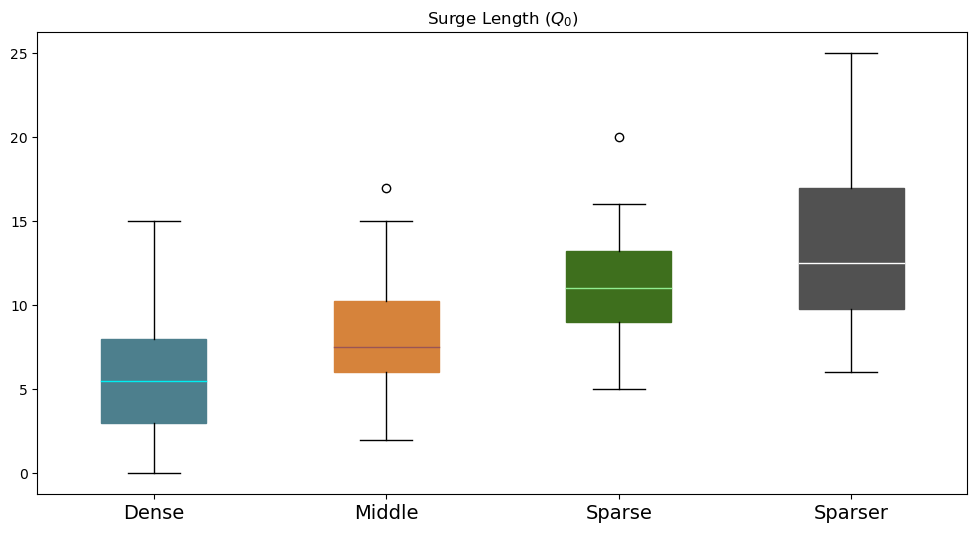

In [77]:

surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=0, count_to=502))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])


ax.set_title("Surge Length ($Q_0$)")
ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/surge_length_q0_opt_tau.pdf", bbox_inches='tight')
#plt.close(fig)


In [47]:

surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=502, count_to=1004))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Surge Length ($Q_1$)")
ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/surge_length_q1_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


## Search Length

In [48]:
for met,met_name in zip(metrics, metric_names):

  search_len = [[], [], [], []]
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0 ) ) 
          else:
            search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 


  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(search_len, patch_artist=True)
  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i])
      b['medians'][i].set_color(median_colors[i])

  ax.set_title(f"Search Length (Upwind): $Q_0$ {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)

  fig.savefig(f"{out_path}/characterization/search_length_{met_name}_q0_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)


In [49]:
for met,met_name in zip(metrics, metric_names):

  search_len = [[], [], [], []]
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502 ) ) 
          else:
            search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502 ) ) 


  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(search_len, patch_artist=True)
  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i])
      b['medians'][i].set_color(median_colors[i])

  ax.set_title(f"Search Length (Upwind): $Q_1$ {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)

  fig.savefig(f"{out_path}/characterization/search_length_{met_name}_q1_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)


## Cast-Width

In [50]:


for met,met_name in zip(metrics, metric_names):
  cast_width = [[], [], [], []]

  for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):
            if met_name == 'entire_traj':
              cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0) ) 
            else:
              cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 



  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(cast_width, patch_artist=True)

  for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])


  ax.set_title(f"Cast width ($Q_0$) : {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)
  fig.savefig(f"{out_path}/characterization/cast_width_{met_name}_q0_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)
			




In [51]:

for met,met_name in zip(metrics, metric_names):
  cast_width = [[], [], [], []]

  for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):
            if met_name == 'entire_traj':
              cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502) ) 
            else:
              cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502 ) ) 



  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(cast_width, patch_artist=True)

  for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])


  ax.set_title(f"Cast width ($Q_1$) : {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)
  fig.savefig(f"{out_path}/characterization/cast_width_{met_name}_q1_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)




## Backtracking Length

In [52]:
for met,met_name in zip(metrics, metric_names):

  bck_len = [[], [], [], []]

  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0 ) ) 
          else:
            bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 


  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(bck_len, patch_artist=True)
  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i])
      b['medians'][i].set_color(median_colors[i])

  ax.set_title(f"Backtracking Length ($Q_0$): {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)
  fig.savefig(f"{out_path}/characterization/backtracking_length_{met_name}_q0_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)



In [53]:
for met,met_name in zip(metrics, metric_names):

  bck_len = [[], [], [], []]

  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502 ) ) 
          else:
            bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502) ) 


  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(bck_len, patch_artist=True)
  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i])
      b['medians'][i].set_color(median_colors[i])

  ax.set_title(f"Backtracking Length ($Q_1$): {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)
  fig.savefig(f"{out_path}/characterization/backtracking_length_{met_name}_q1_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)



## Backtracking Init Time

In [54]:



backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, acc_steps ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time ($Q_0$)")

ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/backtracking_init_time_q0_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


In [55]:


backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, acc_steps, count_from=502 ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time ($Q_1$)")

ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/backtracking_init_time_q1_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


# Figure 5 (d): x-position of last detection before failure (2Q, only Q+, only Q-) 

In [56]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"

#tau = 2
last_detections = {setting : [[] for _ in range(3)] for setting in settings}

opt_taus = [2, 2, 5, 25]

#negative_q = [8, 17]

for (tr_idx, train_setting) in enumerate(settings):
#  print(train_setting, opt_taus[tr_idx])
#  for setting in settings:
  for (seed_idx, seed) in enumerate(agent_seeds):
    with open(f"{base_dir}/{train_setting}/agent_{seed}/tau_{opt_taus[tr_idx]}/test/{train_setting}/failed_last_detections.log", 'r') as f:
        last_detections[train_setting][0] += [float(x.split(',')[1]) for x in f.readlines()]
#    print("SINGLE", len(last_detections[train_setting][0]))
    for i in [0, 1]:       
      # if seed_idx in negative_q and tr_idx == 0 and i == 1 :
      #   with open(f"{base_dir}/{train_setting}/agent_{seed}/tau_{opt_taus[tr_idx]}/test/{train_setting}/only_Q_1/failed_last_detections.log", 'r') as f:
      #     print(seed, [float(x.split(',')[1]) for x in f.readlines()])
      #   continue

      # if i==2:
      #   with open(f"{base_dir}/{train_setting}/agent_{seed}/tau_{opt_taus[tr_idx]}/test/{train_setting}/only_Q_1/failed_last_detections.log", 'r') as f:
      #       last_detections[train_setting][i + 1] += [float(x.split(',')[1]) for x in f.readlines()]
      # else:
      with open(f"{base_dir}/{train_setting}/agent_{seed}/tau_{opt_taus[tr_idx]}/test/{train_setting}/only_Q_{i}/failed_last_detections.log", 'r') as f:
          last_detections[train_setting][i + 1] += [float(x.split(',')[1]) for x in f.readlines()]
 #           print("Q-", len(last_detections[train_setting][1]))
#            print("Q+", len(last_detections[train_setting][2]))




In [57]:
Q_plus = np.load(f"/storage/rando/pynav_results_new/two_Q/dense/agent_629/tau_2/Q_stored/Qfun.npy")


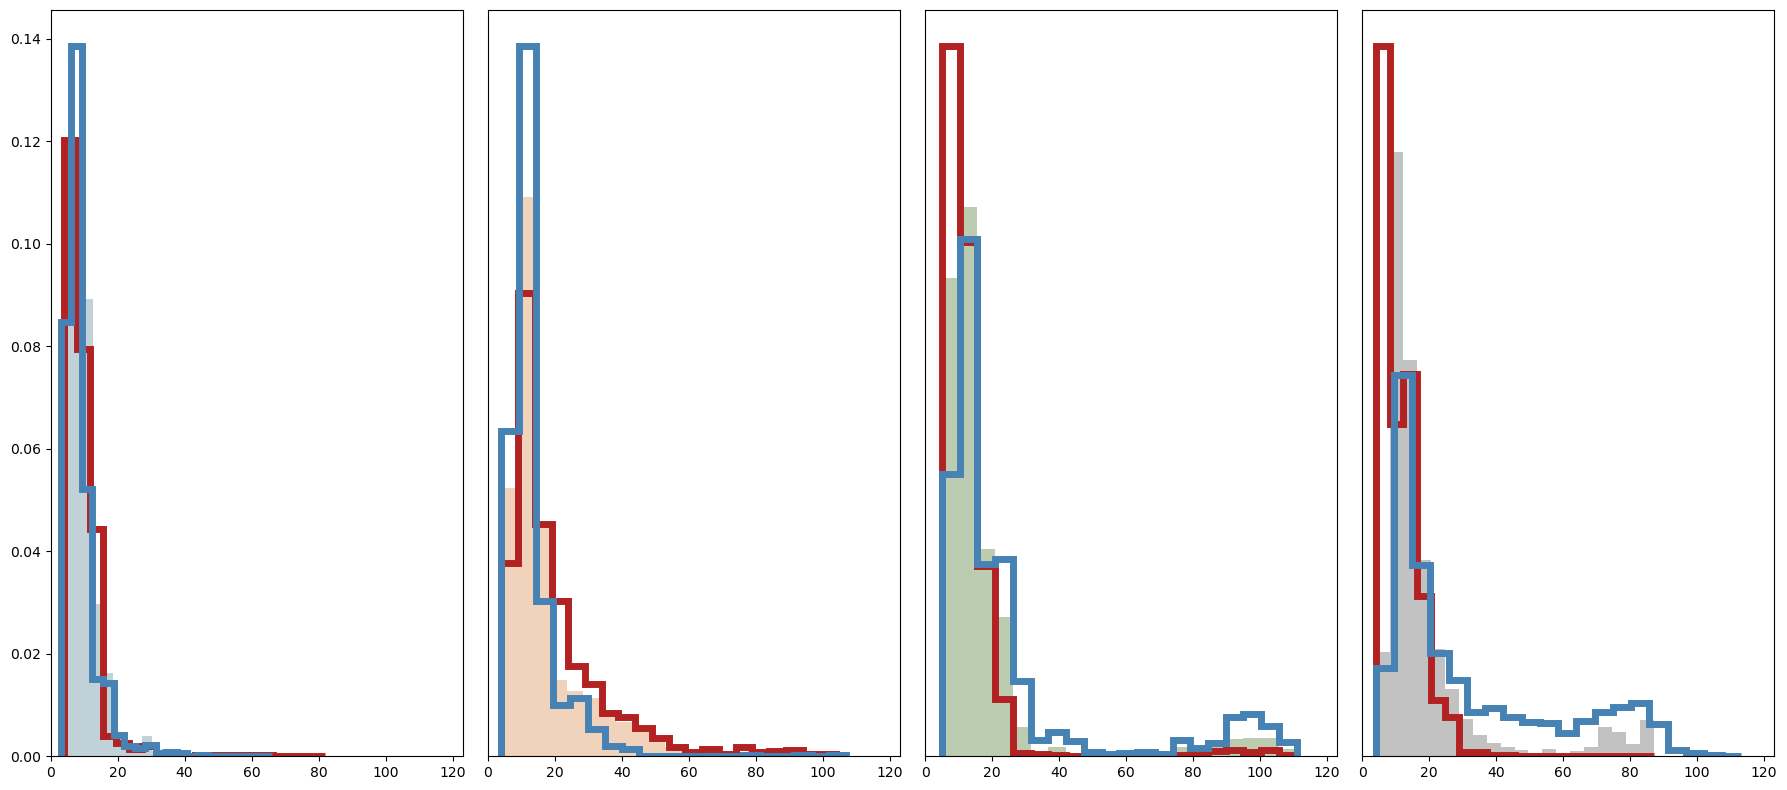

In [58]:

def get_hist(data, nbins):
  counts, bin_edges = np.histogram(data, bins=nbins, density=False)
  bin_widths = np.diff(bin_edges)

  density = counts / (np.sum(counts) * bin_widths)
  print(density)
  print(np.sum(density))
  print("-------")
  bin_centers = bin_edges[:-1] + bin_widths / 2

#t_labels = ['two Q', 'only $Q^-$', 'only $Q^+$']
q_colors = [
    "#4682B4", # Q -
    "#B22222" # Q +
]

fig, axes = plt.subplots(1, 4, figsize=(18, 8))
#for ax_idx in range(len(axes)):
#  ax = axes[ax_idx]
#  fig.suptitle(f"Trained in {train_setting} (tau = {tau})", fontsize=20)
for (idx, label) in zip(range(4), data_labels):

#      axes[idx].set_title(f"Trained and Test in {label}", fontsize=16)
#    print(len(last_detections[data_labels[idx].lower()]))
#    violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=[0, 1, 2], widths=0.9, bw_method=0.2)
#  print(last_detections[data_labels[idx].lower()][ax_idx])
#  print("---")
  bins = 20
  
  
  axes[idx].hist(last_detections[data_labels[idx].lower()][2], bins=bins, density=True, histtype='step', linestyle='-', color=q_colors[1], label='only $Q^+$', linewidth=5.0)



  axes[idx].hist(last_detections[data_labels[idx].lower()][1], bins=bins, density=True, histtype='step', linestyle='-', color=q_colors[0], label='only $Q^-$', linewidth=5.0)
  axes[idx].hist(last_detections[data_labels[idx].lower()][0], bins=bins, density=True, alpha=0.35, color=box_colors[idx], linewidth=1.5)
#  if idx == 0:
#    axes[idx].hist(last_detections[data_labels[idx].lower()][3], bins=bins, density=True, histtype='step', linestyle='--', color='gray', label='only $Q^+$', linewidth=2.50)

#  axes[idx].set_ylim([0.0, 0.14])
#  axes[idx].set_yscale('log')
  if idx > 0:
    axes[idx].set_yticks([])
  axes[idx].set_xlim([0, data.shape[2]])
#  axes[0].legend()
#axes[0].legend()
#      for i in range(3):
#        axes[idx].hist(last_detections[data_labels[idx].lower()][i], bins=40, density=True,  color=box_colors[idx], label='two Q', linewidth=2.0)

    # for e in violin['bodies']:
    #     e.set_facecolor(box_colors[idx])
    #     e.set_edgecolor(box_colors[idx])

    # for lab in ['cbars', 'cmins', 'cmaxes']:
    #     violin[lab].set_edgecolor(box_colors[idx])
    #     violin[lab].set_facecolor(box_colors[idx])
        
#    axes[idx].set_ylim([0, 30])
#    axes[idx].set_xticks(range(3), ['two Q', 'only $Q^-$', 'only $Q^+$'])
fig.tight_layout()
fig.savefig(f"./paper_plots/two_Q/single_vs_two/failed_positions_vs_single_opt_tau.pdf", bbox_inches='tight')

#plt.close(fig)

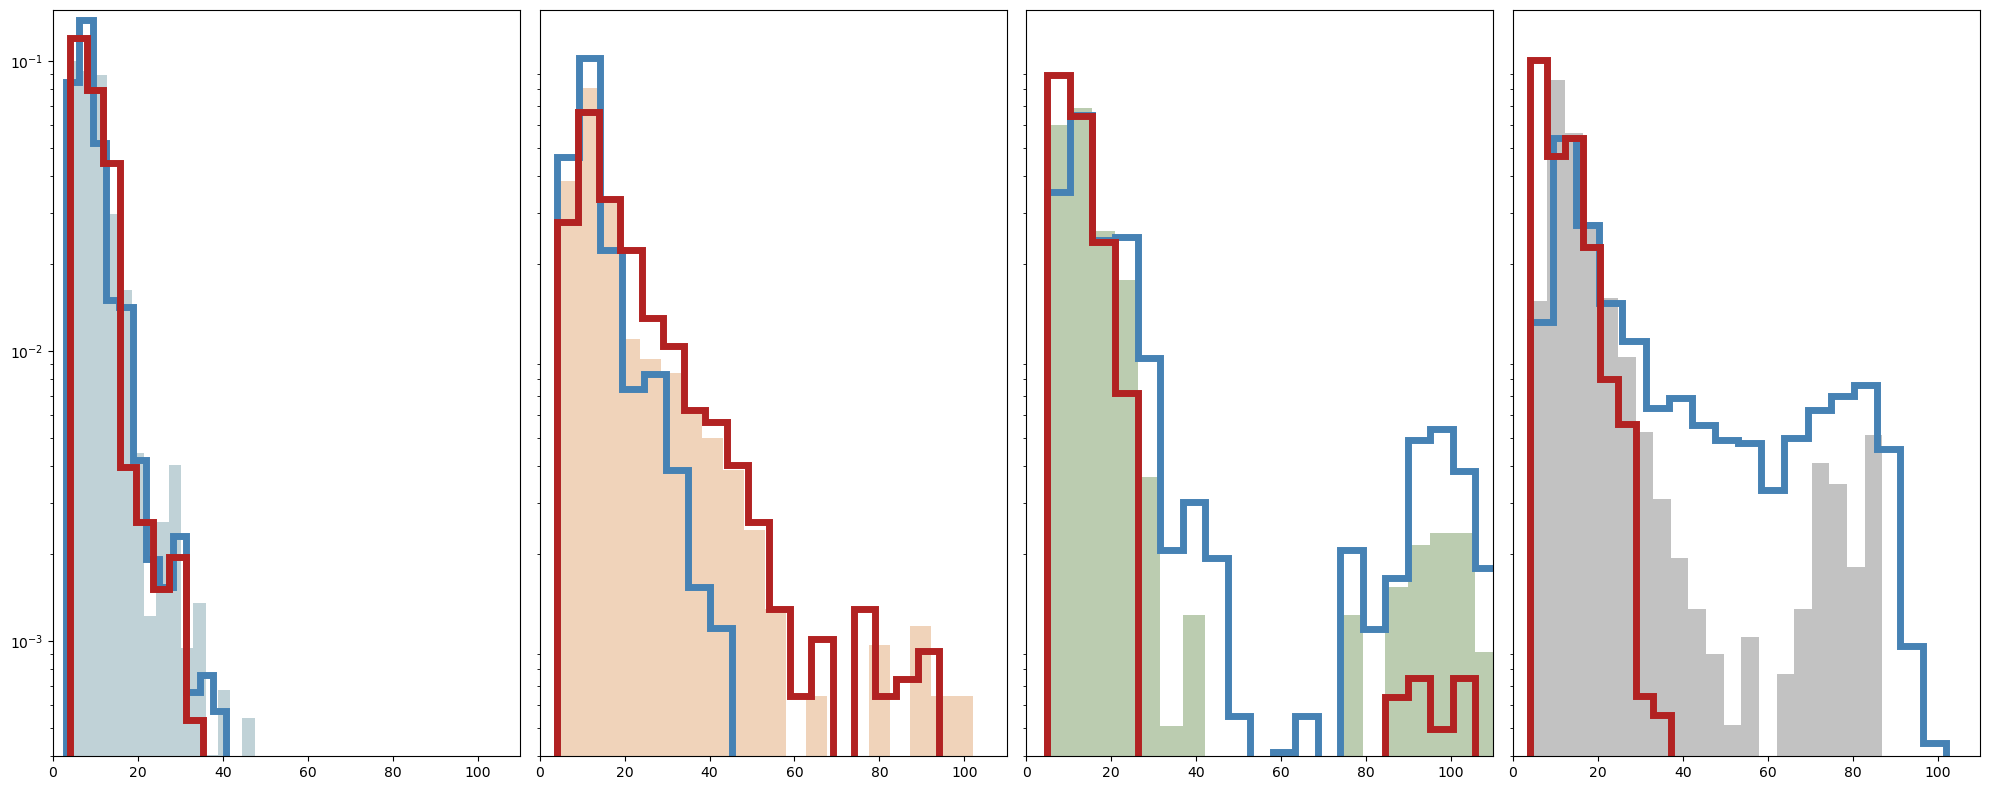

In [59]:
from scipy.stats import gaussian_kde



fig, axes = plt.subplots(1, 4, figsize=(20, 8))
#for ax_idx in range(len(axes)):
#  ax = axes[ax_idx]
#  fig.suptitle(f"Trained in {train_setting} (tau = {tau})", fontsize=20)
for (idx, label) in zip(range(4), data_labels):

#      axes[idx].set_title(f"Trained and Test in {label}", fontsize=16)
#    print(len(last_detections[data_labels[idx].lower()]))
#    violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=[0, 1, 2], widths=0.9, bw_method=0.2)
#  print(last_detections[data_labels[idx].lower()][ax_idx])
#  print("---")
  bins = 20
#  kde_qplus = gaussian_kde(last_detections[data_labels[idx].lower()][2])
#  kde_qminus = gaussian_kde(last_detections[data_labels[idx].lower()][1])
#  kde_outlier = gaussian_kde(last_detections[data_labels[idx].lower()][3])
#  kde_two_q = gaussian_kde(last_detections[data_labels[idx].lower()][0])
  axes[idx].hist(last_detections[data_labels[idx].lower()][1], bins=bins, density=True, histtype='step', linestyle='-', color=q_colors[0], label='only $Q^-$', linewidth=5.0)
  axes[idx].hist(last_detections[data_labels[idx].lower()][2], bins=bins, density=True, histtype='step', linestyle='-', color=q_colors[1], label='only $Q^+$', linewidth=5.0)
  x_range = np.linspace(-0.5, data.shape[2] + 1, data.shape[2] + 1)
#  y_plus = kde_qplus(x_range)
#  axes[idx].plot(x_range, kde_qplus(x_range), color=q_colors[1], linewidth=5.0)
#  axes[idx].plot(x_range, kde_qminus(x_range), color=q_colors[0], linewidth=5.0)
#  if idx == 0:
#    axes[idx].plot(x_range, kde_outlier(x_range), '--', color='gray', linewidth=2.5)
#    axes[idx].hist(last_detections[data_labels[idx].lower()][3], bins=bins, density=True, histtype='step', linestyle='--', color='gray', label='only $Q^+$', linewidth=2.50)

#  axes[idx].hist(last_detections[data_labels[idx].lower()][1], bins=bins, density=True, histtype='step', linestyle='-', color=q_colors[0], label='only $Q^-$', linewidth=5.0)
  axes[idx].hist(last_detections[data_labels[idx].lower()][0], bins=bins, density=True, alpha=0.35, color=box_colors[idx], linewidth=1.4)
  axes[idx].set_ylim([4e-4, 0.15])
  axes[idx].set_yscale('log')
  axes[idx].set_xlim([0, 110])
  if idx > 0:
    axes[idx].set_yticks([])
#  else:
#    axes[idx].legend()
#axes[0].legend()
#      for i in range(3):
#        axes[idx].hist(last_detections[data_labels[idx].lower()][i], bins=40, density=True,  color=box_colors[idx], label='two Q', linewidth=2.0)

    # for e in violin['bodies']:
    #     e.set_facecolor(box_colors[idx])
    #     e.set_edgecolor(box_colors[idx])

    # for lab in ['cbars', 'cmins', 'cmaxes']:
    #     violin[lab].set_edgecolor(box_colors[idx])
    #     violin[lab].set_facecolor(box_colors[idx])
        
#    axes[idx].set_xticks(range(3), ['two Q', 'only $Q^-$', 'only $Q^+$'])
fig.tight_layout()
fig.savefig(f"./paper_plots/two_Q/single_vs_two/failed_positions_vs_single_opt_tau_kde_hist.pdf", bbox_inches='tight')

#plt.close(fig)

# Figure 5 (c): Performance Comparison (1Q, 2Q, Q-, Q+, 2Q heuristic, POMDP)

single Q:  [0.6962850239070032, 0.7203515040917586, 0.7456961227882243, 0.6419215769174482, 0.7030017883924319, 0.7501203271271417, 0.7184087586060446, 0.7488345172775197, 0.7427862119308241, 0.734480793830857, 0.7422804460383667, 0.7225153410401026, 0.7636677669354611, 0.7369763405359548, 0.7459755595080639, 0.7270153870503191, 0.726088038550761, 0.7594413235015852, 0.7330299659348636, 0.7357337654867856] []
2Q:  [0.6346725967228277, 0.6857493618918946, 0.7351314904047475, 0.7157831988580522, 0.7291923697478963, 0.7419096421892573, 0.7249553850887, 0.708430412530904, 0.6978675510269915, 0.7101827442572757, 0.6946232099390077, 0.6833195729430469, 0.7174101704926306, 0.7055834790016894, 0.7558449972110138, 0.7067682396095178, 0.7181537005124017, 0.7255776837877591, 0.7392413457560832, 0.6643313637704665] []
Q-:  [0.5246074611930586, 0.6839388292365474, 0.6256247184126398, 0.7124312018324805, 0.7415100377792988, 0.7322279057515916, 0.7498682811574496, 0.7214339066478579, 0.69989676860352

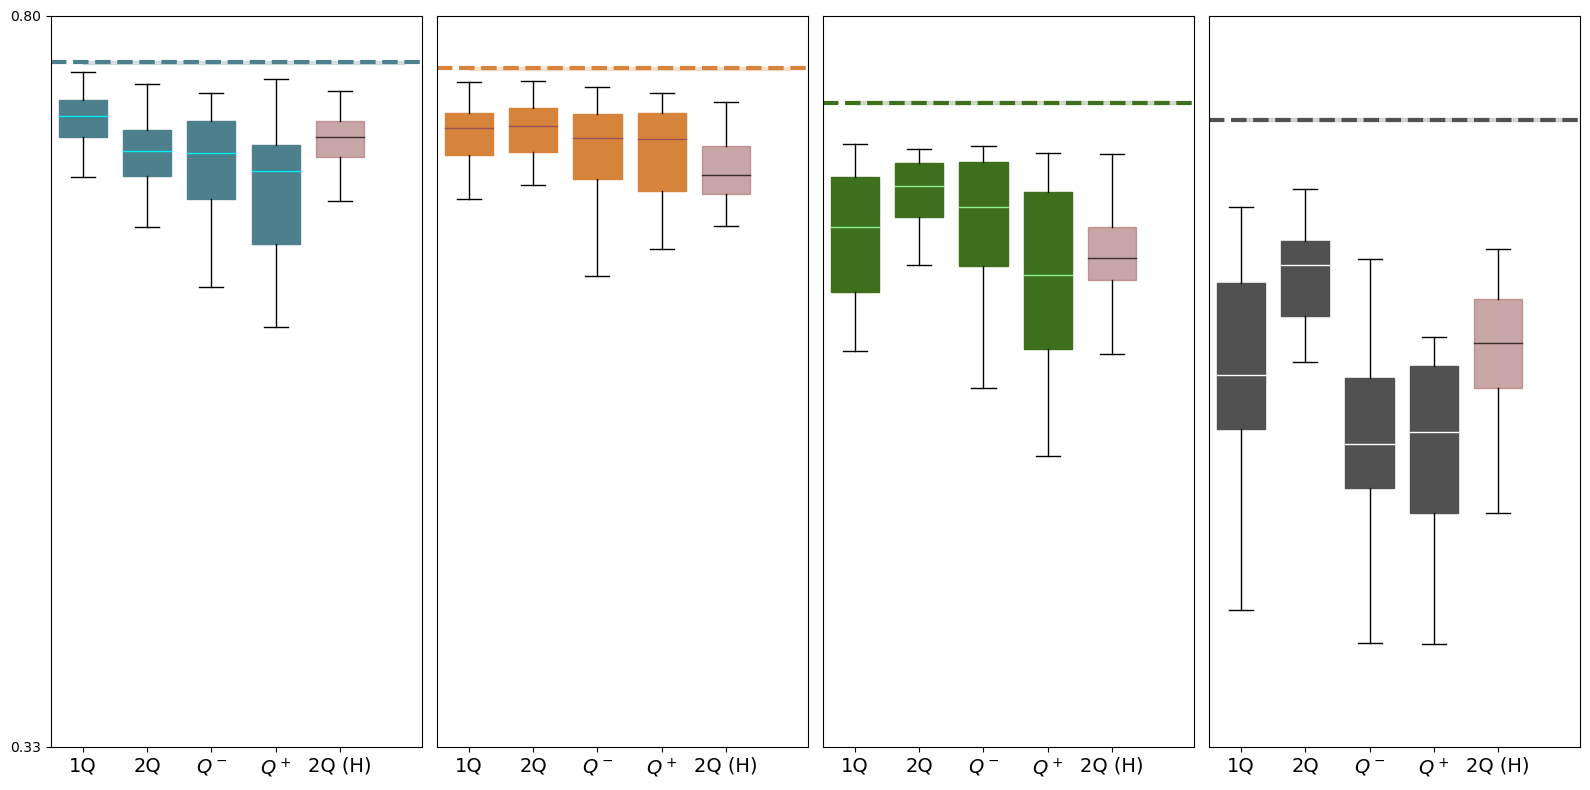

In [60]:
base_dir = "/storage/rando/pynav_results_new"
opt_taus = [2, 2, 5, 25]
taus = [2, 5, 10, 25, 50, 100]

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]


color_last = "#A4686896"
color_last_med = "#3E2D2D"


#for (tr_idx, setting) in enumerate(['dense', 'middle', 'sparse', 'sparser']):
fig, axes = plt.subplots(1, 4, figsize=(16, 8))
for setting_idx, setting in enumerate(['dense', 'middle', 'sparse', 'sparser']):
  ax = axes[setting_idx]
  creward_data, speed_data, conv_data = [],[],[]
  # c_rewards = []
  # speeds = []
  # convergence = []


  # for seed in agent_seeds:
  #   with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{setting}/test_summary.log", 'r') as f:
  #     splitted = f.readline().split(',')
  #     c_rewards.append(float(splitted[0]))
  #     speeds.append(float(splitted[2]))
  #     convergence.append(float(splitted[4]))

  # creward_data.append(c_rewards)
  # speed_data.append(speeds)
  # conv_data.append(convergence)


  c_rewards = []
  speeds = []
  convergence = []
  for seed in agent_seeds:
    with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))
  print("single Q: ", c_rewards, np.argwhere(np.array(c_rewards) < 0.0).flatten())

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)


  tick_labels = ['2Q', '$Q^-$', '$Q^+$'] + [f'$\\tau = {tau}$' for tau in taus]
  c_rewards = []
  speeds = []
  convergence = []
  for seed in agent_seeds:
    with open(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[setting_idx]}/test/{setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))
      
  print("2Q: ", c_rewards, np.argwhere(np.array(c_rewards) < 0.0).flatten())

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)




  c_rewards = []
  speeds = []
  convergence = []
  for seed in agent_seeds:
    with open(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[setting_idx]}/test/{setting}/only_Q_0/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))
      
  print("Q-: ", c_rewards, np.argwhere(np.array(c_rewards) < 0.0).flatten())

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)

  c_rewards = []
  speeds = []
  convergence = []
  for seed in agent_seeds:
    with open(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[setting_idx]}/test/{setting}/only_Q_1/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))
  print("Q+: ", c_rewards, np.argwhere(np.array(c_rewards) < 0.0).flatten())

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)

  c_rewards = []
  speeds = []
  convergence = []
  for seed in agent_seeds:
    with open(f"{base_dir}/two_single_Q/agent_{seed}/tau_50/test/{setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))
      
  print("2Q (Heuristic): ", c_rewards, np.argwhere(np.array(c_rewards) < 0.0).flatten())

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)



  width = 0.75
#  fig.suptitle(f"Trained on {setting}", fontsize=20)

#  for i in range(4):
  ax.axhline(y=mu_G_pomdp[setting_idx],     color=box_colors[setting_idx], linestyle='--', lw=3)
  ax.fill_between([1, 6], mu_G_pomdp[setting_idx] - std_G_pomdp[setting_idx], mu_G_pomdp[setting_idx] + std_G_pomdp[setting_idx], color=box_colors[setting_idx], alpha=0.2)
#    ax[1].axhline(y=mu_speed_pomdp[setting_idx], color=box_colors[setting_idx], linestyle='--', lw=3)
#    ax[1].fill_between([0, max(positions)], mu_speed_pomdp[setting_idx] - std_speed_pomdp[setting_idx], mu_speed_pomdp[setting_idx] + std_speed_pomdp[setting_idx], color=box_colors[setting_idx], alpha=0.2)

#    ax[2].axhline(y=mu_conv_pomdp[i],  color=box_colors[i], linestyle='--', lw=3)
  b1 = ax.boxplot(creward_data, widths=width, showfliers=False,  patch_artist=True)
  # b2 = ax[1].boxplot(speed_data,  patch_artist=True)
  # b3 = ax[2].boxplot(conv_data,  patch_artist=True)

  for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[setting_idx])
      b1['medians'][i].set_color(median_colors[setting_idx])

      b1['boxes'][-1].set_color(color_last)
      b1['medians'][-1].set_color(color_last_med)

      # b2['boxes'][i].set_color(box_colors[setting_idx])
      # b2['medians'][i].set_color(median_colors[setting_idx])
      # b3['boxes'][i].set_color(box_colors[setting_idx])
      # b3['medians'][i].set_color(median_colors[setting_idx])
  ax.set_xticks(ticks=range(1, 6), labels=['1Q', '2Q', '$Q^-$', '$Q^+$', '2Q (H)'], fontsize=14)

  # for i in range(len(ax)):
  #     ax[i].set_xticks(ticks=range(1, 4), labels=['1Q', '2Q (trained)', '2Q (heuristic)'], fontsize=14)
  if setting_idx > 0:
    ax.set_yticks([])
  else:
    ax.set_yticks([0.33, 0.8])

  ax.set_ylim([0.33, 0.8])
#  if setting_idx > 0:
#    ax.set_yticks([])
#    ax.set_axis_off()
#  ax.set_xlim([-12.0, 12.5])
#  ax[0].set_aspect(aspect=0.24)
#  if setting_idx == 0:
#    ax.set_title("Cumulative Reward ($G$)", fontsize=18)
    # ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
    # ax[2].set_title("Convergence Ratio", fontsize=18)

fig.tight_layout()
print(out_path)
fig.savefig(f"{out_path}/performance/2q_vs_qmin_qplus_native_with_single.pdf", bbox_inches='tight')
#plt.close(fig)


# Figure 5 (a): Geometry Comparison (Two Q, Q-, Q+, single Q)

In [78]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new"

tau = 5

### Surge Length

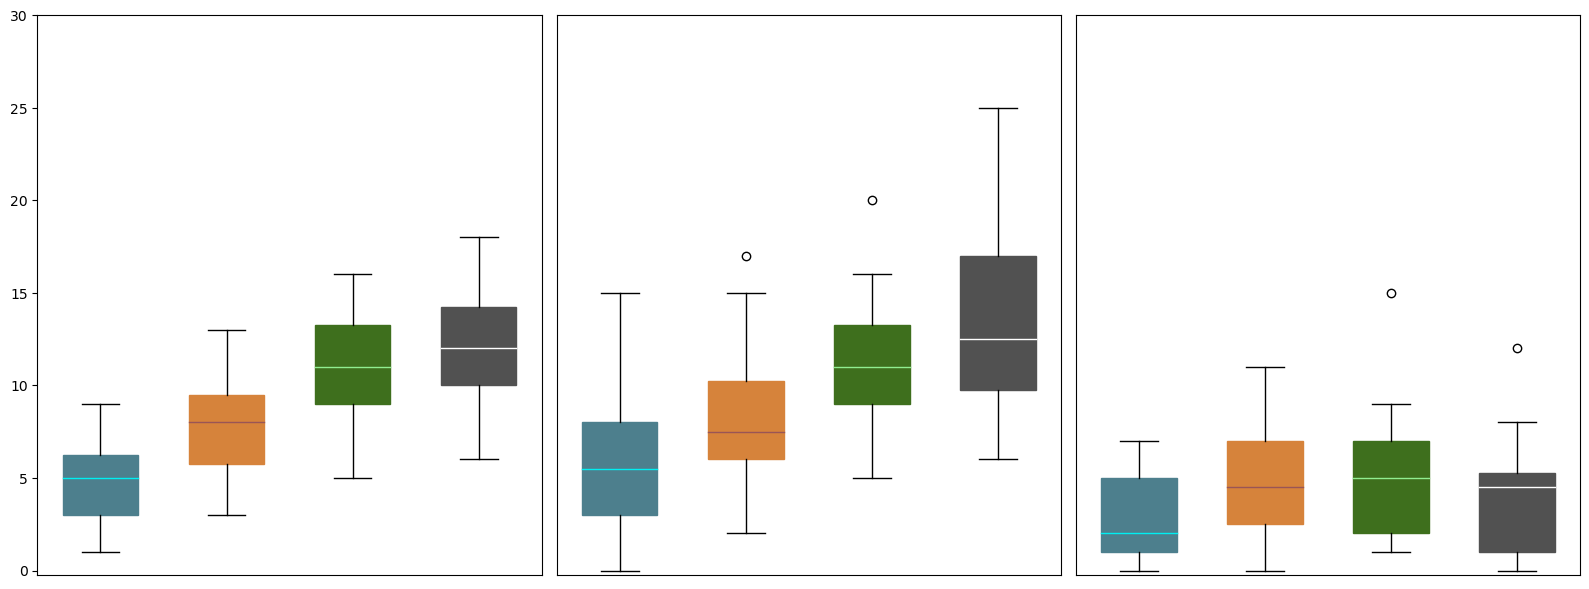

In [79]:

os.makedirs(f"{out_path}/2vs1_characterization", exist_ok=True)
surge_length_single = [[], [], [], []]
surge_length_Q0 = [[], [], [], []]
surge_length_Q1 = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length_single[i].append(compute_surge_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=0, count_to=502))
        surge_length_Q0[i].append(compute_surge_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=0, count_to=502))
        surge_length_Q1[i].append(compute_surge_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=502, count_to=1024))


surge_lengths = [surge_length_single, surge_length_Q0, surge_length_Q1]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes = axes.flatten()
for i in range(len(axes)):
  ax = axes[i]
  b = ax.boxplot(surge_lengths[i], widths=0.6, patch_artist=True)
#  b2 = ax.boxplot(surge_length_Q1, patch_artist=True)
  for j in range(len(b['boxes'])):
      b['boxes'][j].set_color(box_colors[j])
      b['medians'][j].set_color(median_colors[j])

  if i > 0:
    ax.set_yticks([])
  #   if i == 1:
  #     ax.set_title("$Q^-$")
  #   else:
  #     ax.set_title(f"$Q^+$")
  # else:
  #   ax.set_title("1Q")
#  ax.set_xticklabels(data_labels, fontsize=14)
  ax.set_xticks([])
  ax.set_ylim([-0.25, 30])
fig.tight_layout()
fig.savefig(f"{out_path}/2vs1_characterization/surge_length_2qvs1q_opt_tau.pdf", bbox_inches='tight')
#plt.close(fig)


### Backtracking init time

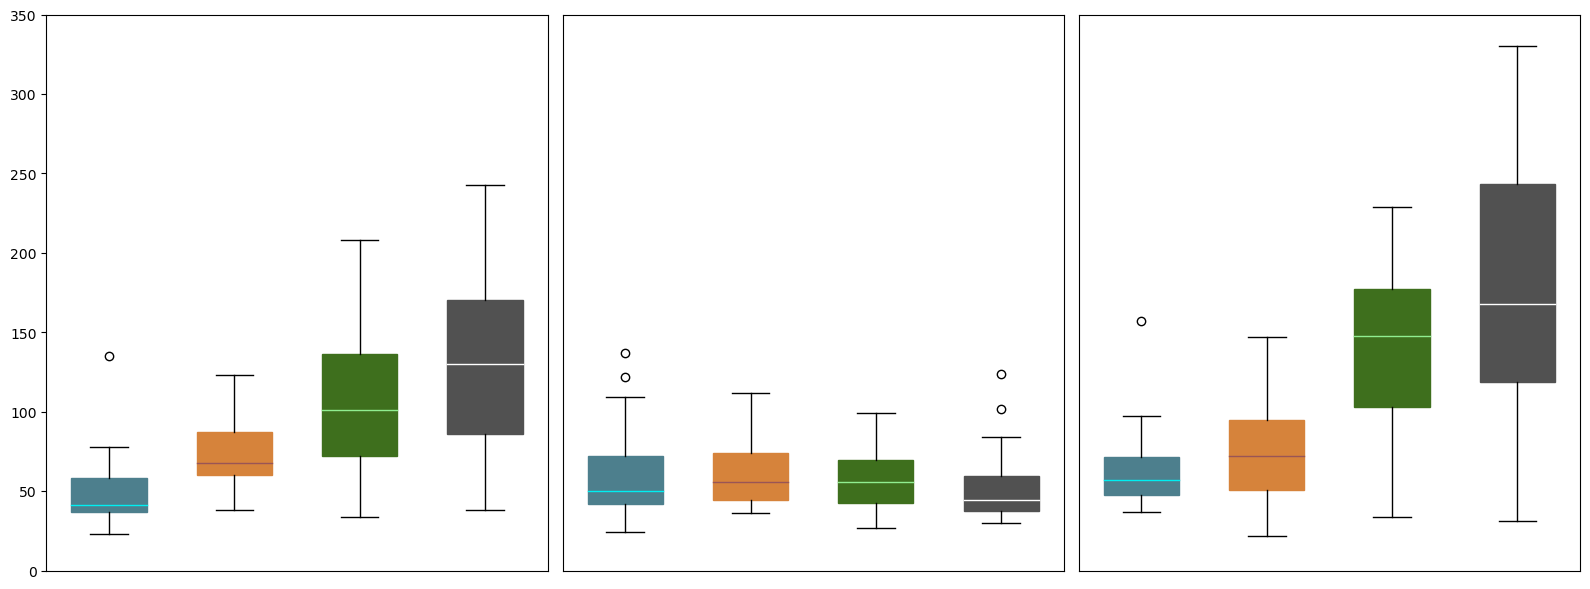

In [80]:

surge_length_single = [[], [], [], []]
surge_length_Q0 = [[], [], [], []]
surge_length_Q1 = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length_single[i].append(compute_backtracking_init_time(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", 502, 2))
        surge_length_Q0[i].append(compute_backtracking_init_time(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, 2, count_from=1))
        surge_length_Q1[i].append(compute_backtracking_init_time(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, 2, count_from=502))


surge_lengths = [surge_length_single, surge_length_Q0, surge_length_Q1]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes = axes.flatten()
for i in range(len(axes)):
  ax = axes[i]
  b = ax.boxplot(surge_lengths[i], widths=0.6, patch_artist=True)
#  b2 = ax.boxplot(surge_length_Q1, patch_artist=True)
  for j in range(len(b['boxes'])):
      b['boxes'][j].set_color(box_colors[j])
      b['medians'][j].set_color(median_colors[j])

  # if i > 0:
  #   ax.set_title(f"Backtracking init time ($Q_{i - 1}$)")
  # else:
  #   ax.set_title("Backtracking init time (Single Q)")
  # if i > 0:
  #   if i == 1:
  #     ax.set_title("$Q^-$")
  #   else:
  #     ax.set_title(f"$Q^+$")
  # else:
  #   ax.set_title("1Q")
  ax.set_xticks([])
#  ax.set_xticklabels(data_labels, fontsize=14)
  ax.set_ylim([-0.5, 350])
  if i > 0:
    ax.set_yticks([])
fig.tight_layout()
fig.savefig(f"{out_path}/2vs1_characterization/backtracking_init_time_2qvs1q_opt_tau.pdf", bbox_inches='tight')
#plt.close(fig)


## Other metrics

In [81]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
base_dir = "/storage/rando/pynav_results_new/"

metric_names = ['tr_max_void', 'tr_mean_void', 'tr_max_steps', 'tr_mean_steps', 'tr_max_state', 'tr_mean_state']
agent_names = ['single_Q', 'two_Q']


metrics = {name: {metric: [[], [], [], []] for metric in metric_names} for name in agent_names}


delta = 500
for agent_name in agent_names:
  for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
      if agent_name == 'single_Q':
        agent_dir = f"{base_dir}/single_Q/{setting}/agent_{seed}"
      else:
        agent_dir = f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}"

      with open(f"{agent_dir}/training.log", 'r') as f:
          num_void_steps, num_steps = [], []
          for line in f.readlines()[-delta:]:
              num_void_steps.append(int(line.split(',')[-1]))
              num_steps.append(int(line.split(',')[-2]))
      metrics[agent_name]['tr_max_void'][i].append(np.max(num_void_steps))
      metrics[agent_name]['tr_mean_void'][i].append(np.mean(num_void_steps))
      metrics[agent_name]['tr_max_steps'][i].append(np.max(num_steps))
      metrics[agent_name]['tr_mean_steps'][i].append(np.mean(num_steps))              

      tr_states = np.load(f"{agent_dir}/training_max_void_lengths.npy")
      metrics[agent_name]['tr_max_state'][i].append(np.max(tr_states[-delta:]))
      metrics[agent_name]['tr_mean_state'][i].append(np.mean(tr_states[-delta:]))
          

    print(f"[{agent_name}] Completed setting {setting}")



[single_Q] Completed setting dense
[single_Q] Completed setting middle
[single_Q] Completed setting sparse
[single_Q] Completed setting sparser
[two_Q] Completed setting dense
[two_Q] Completed setting middle
[two_Q] Completed setting sparse
[two_Q] Completed setting sparser


### Search Length

In [82]:
Q2_dense = np.load(f"{base_dir}/two_Q/middle/agent_1259/tau_2/Q_stored/Qfun.npy")

In [83]:
os.makedirs(f"{out_path}/2vs1_characterization", exist_ok=True)

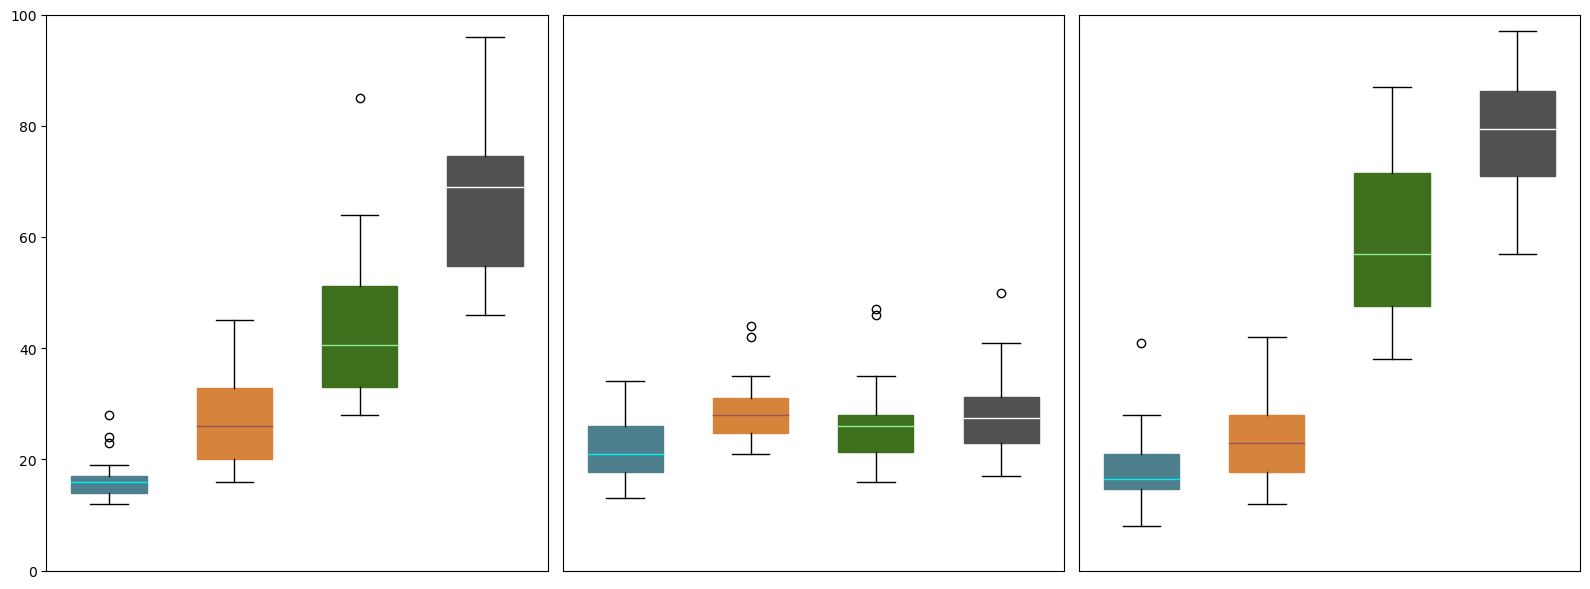

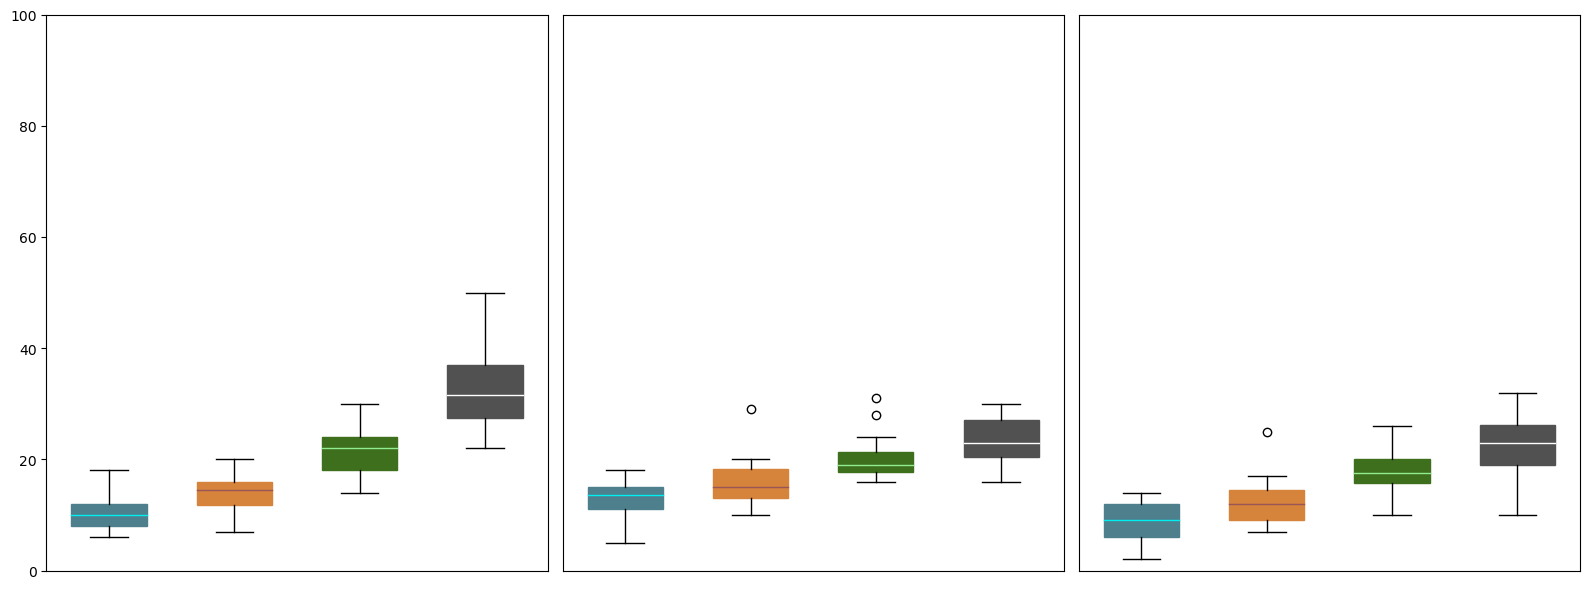

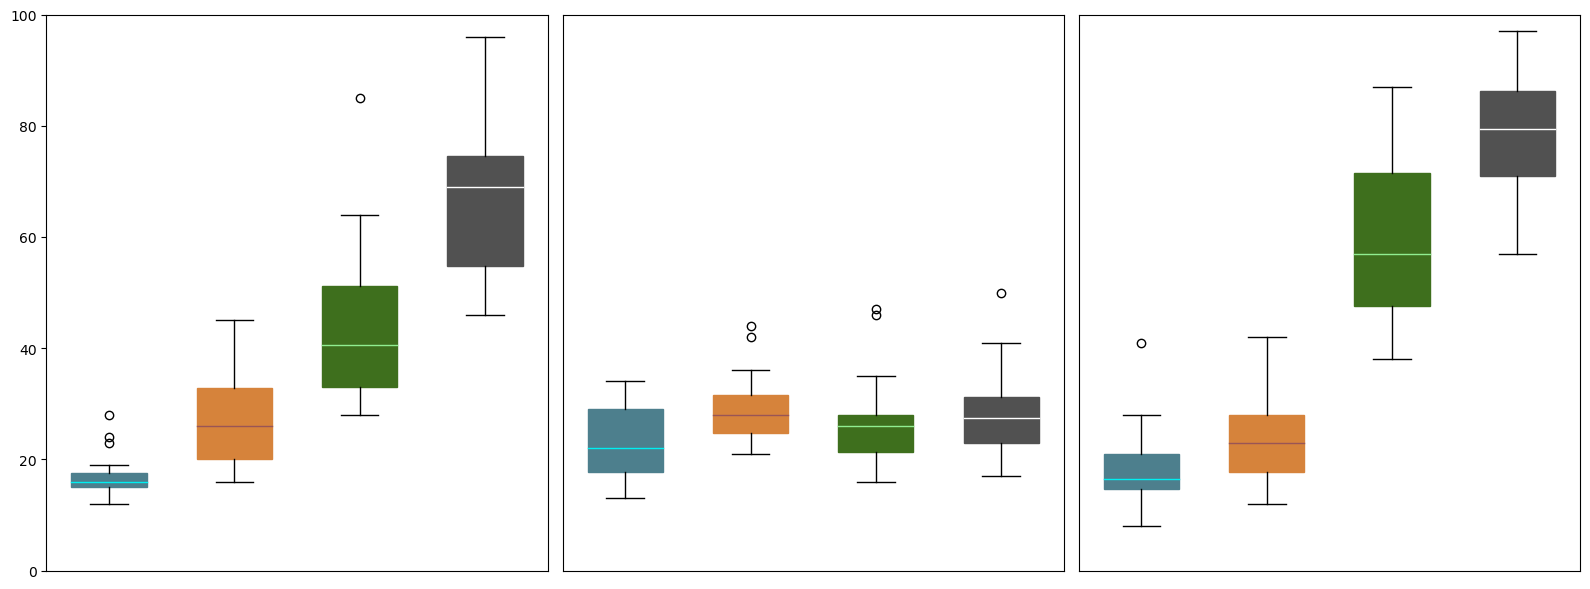

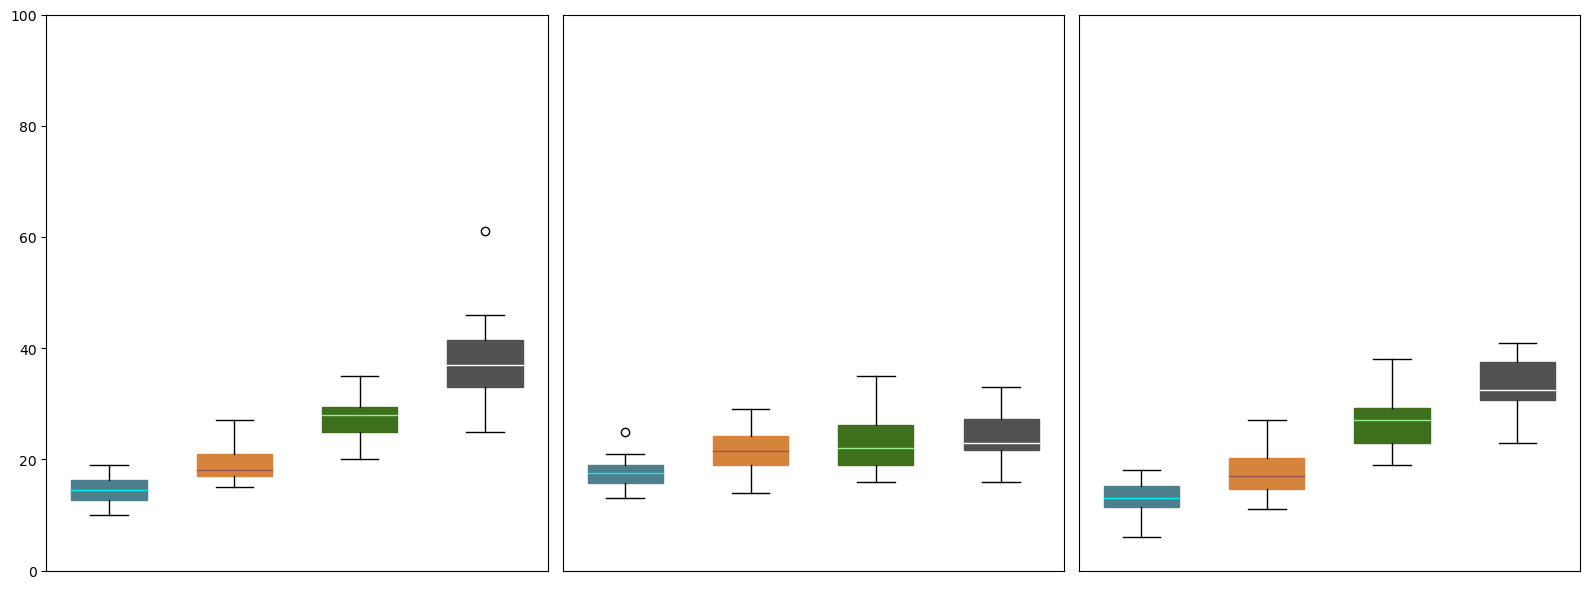

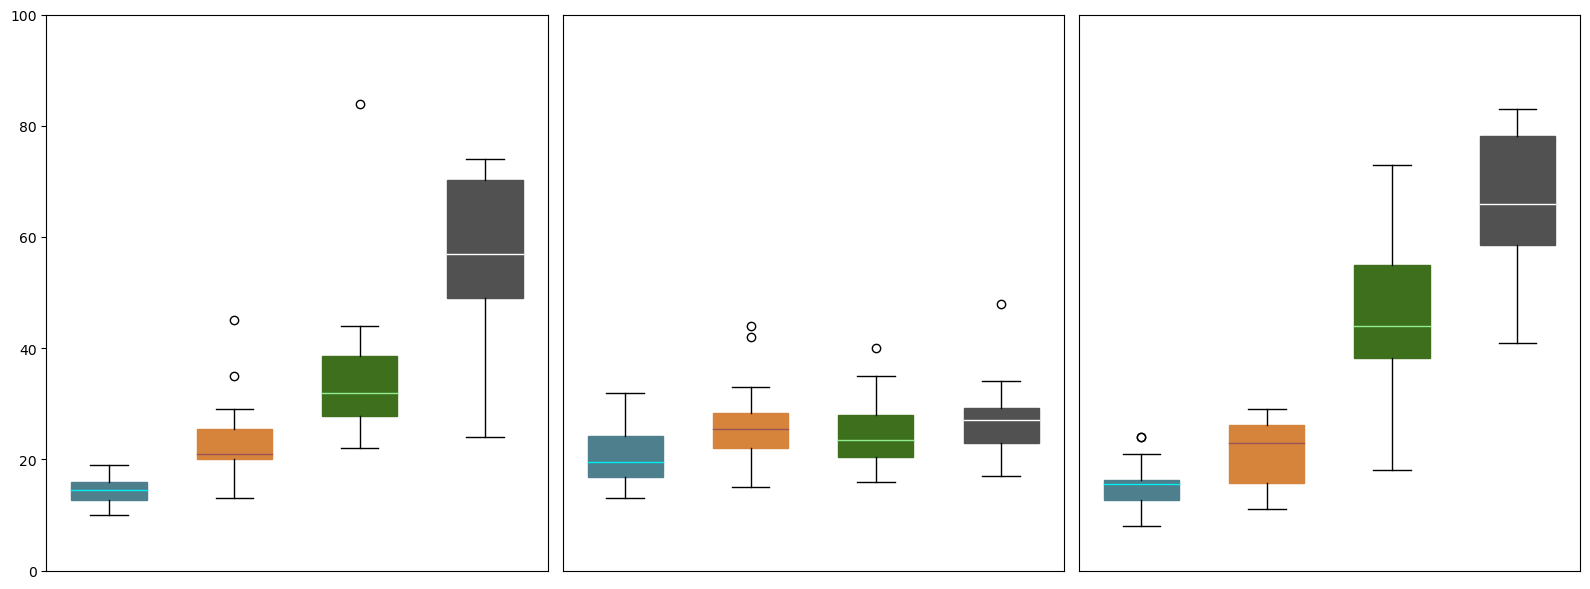

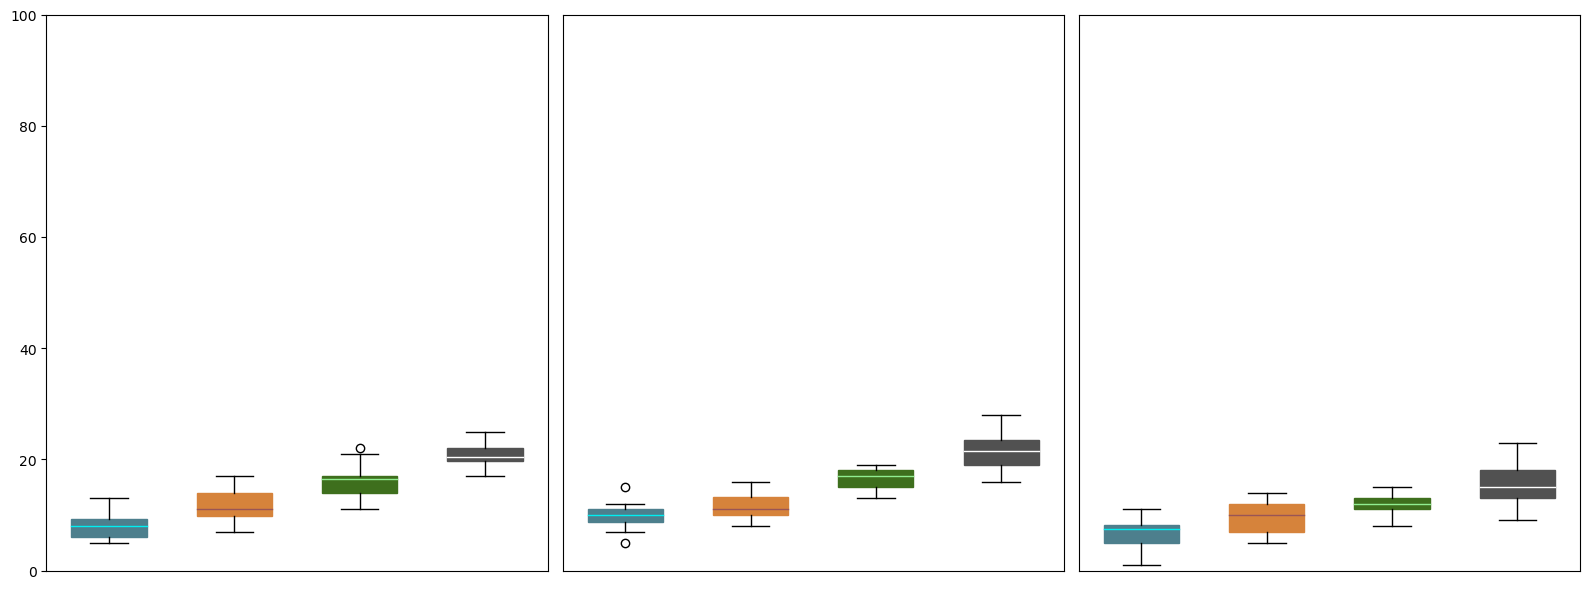

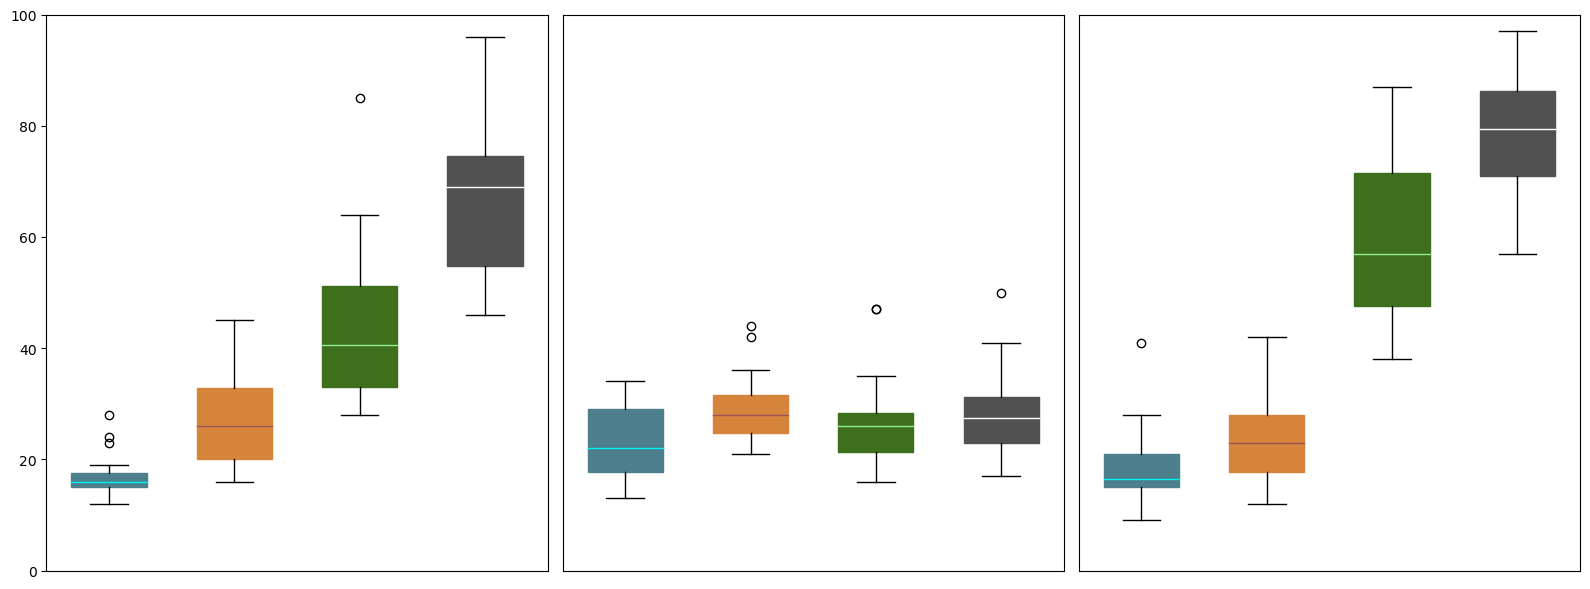

In [85]:
for met_name in metric_names +['entire_traj']:
  search_len_single = [[], [], [], []]
  search_len_qmin = [[], [], [], []]
  search_len_qplus = [[], [], [], []]
  if met_name != 'entire_traj':
    met_single = metrics['single_Q'][met_name]
    met_qmin = metrics['two_Q'][met_name]
    met_qplus = metrics['two_Q'][met_name]
  
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            search_len_single[i].append(compute_search_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", 501, count_from=0 ) ) 
            search_len_qmin[i].append(compute_search_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 503, count_from=0 ) )
            search_len_qplus[i].append(compute_search_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=503 ) )
          else:
            search_len_single[i].append(compute_search_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met_single[i][j]), count_from=0) ) 
            search_len_qmin[i].append(compute_search_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qmin[i][j]), count_from=0 ) )  
            search_len_qplus[i].append(compute_search_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qplus[i][j]) + 502, count_from=503 ) )


  fig, axes = plt.subplots(1, 3, figsize=(16, 6))
  axes = axes.flatten()
#  fig.suptitle(f"Search Length {met_name} ", fontsize=20)
  for ax_idx, ax, values, title in zip(range(len(axes)), axes, [search_len_single, search_len_qmin, search_len_qplus], ['1Q', '$Q^-$', '$Q^+$']):
#    ax.set_title(f"{title}")
    b = ax.boxplot(values, widths=0.6, patch_artist=True)
    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(box_colors[j])
        b['medians'][j].set_color(median_colors[j])
#    ax.set_xticklabels(data_labels, fontsize=14)
    if ax_idx > 0:
      ax.set_yticks([])
    ax.set_xticks([])
    ax.set_ylim([-0.1, 100])
  fig.tight_layout()
  fig.savefig(f"{out_path}/2vs1_characterization/search_length_{met_name}_2qvs1q_opt_tau.pdf", bbox_inches='tight')
#  plt.close(fig)


### Cast-Width

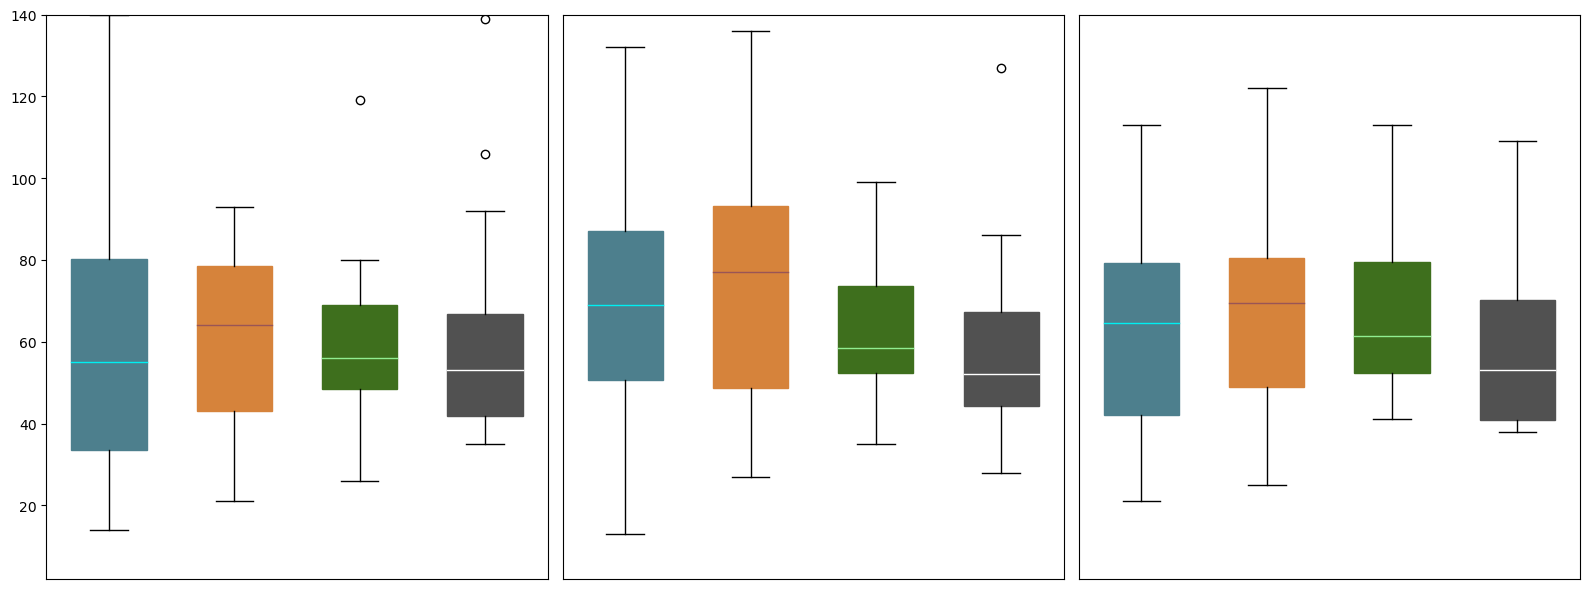

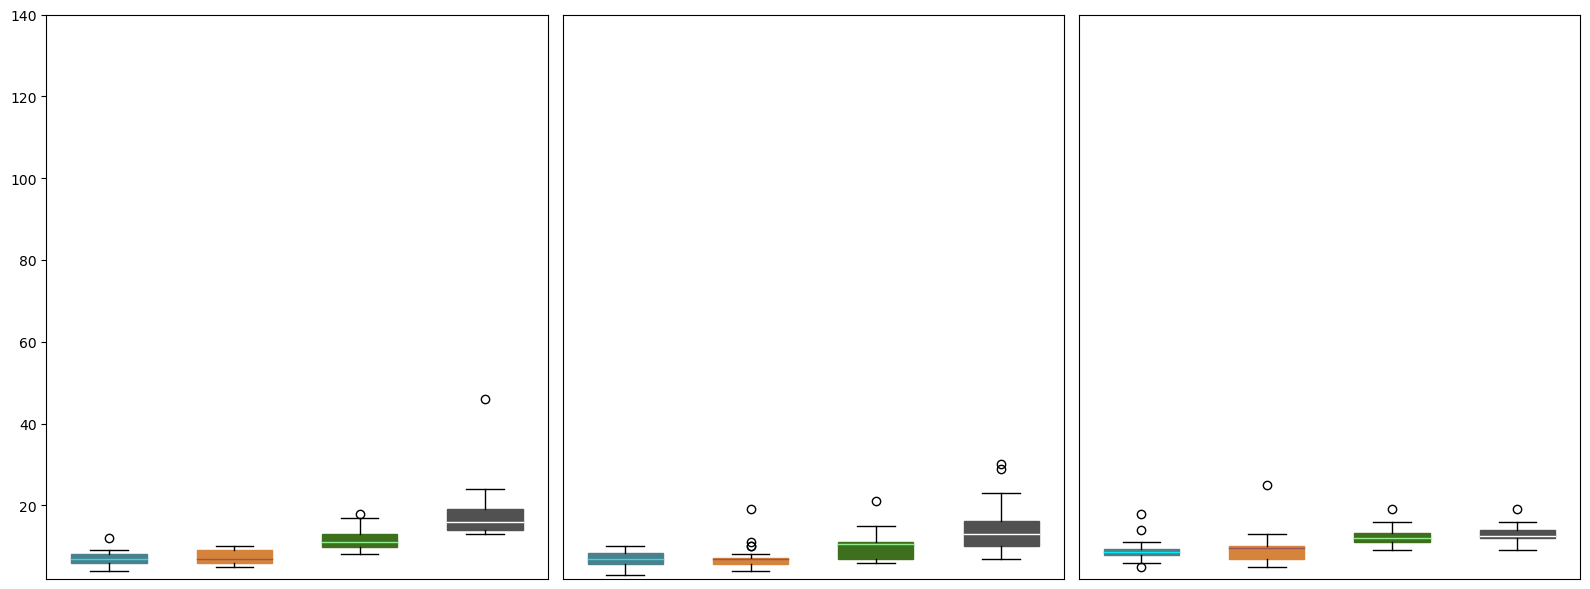

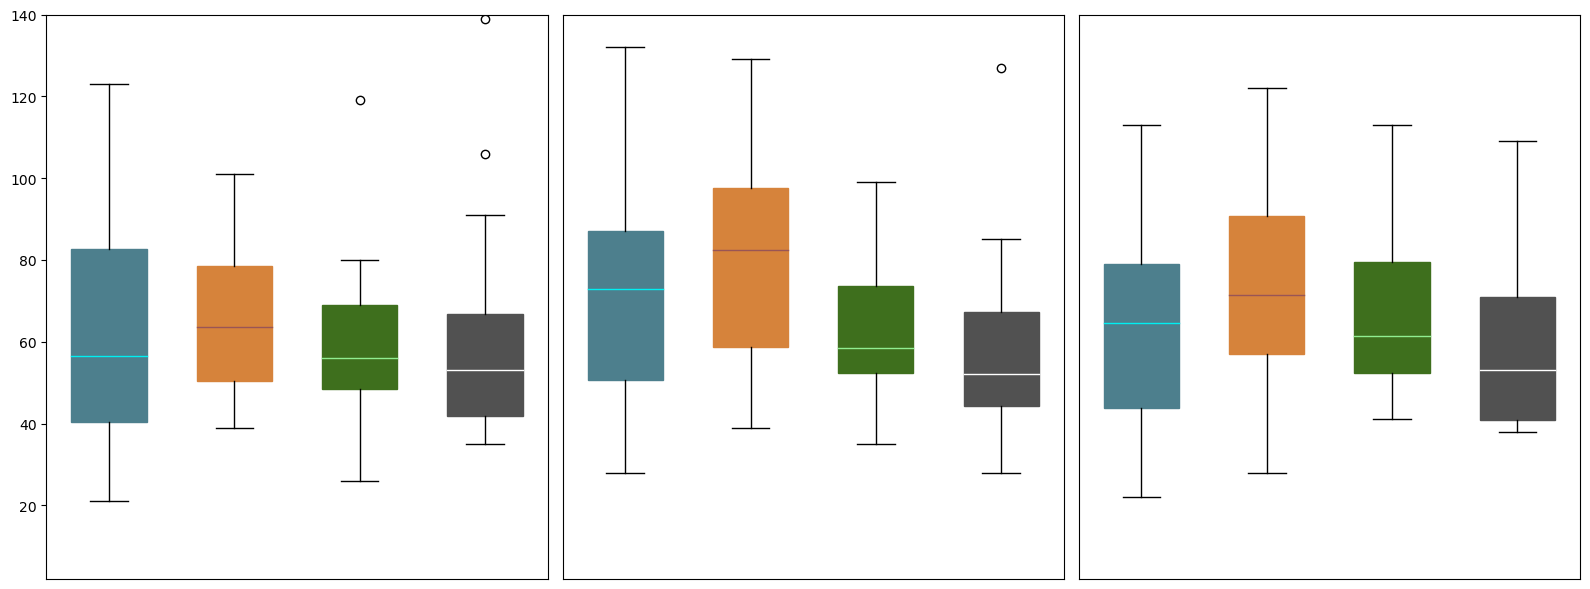

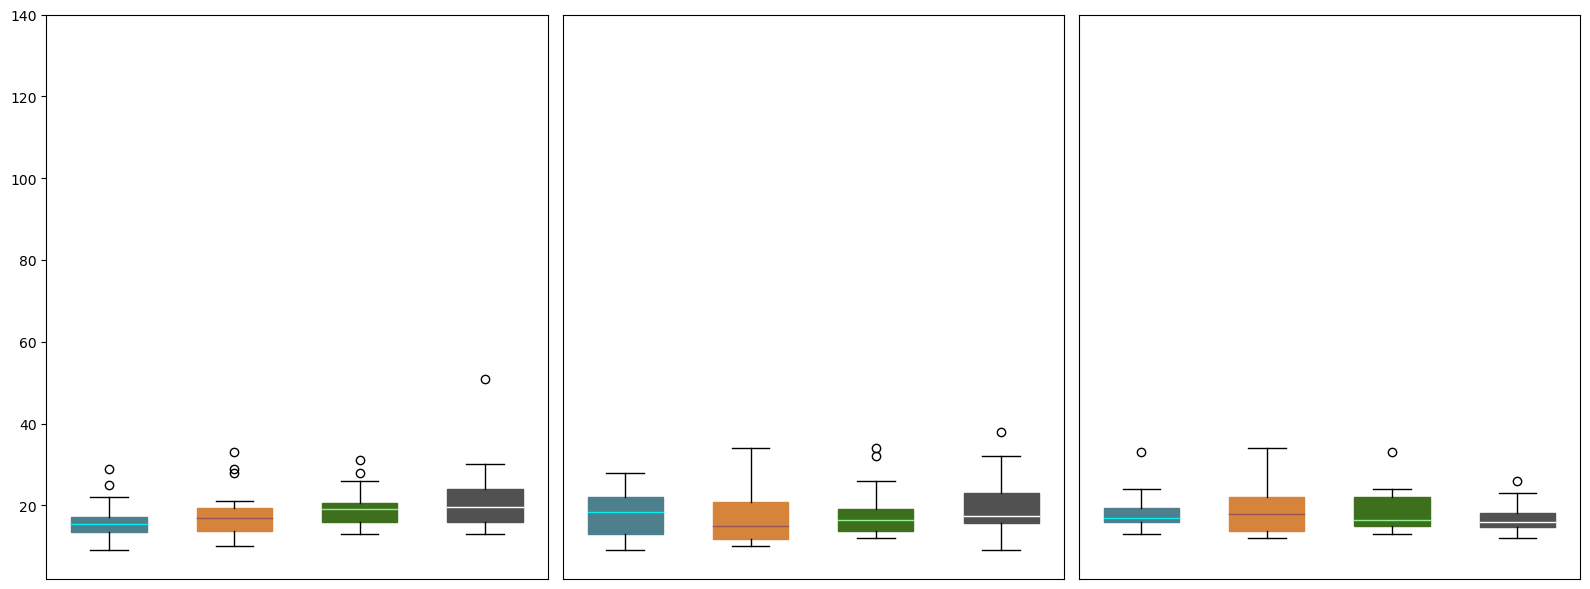

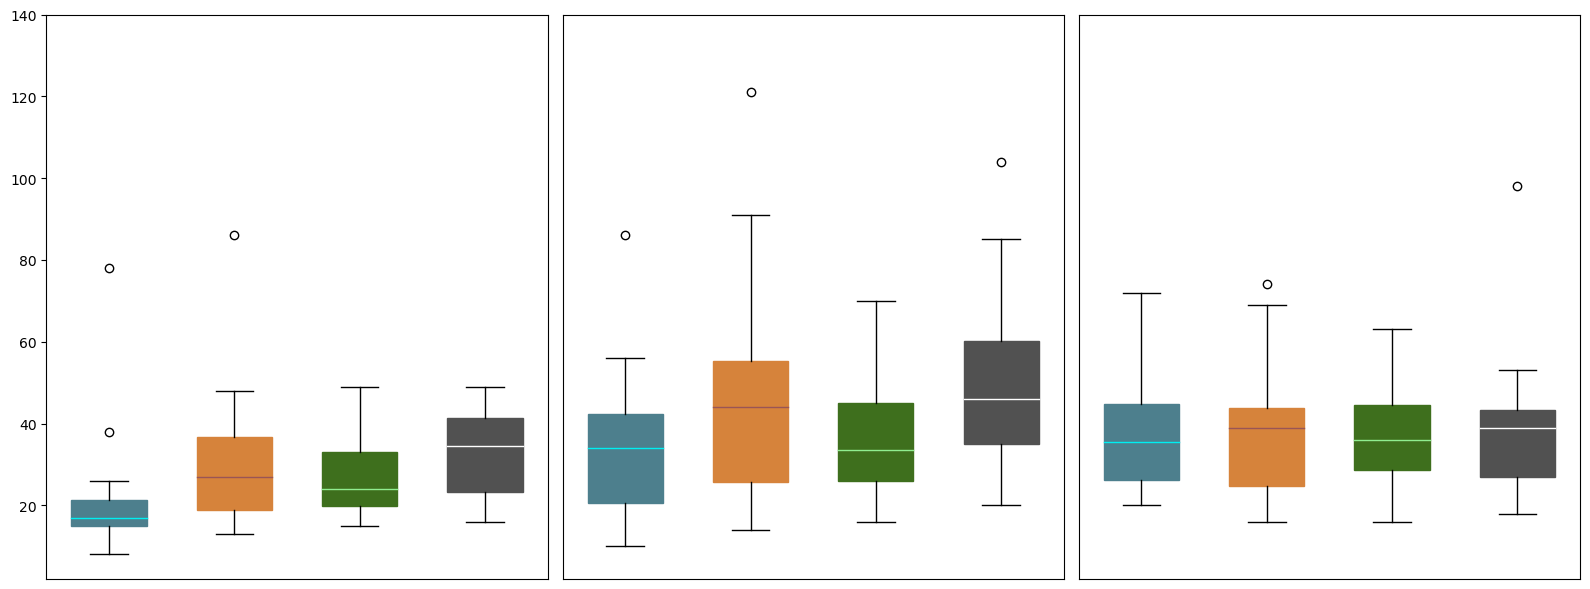

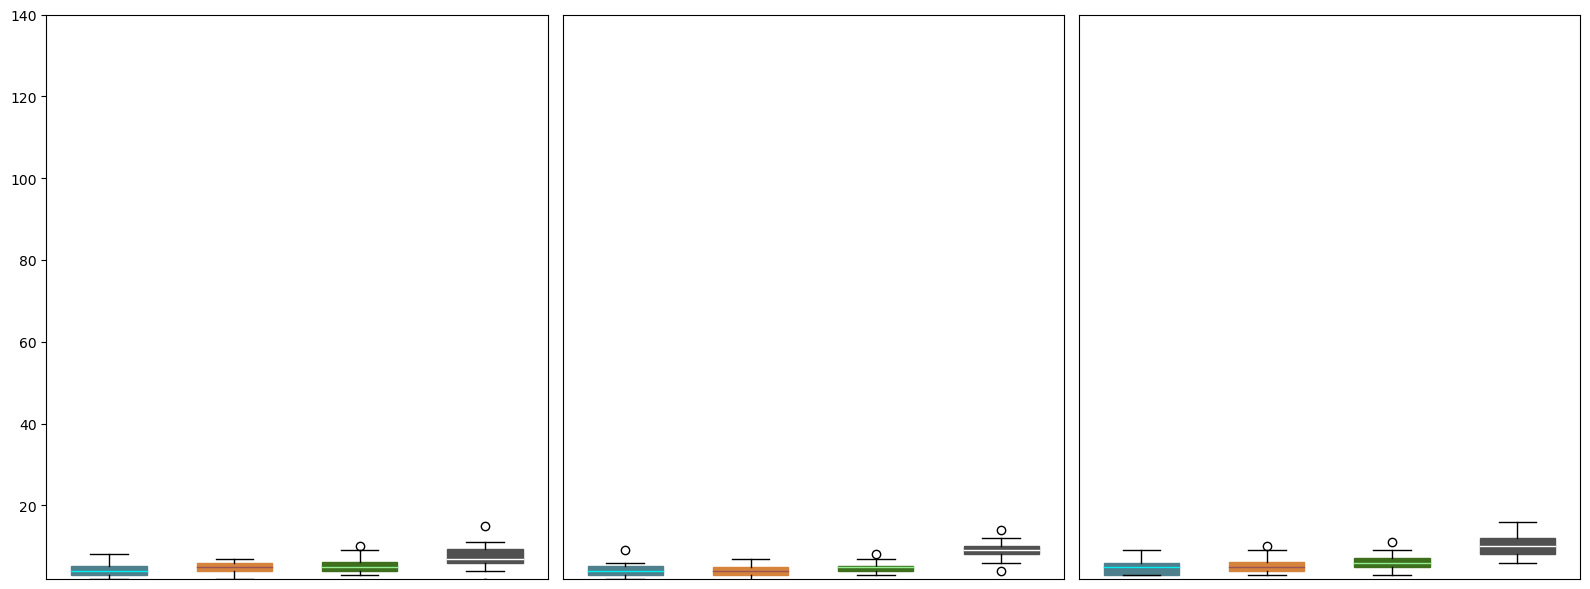

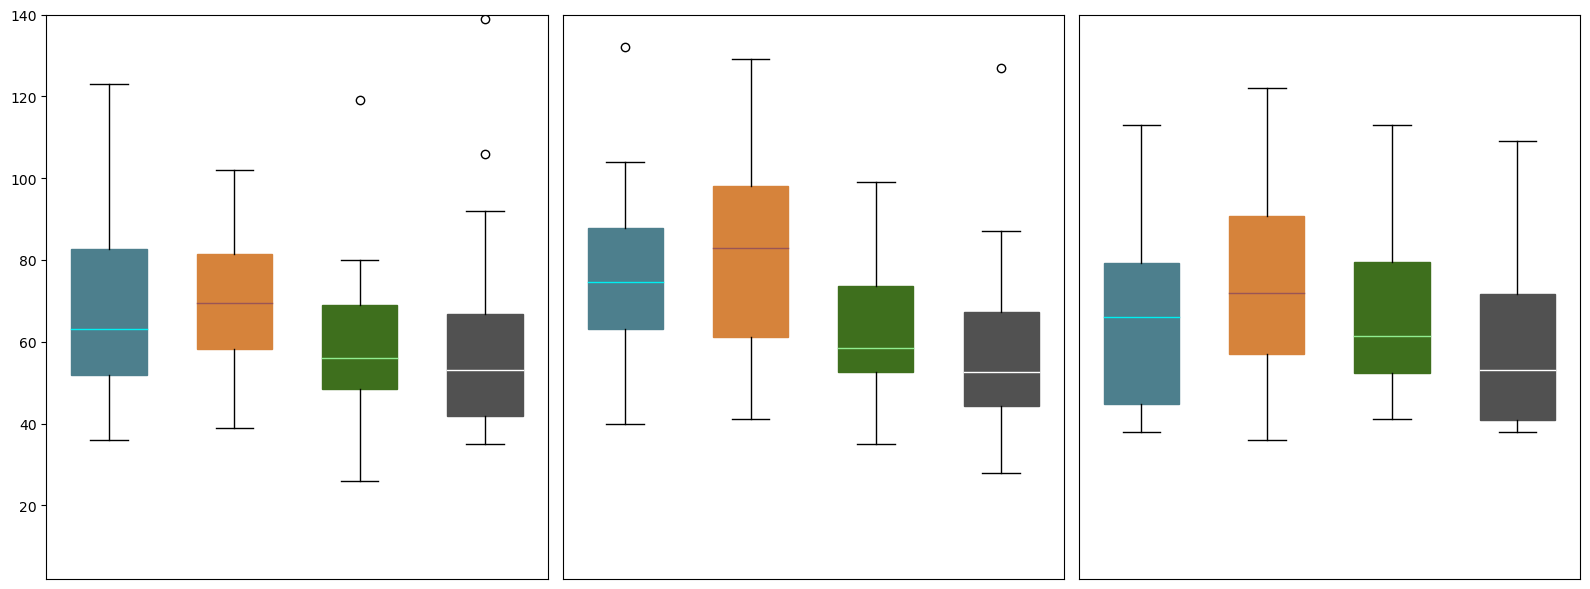

In [87]:
for met_name in metric_names +['entire_traj']:
  cast_width_single = [[], [], [], []]
  cast_width_qmin = [[], [], [], []]
  cast_width_qplus = [[], [], [], []]
  if met_name != 'entire_traj':
    met_single = metrics['single_Q'][met_name]
    met_qmin = metrics['two_Q'][met_name]
    met_qplus = metrics['two_Q'][met_name]
  
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            cast_width_single[i].append(compute_cast_width(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", 501, count_from=0 ) ) 
            cast_width_qmin[i].append(compute_cast_width(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 503, count_from=0 ) )
            cast_width_qplus[i].append(compute_cast_width(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=503 ) )
          else:
            cast_width_single[i].append(compute_cast_width(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met_single[i][j]), count_from=0) ) 
            cast_width_qmin[i].append(compute_cast_width(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qmin[i][j]), count_from=0 ) )  
            cast_width_qplus[i].append(compute_cast_width(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qplus[i][j]) + 502, count_from=503 ) )


  fig, axes = plt.subplots(1, 3, figsize=(16, 6))
  axes = axes.flatten()
#  fig.suptitle(f"Cast Width {met_name}", fontsize=20)
  for ax_idx, ax, values, title in zip(range(len(axes)), axes, [cast_width_single, cast_width_qmin, cast_width_qplus], ['Single Q', '$Q^-$', '$Q^+$']):
#    ax.set_title(f"{title}")
    b = ax.boxplot(values, widths=0.6, patch_artist=True)
    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(box_colors[j])
        b['medians'][j].set_color(median_colors[j])
    if ax_idx > 0:
      ax.set_yticks([])
    ax.set_xticks([])
    ax.set_ylim([2, 140])
#    ax.set_xticklabels(data_labels, fontsize=14)
  fig.tight_layout()
  fig.savefig(f"{out_path}/2vs1_characterization/cast_width_{met_name}_2qvs1q_opt_tau.pdf", bbox_inches='tight')
#  plt.close(fig)


### Backtracking Length

In [ ]:
for met_name in metric_names +['entire_traj']:
  bck_len_single = [[], [], [], []]
  bck_len_qmin = [[], [], [], []]
  bck_len_qplus = [[], [], [], []]
  if met_name != 'entire_traj':
    met_single = metrics['single_Q'][met_name]
    met_qmin = metrics['two_Q'][met_name]
    met_qplus = metrics['two_Q'][met_name]
  
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          # if met_name == 'entire_traj':
          #   bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 1003, count_from=502 ) ) 
          # else:
          #   bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502) ) 

          if met_name == 'entire_traj':
            bck_len_single[i].append(compute_backtracking_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", 501, count_from=0 ) ) 
            bck_len_qmin[i].append(compute_backtracking_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 503, count_from=0 ) )
            bck_len_qplus[i].append(compute_backtracking_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=503 ) )
          else:
            bck_len_single[i].append(compute_backtracking_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met_single[i][j]), count_from=0) ) 
            bck_len_qmin[i].append(compute_backtracking_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qmin[i][j]), count_from=0 ) )  
            bck_len_qplus[i].append(compute_backtracking_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qplus[i][j]) + 502, count_from=503 ) )


  fig, axes = plt.subplots(1, 3, figsize=(16, 6))
  axes = axes.flatten()
#  fig.suptitle(f"Backtracking Length {met_name}", fontsize=20)
  for ax_idx, ax, values, title in zip(range(len(axes)),axes, [bck_len_single, bck_len_qmin, bck_len_qplus], ['Single Q', '$Q^-$', '$Q^+$']):
#    ax.set_title(f"{title}")
    b = ax.boxplot(values, widths=0.6, patch_artist=True)
    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(box_colors[j])
        b['medians'][j].set_color(median_colors[j])
    ax.set_xticklabels(data_labels, fontsize=14)
    ax.set_ylim([-5.0, 105])
    if ax_idx > 0:
      ax.set_yticks([])
    ax.set_xticks([])
  fig.tight_layout()

  fig.savefig(f"{out_path}/2vs1_characterization/backtracking_length_{met_name}_2qvs1q_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)


# 2Q heuristic

In [ ]:
agent = TwoQAgent(horizon=500)
out_path = './paper_plots/two_single_Q'
taus = [3, 5, 10, 25]#, 50, 100, 200, 2000] #[3, 5, 10, 25, 50, 100, 200]

In [ ]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_single_Q"

#/storage/rando/pynav_results_new/two_single_Q/agent_1259/tau_5/test/dense/


In [ ]:


for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  for i in range(len(settings)):
      setting = settings[i] 
      c_rewards = []
      speeds = []
      convergence = []

      for seed in agent_seeds:

          with open(f"{base_dir}/two_single_Q/agent_{seed}/tau_{tau}/test/{setting}/test_summary.log", 'r') as f:
              line = f.readline().split(',')
              c_rewards.append(float(line[0]))
              speeds.append(float(line[2]))
              convergence.append(float(line[4]))
      creward_data.append(c_rewards)
      speed_data.append(speeds)
      conv_data.append(convergence)
      

  # num_settings = 4
  # num_subgroups = 4
  # positions = []
  # group_width = 1.0
  # subgroup_spacing = 0.75 

  # for i in range(num_settings):
  #     base = i * group_width * num_subgroups  
  #     positions += [base + j * subgroup_spacing for j in range(num_subgroups)]

  positions = range(len(settings))
  fig, ax = plt.subplots(1, 3, figsize=(22, 6))
  b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
  b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
  b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


  #print(len(b1), b1)

  for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[i % 4])
      b1['medians'][i].set_color(median_colors[i % 4])
      b2['boxes'][i].set_color(box_colors[i % 4])
      b2['medians'][i].set_color(median_colors[i % 4])
      b3['boxes'][i].set_color(box_colors[i % 4])
      b3['medians'][i].set_color(median_colors[i % 4])

#  xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
  for i in range(len(ax)):
    ax[i].set_xticks(ticks=positions, labels=data_labels, fontsize=14)

  ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
  ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
  ax[2].set_title("Convergence Ratio", fontsize=18)

  ax[0].set_ylim([0.0, 1.01])
  ax[1].set_ylim([0.0, 1.01])
  ax[2].set_ylim([0.0, 1.01])
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"{out_path}/performance/performance_tau_{tau}.pdf", bbox_inches='tight')
  plt.close(fig)


FileNotFoundError: [Errno 2] No such file or directory: '/storage/rando/pynav_results_new/two_single_Q/two_single_Q/agent_1259/tau_3/test/dense/test_summary.log'

# heat-map of Q-usage using different $\tau$

In [62]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_single_Q"

for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  fig, axes = plt.subplots(2,2, figsize=(12, 6))
  axes = axes.flatten()
  for i in range(len(settings)):
      ax = axes[i]
      setting = settings[i] 
      Q_v = {}
      Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
      for seed in agent_seeds:

          with open(f"{base_dir}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_map.log", 'r') as f:
              for line in f.readlines():
                  splitted = line.split(',')
                  
                  y_pos = int(splitted[0])
                  x_pos = int(splitted[1])
                  if y_pos not in Q_v:
                      Q_v[y_pos] = {}
                  if x_pos not in Q_v[y_pos]:
                      Q_v[y_pos][x_pos] = []
                  Q_v[y_pos][x_pos].append(float(splitted[2]))
      for y_pos, xmap in Q_v.items():
          for x_pos, vals in xmap.items():
              Q_map[y_pos, x_pos] = np.mean(vals)

      new_data = data_environments[noise_thresholds[i]]
      ax.set_title(f"Trained and Test on {setting}")
      im =ax.imshow(Q_map, origin='lower', vmin=0.0, vmax=1.0)
  fig.tight_layout()
  fig.colorbar(im, ax=axes.ravel().tolist(), location='bottom')    
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"./paper_plots/two_single_Q/performance/two_q_usage_{tau}.pdf", bbox_inches='tight')
  plt.close(fig)

/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 2


/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 5


/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 10


... (2 outputs left out)

/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 50


/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_3907102/1585250096.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 100


In [63]:
Q_usage = []
Q_usage_std = []
taus = [2, 5, 10, 25, 50, 100]

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_single_Q"


Q_settings = []
for setting in settings:
  Qmin_usage, Qplus_usage = [], []
  Q = []
  Q_taus = []
  for tau in taus:
    minus_usage, plus_usage = [], []
    Q_agents = []
    for seed in agent_seeds:
      with open(f"{base_dir}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_list.log", 'r') as f:
        lines = f.readlines()
        for line in lines:
          splitted = line.split(',')
          # if int(splitted[0]) == 0:
          #   continue
          minus_usage.append(float(splitted[1]))
          plus_usage.append(float(splitted[2]))
      Q_m, Q_p = np.sum(minus_usage), np.sum(plus_usage)
      Q_agents.append(Q_m / Q_p)
    # Q_agents contains Q_m / Q_p for each agent at given tau for the given setting
    Q_taus.append(Q_agents)
  Q_settings.append(Q_taus)
  #   minus_usage = np.array(minus_usage)
  #     print(minus_usage, plus_usage)
  #     print("-")
  #   Qmin_usage.append(np.sum(minus_usage))
  #   Qplus_usage.append(np.sum(plus_usage))
    
  # Qmin_usage = np.array(Qmin_usage)
  # Qplus_usage = np.array(Qplus_usage)
  # Q_usage.append(Qmin_usage / Qplus_usage)
        

In [64]:
Q_settings = np.array(Q_settings)

In [65]:
Q_settings

array([[[ 0.60556169,  0.54617927,  0.58517767,  0.60081179,
          0.60028826,  0.6105203 ,  0.64781526,  0.61172243,
          0.59757224,  0.61688192,  0.60758604,  0.60069611,
          0.58131545,  0.57896971,  0.57660226,  0.55990739,
          0.56756621,  0.56567607,  0.56974526,  0.57547036],
        [ 1.24851465,  1.08076779,  1.16249011,  1.16463844,
          1.16959223,  1.16979955,  1.23599116,  1.17213037,
          1.12926197,  1.16185447,  1.13957409,  1.12150455,
          1.08874167,  1.07481349,  1.05981356,  1.02869459,
          1.04350511,  1.03769409,  1.04105956,  1.05292163],
        [ 2.98728817,  2.22681081,  2.32800341,  2.3938111 ,
          2.44183989,  2.43211974,  2.53554452,  2.43999329,
          2.33224015,  2.34148665,  2.28403144,  2.22243567,
          2.18586738,  2.13334376,  2.11629341,  2.05304823,
          2.07873132,  2.07447222,  2.08288707,  2.10356181],
        [ 5.738501  ,  3.5681271 ,  4.2295855 ,  4.98642713,
          5.57371817,

In [66]:
len(Q_settings[i]), len(taus)

(6, 6)

# 2Q heuristic: relative Q usage using different $\tau$

6 6
6 6
6 6
6 6


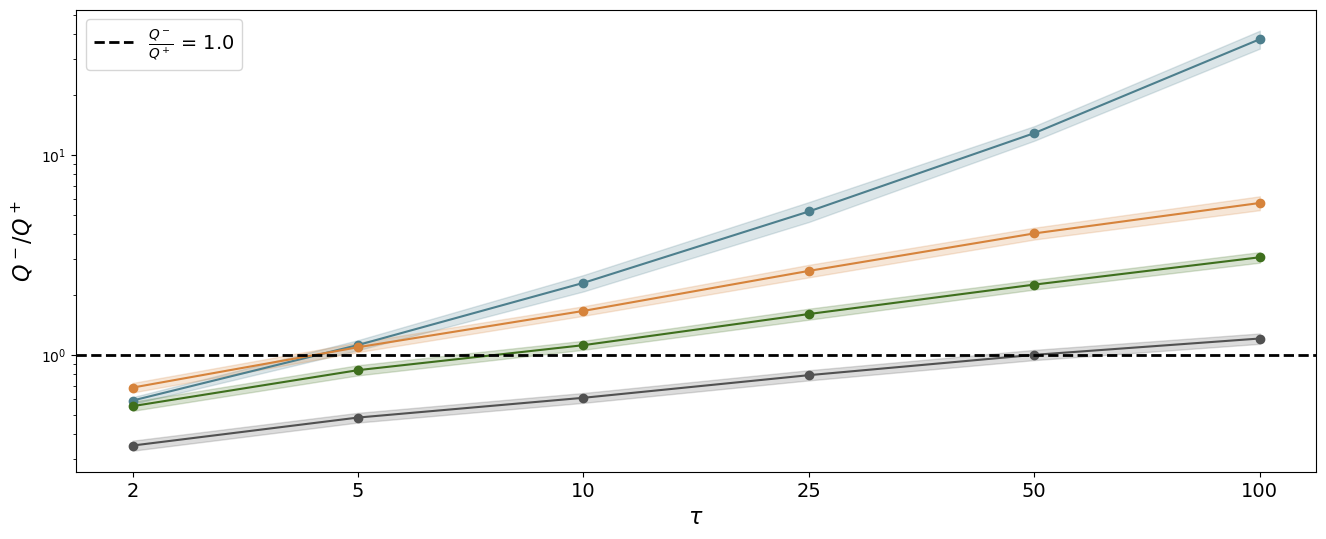

In [68]:


fig, ax = plt.subplots(1, 1, figsize=(16, 6))

for i in range(len(settings)):
  print(len(Q_settings[i]), len(taus))
#  ax.boxplot(Q_settings[i], positions=range(len(taus)), patch_artist=True, showfliers=False, medianprops={'color': median_colors[i]})
  mu, std = np.array([np.mean(Q_settings[i][j]) for j in range(len(taus)) ]), np.array([np.std(Q_settings[i][j]) for j in range(len(taus)) ])
  ax.plot(mu, 'o-', color=box_colors[i], rasterized=True)
  ax.fill_between(range(len(taus)), mu - std, mu + std, color=box_colors[i], alpha=0.2, rasterized=True)
#  ax.plot([np.std(Q_settings[i][j]) for j in range(len(taus)) ], 'o-', color=box_colors[i], rasterized=True)

ax.set_yscale('log')
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='$\\frac{Q^-}{Q^+}$ = 1.0', lw=2, rasterized=True)
ax.set_xticks(range(len(taus)), taus, fontsize=14)
ax.set_xlabel("$\\tau$", fontsize=16)
ax.set_ylabel("$Q^-$/$Q^+$", fontsize=16)

ax.legend(fontsize=14)

# 2Q heur: Performance with different $\tau$

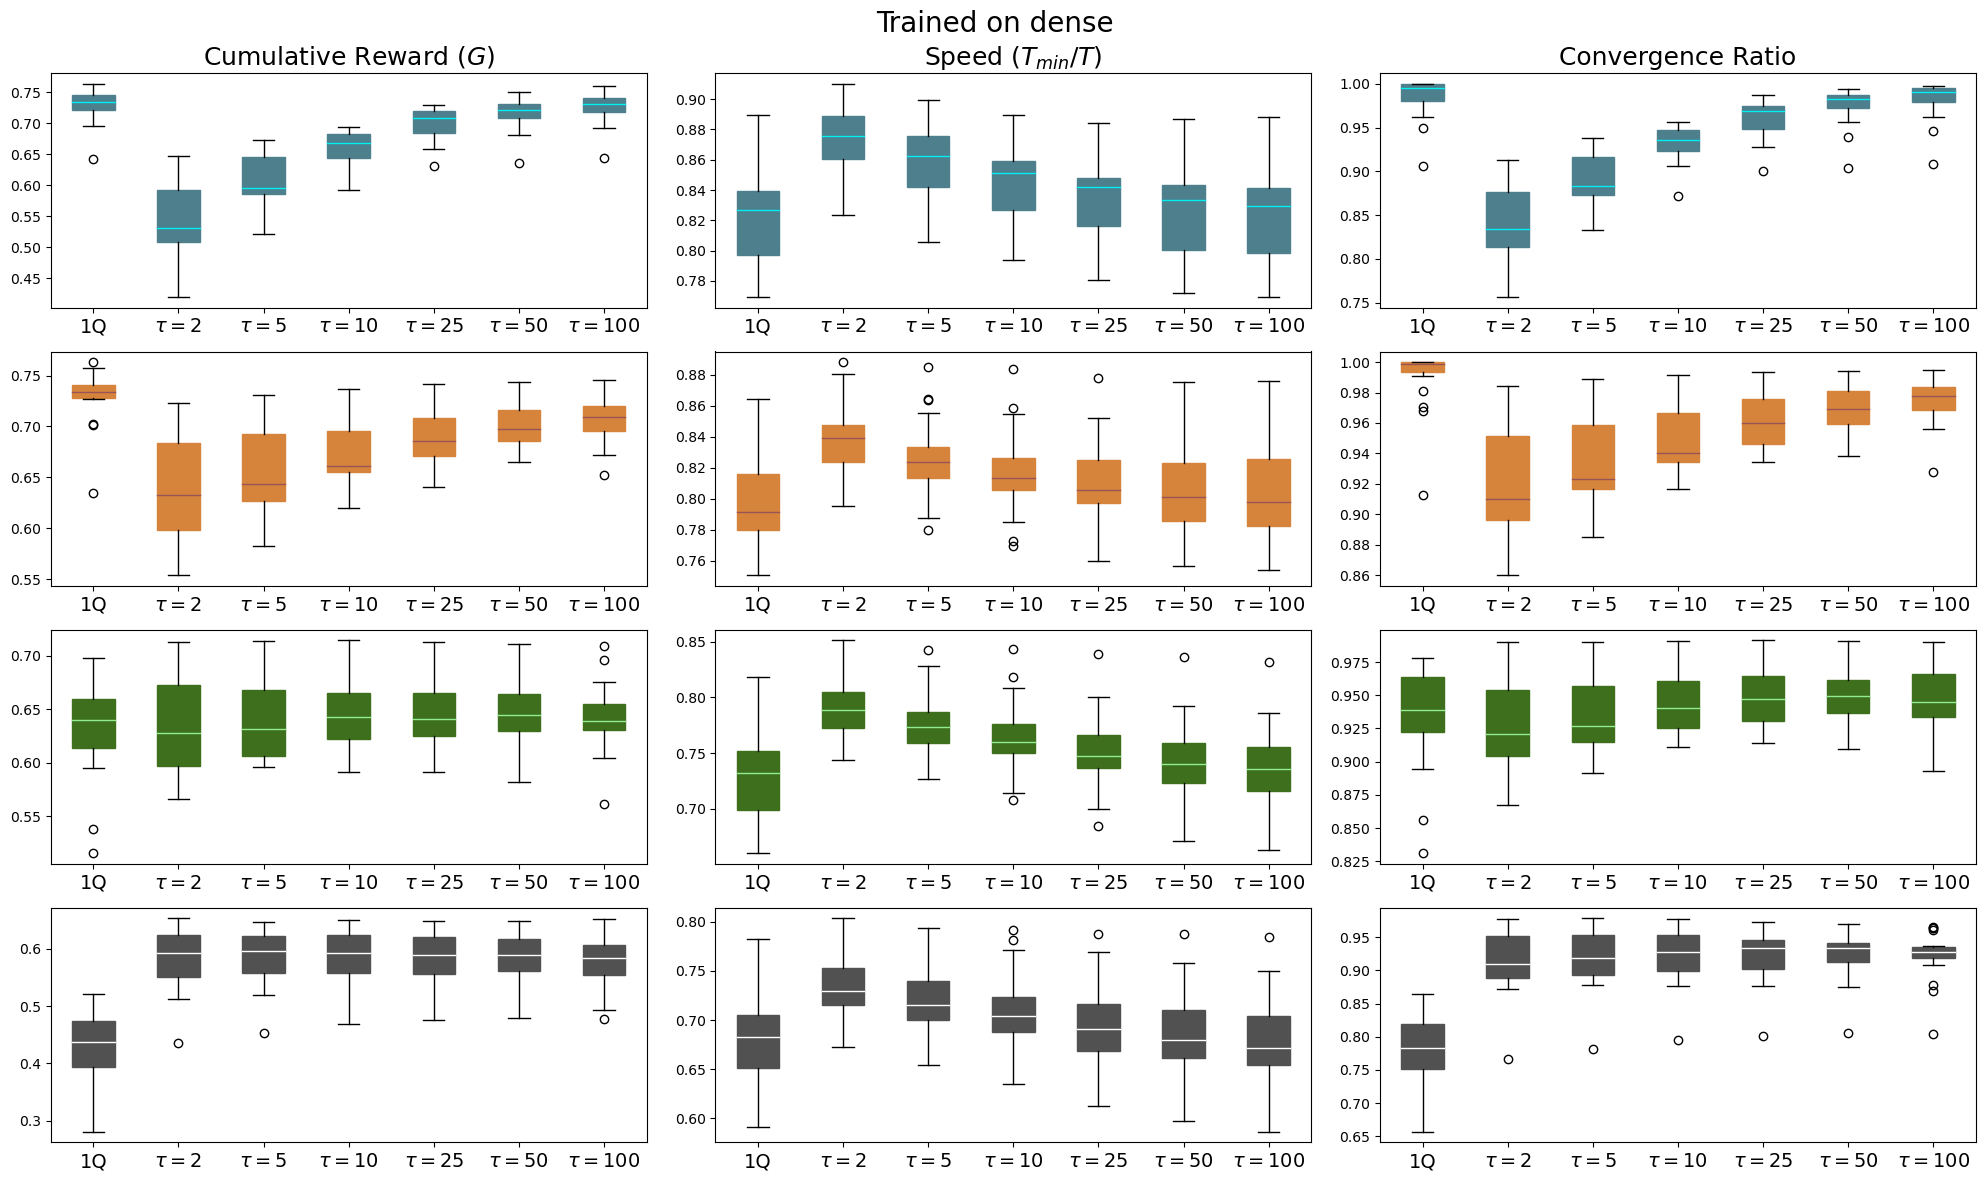

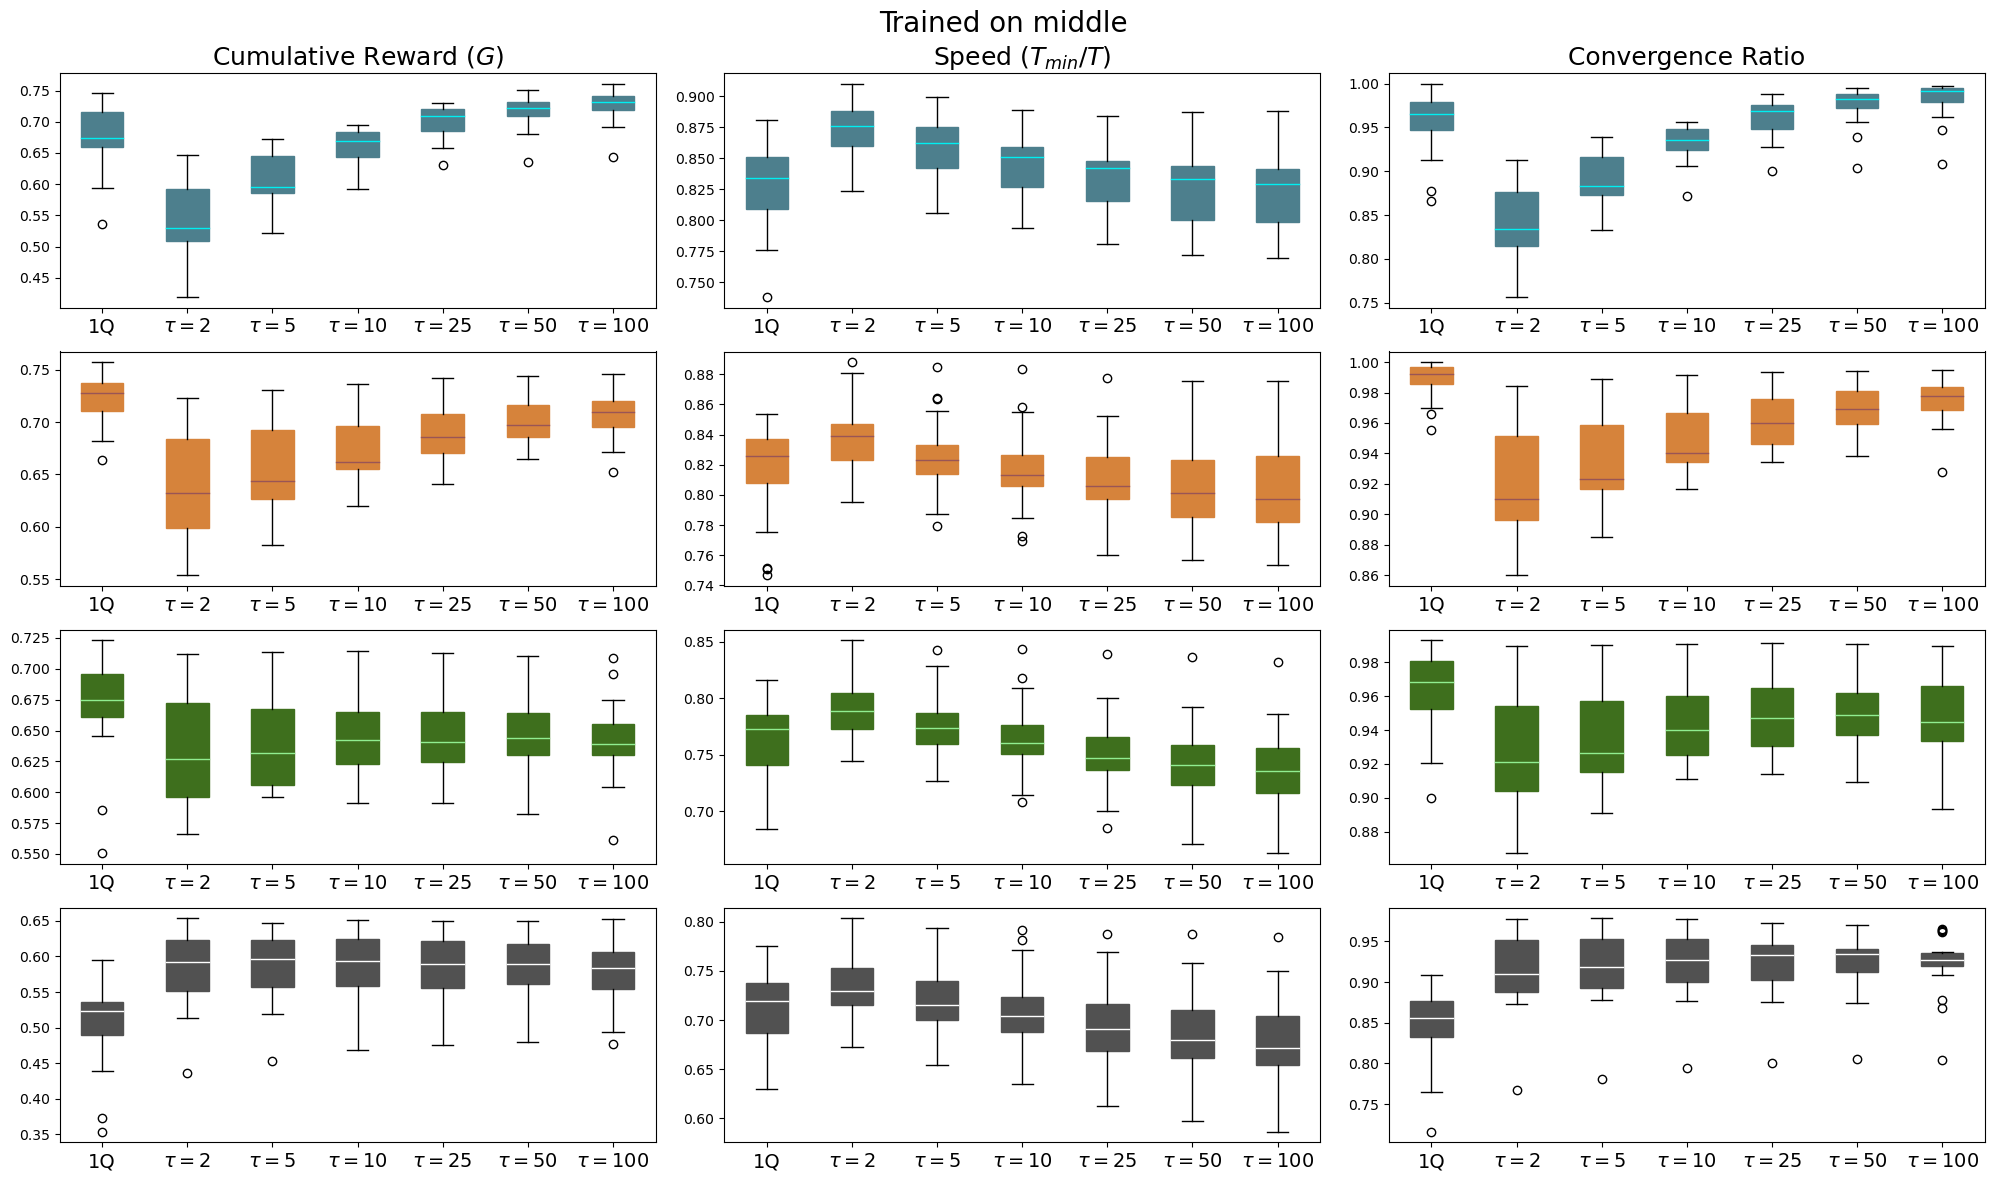

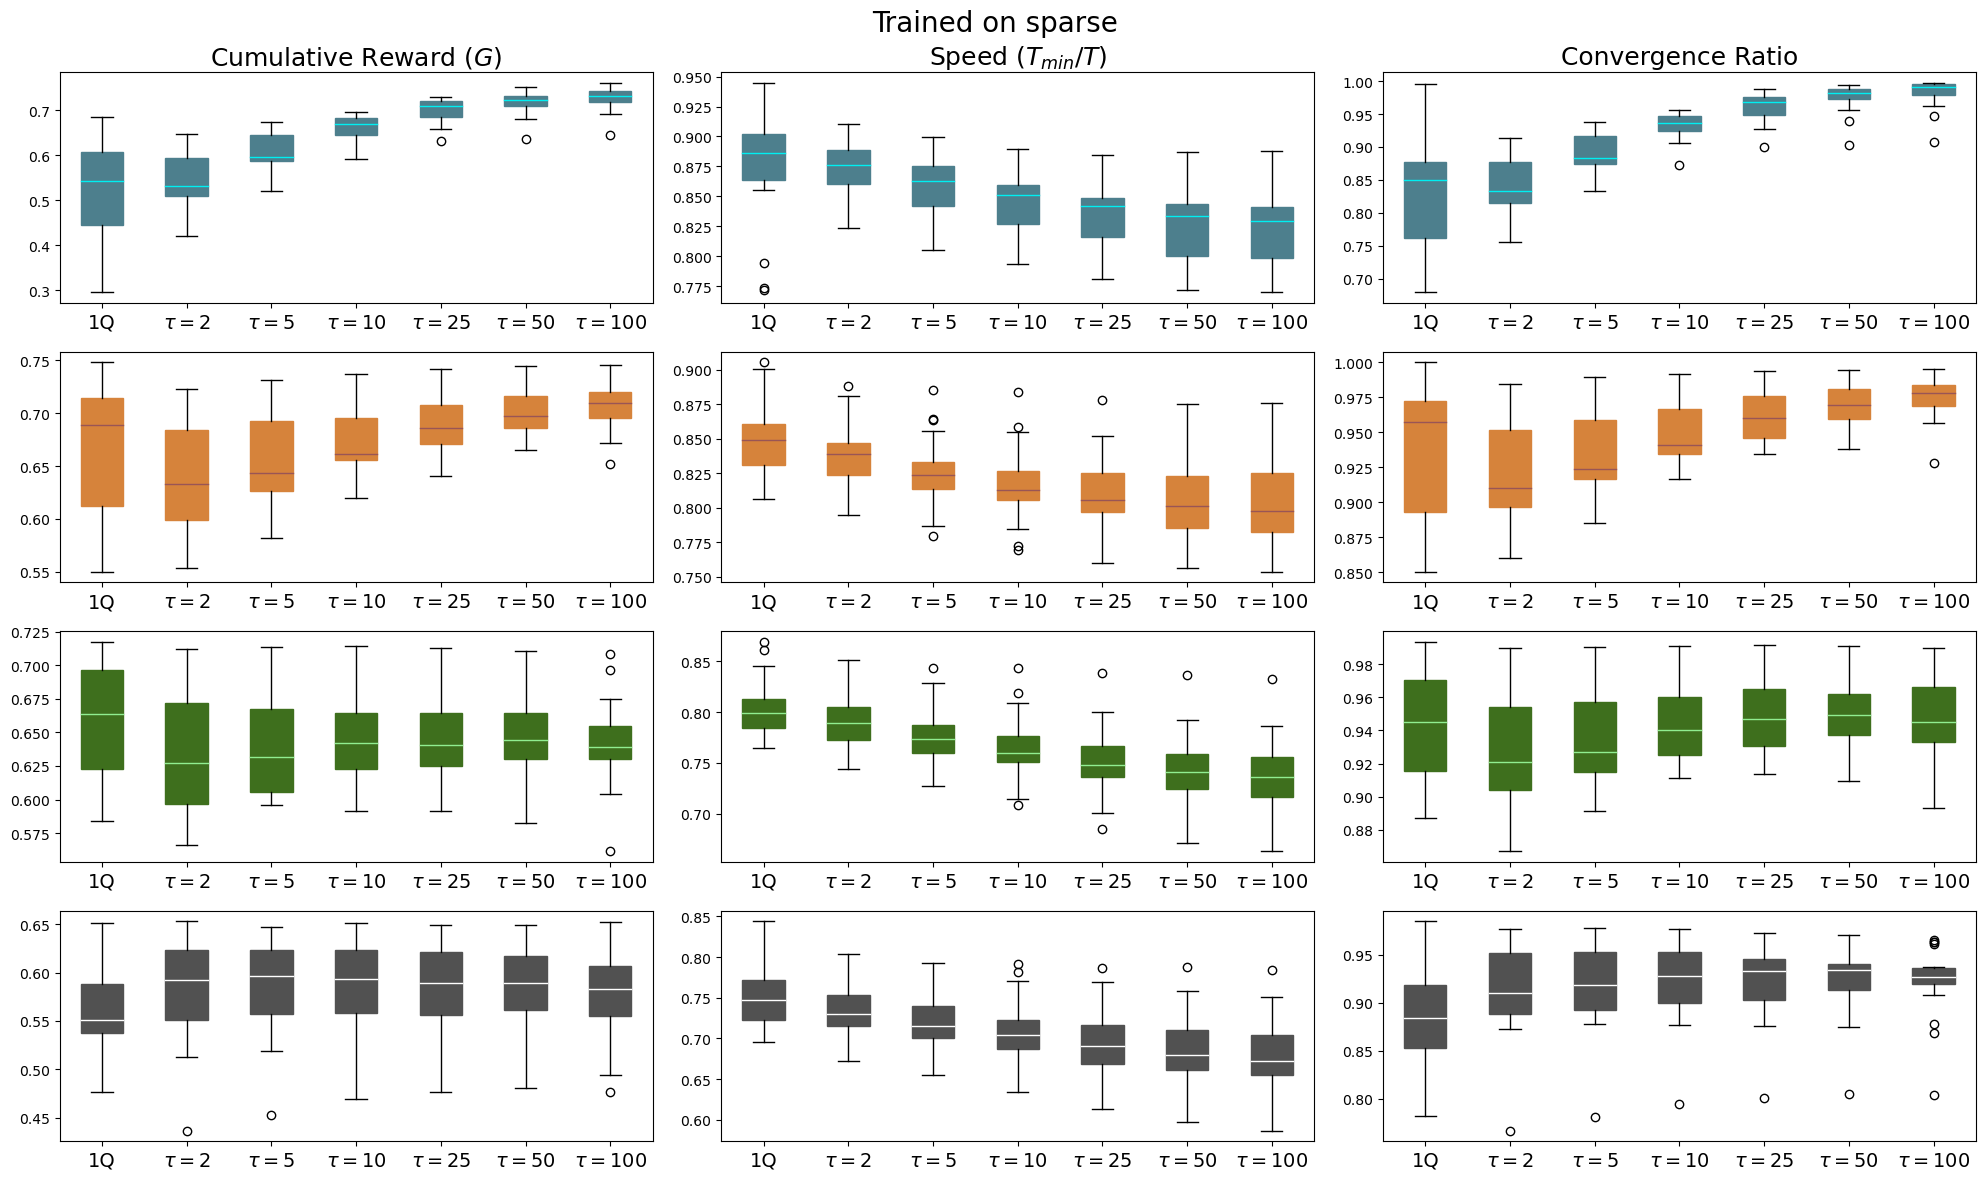

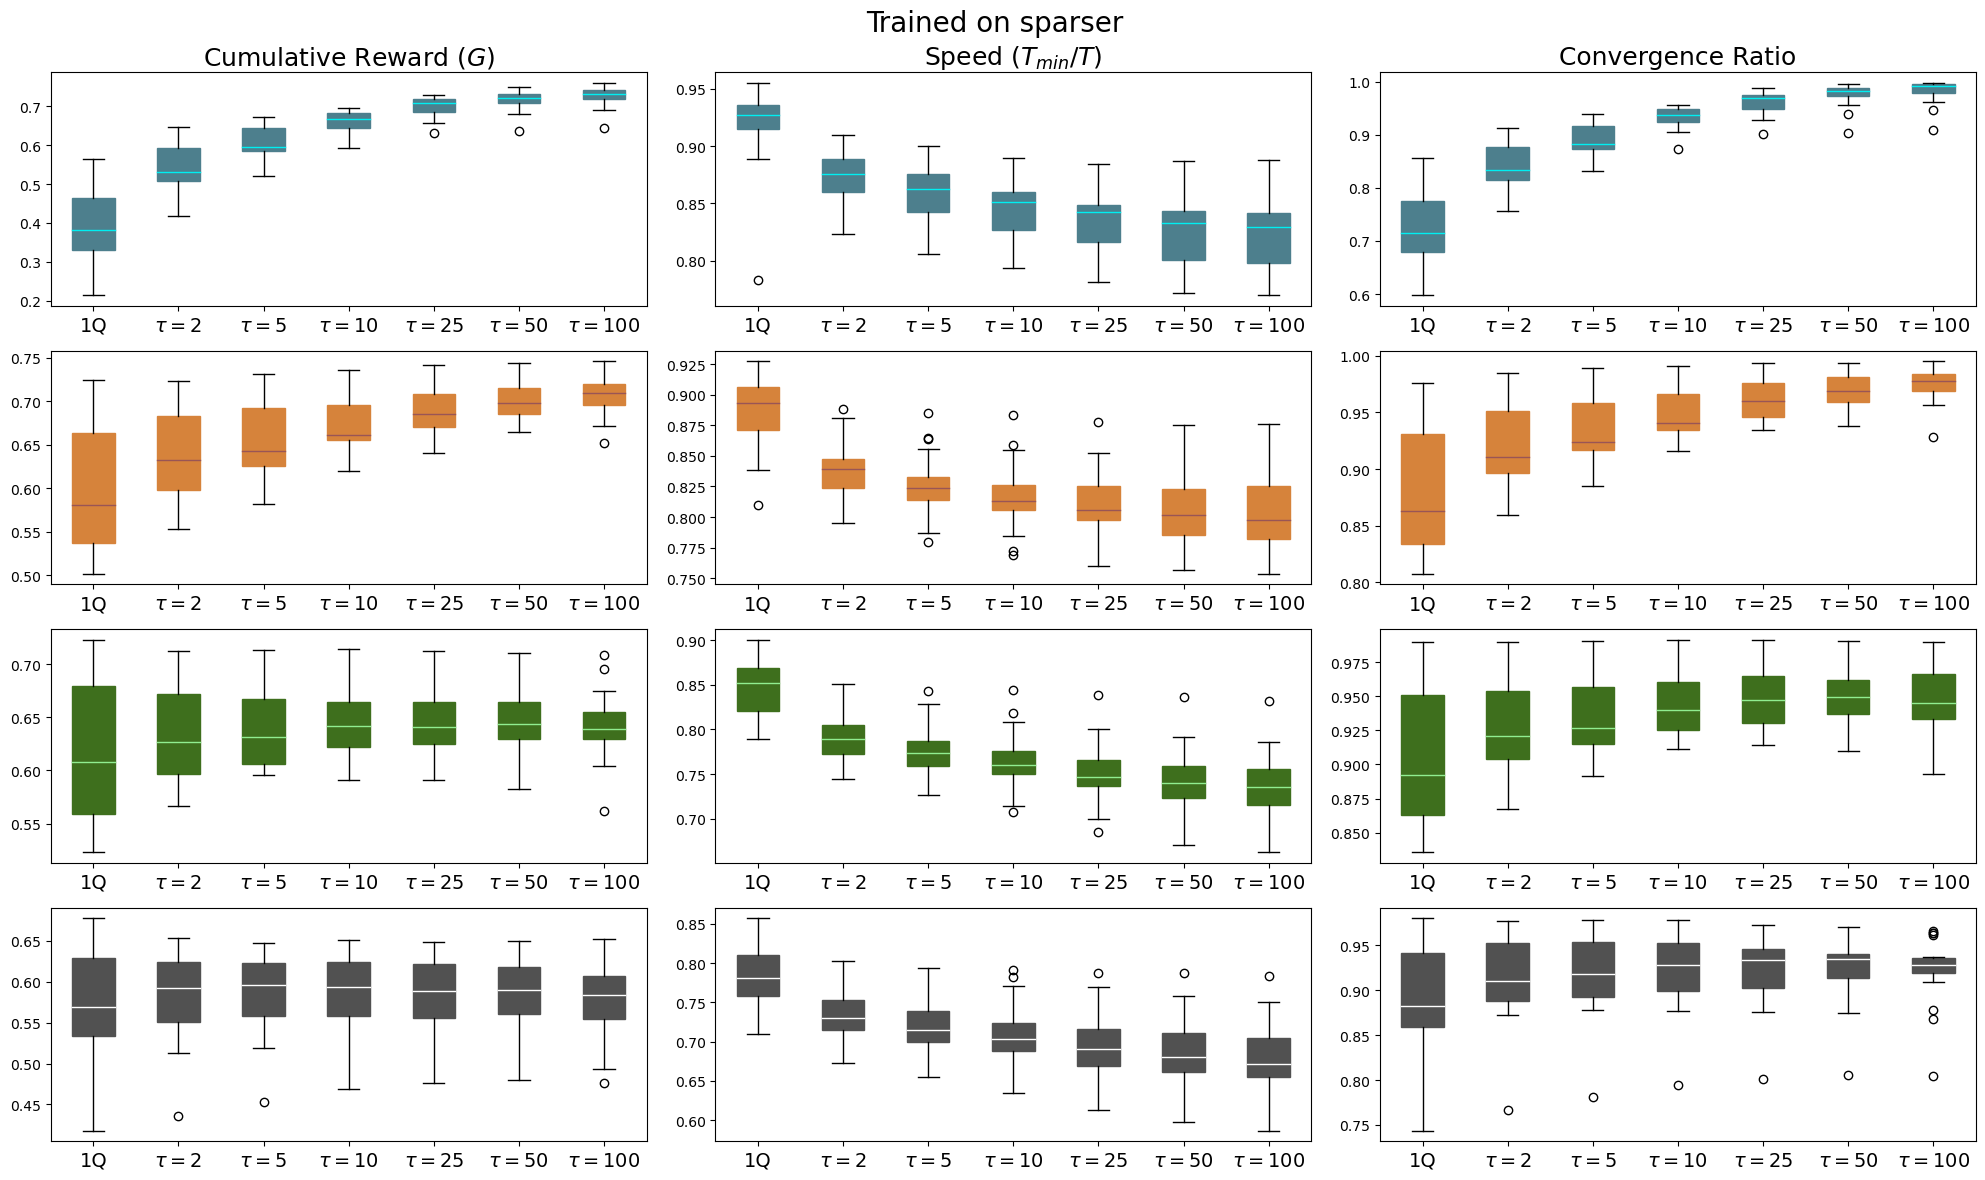

In [71]:
base_dir = "/storage/rando/pynav_results_new"

for (i, setting) in enumerate(['dense', 'middle', 'sparse', 'sparser']):
  fig, axes = plt.subplots(4, 3, figsize=(20, 12))
  for setting_idx, test_setting in enumerate(['dense', 'middle', 'sparse', 'sparser']):
    ax = axes[setting_idx]
    creward_data, speed_data, conv_data = [],[],[]
    c_rewards = []
    speeds = []
    convergence = []

    tick_labels = ['1Q'] + [f'$\\tau = {tau}$' for tau in taus]

    for seed in agent_seeds:
      with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{test_setting}/test_summary.log", 'r') as f:
        splitted = f.readline().split(',')
        c_rewards.append(float(splitted[0]))
        speeds.append(float(splitted[2]))
        convergence.append(float(splitted[4]))

    creward_data.append(c_rewards)
    speed_data.append(speeds)
    conv_data.append(convergence)

    for tau in taus:
      c_rewards = []
      speeds = []
      convergence = []
      for seed in agent_seeds:
        with open(f"{base_dir}/two_single_Q/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log", 'r') as f:
          splitted = f.readline().split(',')
          c_rewards.append(float(splitted[0]))
          speeds.append(float(splitted[2]))
          convergence.append(float(splitted[4]))

      creward_data.append(c_rewards)
      speed_data.append(speeds)
      conv_data.append(convergence)


    fig.suptitle(f"Trained on {setting}", fontsize=20)
    b1 = ax[0].boxplot(creward_data,  patch_artist=True)
    b2 = ax[1].boxplot(speed_data,  patch_artist=True)
    b3 = ax[2].boxplot(conv_data,  patch_artist=True)

    for i in range(len(b1['boxes'])):
        b1['boxes'][i].set_color(box_colors[setting_idx])
        b1['medians'][i].set_color(median_colors[setting_idx])
        b2['boxes'][i].set_color(box_colors[setting_idx])
        b2['medians'][i].set_color(median_colors[setting_idx])
        b3['boxes'][i].set_color(box_colors[setting_idx])
        b3['medians'][i].set_color(median_colors[setting_idx])

    for i in range(len(ax)):
        ax[i].set_xticks(ticks=range(1, len(taus) + 2), labels=tick_labels, fontsize=14)
#    ax[0].set_ylim([0.3, 0.8])
    if setting_idx == 0:
      ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
      ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
      ax[2].set_title("Convergence Ratio", fontsize=18)

  fig.tight_layout()
  fig.savefig(f"{out_path}/performance/tau_comparison_{setting}.pdf", bbox_inches='tight')
#  plt.close(fig)
